In [55]:
#run this everytime an edit is made in utils.py so that we can use the helper functions in this Python Notebook
import importlib
import project_utils
importlib.reload(project_utils)

<module 'project_utils' from '/Users/ivychan/finm-367/FINM_Portfolio_GroupB/ivy-work/project_utils.py'>

# Risk Parity

## Project Statement

On December 13, 2019 the RPAR Risk Parity ETF listed, the first fund to sell "balanced risk across asset classes" to anyone with a brokerage account. Three months later it met the March 2020 volatility shock. On January 4, 2022 its levered sibling UPAR listed, at the start of the deepest drawdown in RPAR's record. On March 6, 2025 Bridgewater, whose All Weather fund originated the idea in 1996, listed its own ETF, ALLW. The file also holds NTSX, a levered 90/60 stock-bond fund, DBMF, a managed-futures fund, and the asset-class ETFs from which every one of these can be rebuilt back to 2008.

You are an allocator at the October 23, 2026 close choosing among these products and a construction of your own. Measure what each product is, decompose what it holds, build the strategy over a longer history than any live fund has, test what broke it in 2020 and 2022, and recommend.


## Context

| Fund | First trading day | Strategy | Annual expense |
|---|---|---|---:|
| RPAR Risk Parity ETF | 2019-12-13 | Four asset classes, each at 25% of target risk | 0.52% |
| UPAR Ultra Risk Parity ETF | 2022-01-04 | 1.4 times the RPAR Index's exposures | 0.68% |
| SPDR Bridgewater All Weather ETF (`ALLW`) | 2025-03-06 | Active allocation across stocks, nominal bonds, inflation-linked bonds, and commodities | 0.85% |
| WisdomTree U.S. Efficient Core Fund (`NTSX`) | 2018-08-02 | About 90% U.S. equities and 60% Treasury-futures notional | 0.20% |
| iMGP DBi Managed Futures Strategy ETF (`DBMF`) | 2019-05-08 | Long and short futures positions, rebalanced weekly | 0.85% |

Additional exposure details:

- **RPAR:** the index allocation is 35% TIPS, 25% global equities, 25% commodities, and 15% Treasuries implemented with bills collateralizing Treasury futures.
- **UPAR:** total exposure is 160% to 180% of net asset value.
- **ALLW:** derivative notional may exceed NAV; reported notional was 187% on October 23, 2026. Bridgewater's All Weather strategy dates to 1996.
- **NTSX:** the Treasury sleeve targets 3- to 8-year duration.
- **DBMF:** estimates the positioning of the 20 leading managed-futures funds in the SG CTA Index.

Use two daily-rebalanced benchmarks: **60/40**, with 60% `SPY` and 40% `IEF`; and a **four-asset portfolio**, with 25% each in `SPY`, `TLT`, `GLD`, and `DBC` (the *static four-way* in the calculations below).

Fund facts: issuer pages and prospectuses, October 26, 2026. Fund returns are net of fees. The file begins on each fund's first trading day; inception dates may be one day earlier.


## Data

| File | Sheets | Frequency | Sample |
|---|---|---|---|
| `data/project_risk_parity_20261023.xlsx` | `descriptions`, `total return index`, `daily returns`, `monthly returns`, `yields`, `data source` | daily; monthly from month-end levels, full months only | daily 2002-07-26 to 2026-10-23; monthly 2002-08 to 2026-09; yields to 2026-07-31 |

The return sheets contain simple total returns for the five funds and the asset-class ETFs `SPY`, `TLT`, `IEF`, `TIP`, `GLD`, `DBC`, `AGG`, and the cash funds `SHV` and `BIL`, derived from gross-dividend total-return indexes. A series is blank before the fund existed. `RPARTR` (RPAR's benchmark, a price index), `RSSB`, `RSST` and `PRPFX` are in the file for reference; no question uses them. The `yields` sheet holds 2-, 10- and 30-year zero-coupon Treasury yields in percent (Federal Reserve Board, Gurkaynak-Sack-Wright).

#### Notes

- Returns are daily, close to close, simple total returns on `SPY`'s calendar. Annualize with 252 days or 12 months: a mean by the count, a volatility by its square root.
- Cash is `SHV`; an excess return subtracts `SHV`'s return over the same period. Sharpe ratios use excess returns; drawdowns, skewness, VaR and CVaR use total returns.
- A portfolio levered $L$ times borrows at `SHV`: $r^{L}_t = r^f_t + L\,(r_t - r^f_t)$. Ignore transaction costs and financing spreads until Section 7 declares them.
- A wealth index for a drawdown equals 1 at the close before the window's first return, so a loss on the first day counts.
- VaR and CVaR are returns at the 5% level over one day unless a question says otherwise. A forecast for day $t$ uses data through $t-1$.
- Historical-simulation forecasts begin after a 252-day burn-in. EWMA uses a zero mean, seeds $\sigma^2$ with the variance of the first 21 returns, and forecasts from the 22nd day.
- A weight or signal set at the close of month $t-1$ acts in month $t$.
- One-way turnover at a rebalance is half the sum of absolute position changes, with positions as fractions of net asset value, so including leverage.


## Data Preview


In [56]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('project_risk_parity_20261023.xlsx')
descriptions = pd.read_excel(DATA, sheet_name='descriptions').set_index('ticker')
levels = pd.read_excel(DATA, sheet_name='total return index', index_col='Date', parse_dates=True)
returns = pd.read_excel(DATA, sheet_name='daily returns', index_col='Date', parse_dates=True)
monthly = pd.read_excel(DATA, sheet_name='monthly returns', index_col='Date', parse_dates=True)
yields = pd.read_excel(DATA, sheet_name='yields', index_col='Date', parse_dates=True)

print(f'{returns.shape[1]} series, {returns.index[0].date()} to {returns.index[-1].date()}; yields to {yields.index[-1].date()}')
preview_funds = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
coverage = pd.DataFrame({
    'First return': returns[preview_funds].apply(pd.Series.first_valid_index).dt.strftime('%Y-%m-%d'),
    'Last return': returns[preview_funds].apply(pd.Series.last_valid_index).dt.strftime('%Y-%m-%d'),
    'Daily observations': returns[preview_funds].count(),
})
coverage.index.name = 'Fund'
display(coverage.style.format({'Daily observations': '{:,.0f}'}, na_rep='—').set_caption('Available daily fund returns'))


18 series, 2002-07-29 to 2026-10-23; yields to 2026-07-31


,First return,Last return,Daily observations
Fund,,,
RPAR,2019-12-16,2026-10-23,"1,723"
UPAR,2022-01-05,2026-10-23,"1,205"
ALLW,2025-03-07,2026-10-23,411
NTSX,2018-08-03,2026-10-23,"2,053"
DBMF,2019-05-09,2026-10-23,"1,876"


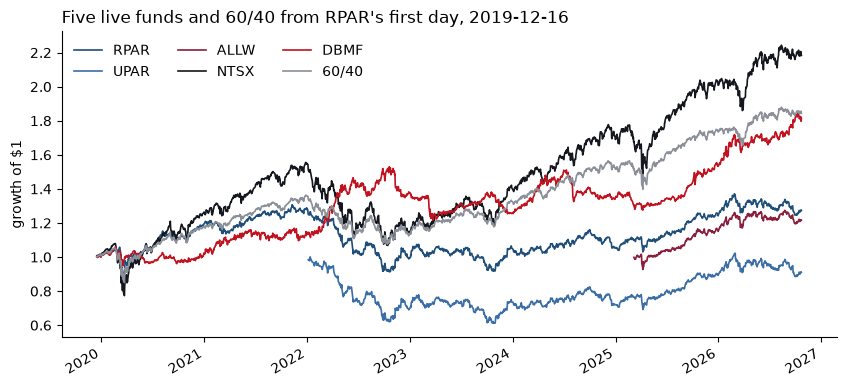

In [57]:
LIVE = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
returns['60/40'] = 0.6 * returns['SPY'] + 0.4 * returns['IEF']
returns['static four-way'] = 0.25 * (returns['SPY'] + returns['TLT'] + returns['GLD'] + returns['DBC'])

fig, ax = plt.subplots(figsize=(10, 4.5))
growth = (1 + returns.loc['2019-12-16':, LIVE + ['60/40']]).cumprod()
growth.plot(ax=ax, color=['#1f4e79', '#3b6ea5', '#8a1f3d', '#14181e', '#c1121f', '#8a8f98'], lw=1.2)
ax.set_ylabel('growth of $1'); ax.set_xlabel('')
ax.set_title('Five live funds and 60/40 from RPAR\'s first day, 2019-12-16', loc='left')
ax.legend(frameon=False, ncol=3); ax.spines[['top', 'right']].set_visible(False)
plt.show()


***


# 1. The Products


## 1.1

For `RPAR`, `UPAR`, `ALLW`, `NTSX`, `DBMF`, 60/40 and the static four-way, report over 2019-12-16 to 2026-10-23 and over 2022-01-05 to 2026-10-23:

* annualized mean and volatility, Sharpe ratio, skewness
* empirical 5% VaR and CVaR of daily returns
* maximum drawdown with its peak, trough and recovery dates
* calendar-year total returns for 2020 through 2026 to date, adding `SPY`, `TLT`, `TIP`, `GLD` and `DBC`

A fund that launched after a window opens starts later; mark it in the table.


In [58]:
FUNDS = LIVE + ["60/40", "static four-way"]

windows = {"2019-12-16 to 2026-10-23": returns.loc["2019-12-16":"2026-10-23"],
           "2022-01-05 to 2026-10-23": returns.loc["2022-01-05":"2026-10-23"]}

product_stats = {}

for window, df in windows.items():
    stats = project_utils.performance_stats(df[FUNDS], df["SHV"])

    #mark funds that launched after the window opens
    late = stats["First Return"] > df.index[0]
    stats.index = [f"{fund}*" if is_late else fund for fund, is_late in late.items()]

    product_stats[window] = stats

product_stats = pd.concat(product_stats, names = ["Window", "Fund"])

def format_date(x):
    return x.strftime("%Y-%m-%d") if pd.notna(x) else "Not recovered"

display(product_stats.style.format({"First Return": format_date,
                                    "Annualized Mean": "{:.2%}",
                                    "Annualized Volatility": "{:.2%}",
                                    "Sharpe Ratio": "{:.2f}",
                                    "Skewness": "{:.2f}",
                                    "VaR (0.05)": "{:.2%}",
                                    "CVaR (0.05)": "{:.2%}",
                                    "Max Drawdown": "{:.2%}",
                                    "Peak Date": format_date,
                                    "Trough Date": format_date,
                                    "Recovery Date": format_date})
                           .set_caption("* launched after the window opens; statistics start at its first return"))

In [59]:
calendar_cols = FUNDS + ["SPY", "TLT", "TIP", "GLD", "DBC"]

calendar_returns = project_utils.calendar_year_returns(returns.loc["2020-01-01":"2026-10-23", calendar_cols]).T
calendar_returns = calendar_returns.rename(columns = {2026: "2026 YTD"})

#flag partial years for funds that launched mid-year
first_returns = returns[calendar_cols].apply(pd.Series.first_valid_index)
year_starts = returns.loc["2020-01-01":].groupby(returns.loc["2020-01-01":].index.year).apply(lambda x: x.index[0])
partial_years = [f"{fund} {date.year} (from {date.date()})" for fund, date in first_returns.items()
                 if date.year in year_starts.index and date > year_starts[date.year]]

display(calendar_returns.style.format("{:.2%}", na_rep = "—")
                        .set_caption("Calendar-year total returns, 2020 through 2026-10-23"))

print("Partial years: " + "; ".join(partial_years))

Date,2020,2021,2022,2023,2024,2025,2026 YTD
RPAR,19.40%,7.55%,-22.80%,6.03%,0.07%,17.91%,2.53%
UPAR,—,—,-30.27%,5.73%,-2.24%,23.87%,2.06%
ALLW,—,—,—,—,—,15.08%,5.78%
NTSX,24.85%,22.20%,-25.84%,22.70%,20.20%,18.83%,8.71%
DBMF,1.80%,11.38%,21.53%,-8.94%,7.25%,13.84%,18.22%
60/40,16.94%,15.09%,-16.38%,16.98%,14.24%,14.32%,6.32%
static four-way,15.07%,14.49%,-8.29%,8.99%,11.08%,22.51%,12.54%
SPY,18.37%,28.75%,-18.17%,26.19%,24.89%,17.72%,12.32%
TLT,18.15%,-4.60%,-31.24%,2.77%,-8.06%,4.25%,-3.42%
TIP,10.84%,5.67%,-12.24%,3.81%,1.65%,6.77%,-0.03%


Partial years: UPAR 2022 (from 2022-01-05); ALLW 2025 (from 2025-03-07)


## 1.2

Regress `UPAR`'s daily excess return on `RPAR`'s over their common sample. Report

* the slope, the annualized intercept and $R^2$
* the ratio of `UPAR`'s volatility to `RPAR`'s and the ratio of the two maximum drawdowns over the same sample

The issuer describes `UPAR` as a more levered `RPAR`. What multiple do the data support, which of the statistics in 1.1 does it scale, and which does it leave where they were?


In [60]:
excess_returns = returns.sub(returns["SHV"], axis = 0)

#common sample of RPAR and UPAR
common = returns[["RPAR", "UPAR"]].dropna().index

upar_regression = project_utils.regression_stats(excess_returns.loc[common, "UPAR"], excess_returns.loc[common, "RPAR"])
upar_regression = upar_regression.rename({"RPAR": "Slope (beta on RPAR)", "Alpha": "Annualized Intercept"})

#compare the 1.1 statistics for both funds over the same sample
common_stats = project_utils.performance_stats(returns.loc[common, ["RPAR", "UPAR"]], returns.loc[common, "SHV"]).T
common_stats.loc["Annualized Excess Mean"] = excess_returns.loc[common, ["RPAR", "UPAR"]].mean() * 252

ratio_rows = ["Annualized Excess Mean", "Annualized Volatility", "Sharpe Ratio", "Skewness", "VaR (0.05)", "CVaR (0.05)", "Max Drawdown"]
common_stats = common_stats.loc[ratio_rows].astype(float)
common_stats["UPAR / RPAR"] = common_stats["UPAR"] / common_stats["RPAR"]

print(f"Common sample: {common[0].date()} to {common[-1].date()}, {len(common):,} days")

display(upar_regression.to_frame("UPAR on RPAR, daily excess returns")
                       .style.format("{:.4f}")
                       .format("{:.2%}", subset = (["Annualized Intercept", "Tracking Error"], slice(None))))

display(common_stats.style.format("{:.2%}")
                    .format("{:.2f}", subset = (["Sharpe Ratio", "Skewness"], slice(None)))
                    .format("{:.2f}", subset = "UPAR / RPAR")
                    .set_caption("RPAR and UPAR over the common sample"))

Common sample: 2022-01-05 to 2026-10-23, 1,205 days


,"UPAR on RPAR, daily excess returns"
Slope (beta on RPAR),1.2964
Annualized Intercept,-0.45%
Alpha t-stat,-0.1433
R-squared,0.8499
Tracking Error,6.87%


,RPAR,UPAR,UPAR / RPAR
Annualized Excess Mean,-2.80%,-4.09%,1.46
Annualized Volatility,12.68%,17.80%,1.40
Sharpe Ratio,-0.22,-0.23,1.04
Skewness,-0.01,0.10,-7.24
VaR (0.05),-1.33%,-1.80%,1.35
CVaR (0.05),-1.80%,-2.60%,1.44
Max Drawdown,-27.86%,-38.97%,1.40


In [61]:
#re-run the regression on non-overlapping multi-day excess returns to check whether daily timing noise attenuates the slope
horizons = {"1 day": 1, "2 days": 2, "5 days": 5, "21 days": 21}

horizon_regressions = {}

for label, days in horizons.items():
    summed = excess_returns.loc[common, ["RPAR", "UPAR"]].rolling(days).sum().iloc[days - 1::days]
    horizon_regressions[label] = project_utils.regression_stats(summed["UPAR"], summed["RPAR"], periods = 252 / days)

horizon_regressions = pd.DataFrame(horizon_regressions).T.rename(columns = {"RPAR": "Slope", "Alpha": "Annualized Intercept"})

display(horizon_regressions.style.format({"Slope": "{:.2f}",
                                          "Annualized Intercept": "{:.2%}",
                                          "Alpha t-stat": "{:.2f}",
                                          "R-squared": "{:.2f}",
                                          "Tracking Error": "{:.2%}"})
                           .set_caption("UPAR on RPAR by return horizon, non-overlapping excess returns"))

print(f"Correlation of UPAR with RPAR's previous-day excess return: {excess_returns.loc[common, 'UPAR'].corr(excess_returns.loc[common, 'RPAR'].shift(1)):.2f}")

,Slope,Annualized Intercept,Alpha t-stat,R-squared,Tracking Error
1 day,1.30,-0.45%,-0.14,0.85,6.87%
2 days,1.36,-0.30%,-0.15,0.94,4.40%
5 days,1.37,-0.24%,-0.14,0.95,3.76%
21 days,1.39,-0.24%,-0.32,0.99,1.63%


Correlation of UPAR with RPAR's previous-day excess return: 0.09


> **Multiple: about 1.4.** Over the common sample (2022-01-05 to 2026-10-23), `UPAR`'s volatility and maximum drawdown are both 1.40 times `RPAR`'s, matching the issuer's 1.4x. The daily slope is lower (1.30, $R^2$ 0.85) because asynchronous closes attenuate daily betas. When the two funds' closing prices are struck at slightly different moments, part of one day's move shows up in the next day's return, so a daily regression sees less co-movement than there is. Summing over several days puts both halves of the move in the same observation: on non-overlapping 2-, 5- and 21-day returns it rises to 1.36, 1.37 and 1.39, with $R^2$ up to 0.99. The intercept (−0.45% a year, $t$ = −0.14) is indistinguishable from zero.
>
> **What leverage scales:** everything measured in units of return. Excess mean 1.46x, volatility 1.40x, VaR 1.35x, CVaR 1.44x, maximum drawdown 1.40x.
>
> **What it leaves alone:** the Sharpe ratio (−0.22 against −0.23) and skewness (near zero for both). Leverage financed at the cash rate multiplies excess return and volatility by the same factor, so their ratio cannot change.
>
> **What it does not simply scale: the path.** `UPAR` bottomed a year after `RPAR` (2023-10-25 against 2022-10-20), because volatility drag compounds a negative excess return into a longer drawdown.
>
> **The tables.**
>
> * ***RPAR and UPAR over the common sample:*** puts the 1.1 statistics for both funds on the same dates, with their ratio. The 1.4x multiple and the unchanged Sharpe ratio come from here.
> * ***UPAR on RPAR by return horizon:*** our addition. It reruns the regression on 2-, 5- and 21-day returns to test whether the low daily slope is a real multiple or a timing artifact. As the horizon lengthens, the slope rises toward 1.4, so it is an artifact.

## 1.3

From Section 1 alone, write three claims an allocator could defend about how these products differ, each tied to a number in your tables, and name one claim about them you cannot test with these statistics.


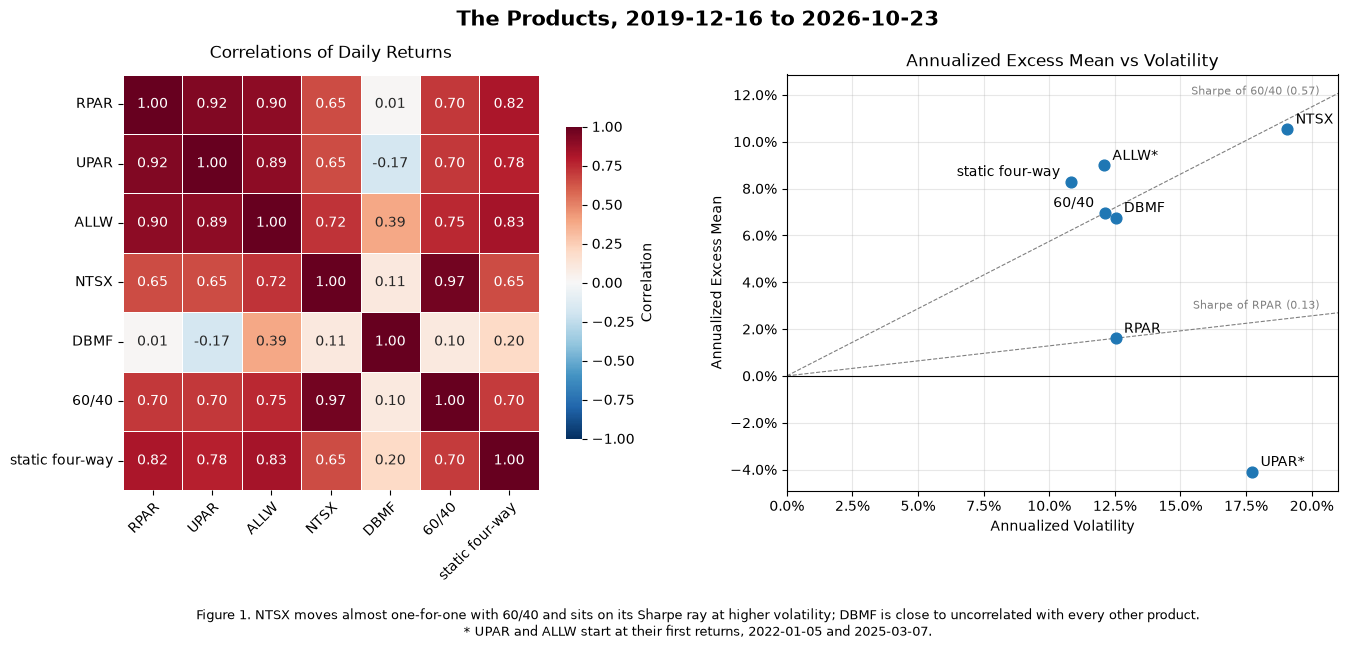

In [62]:
import seaborn as sns
from matplotlib.ticker import PercentFormatter

window_returns = returns.loc["2019-12-16":"2026-10-23", FUNDS]
window_excess = excess_returns.loc["2019-12-16":"2026-10-23", FUNDS]

fig, axes = plt.subplots(1, 2, figsize = (16, 6.5))

#pairwise correlations of daily returns, each pair over its common dates
sns.heatmap(window_returns.corr(), annot = True, fmt = ".2f", cmap = "RdBu_r", vmin = -1, vmax = 1, center = 0, square = True, linewidths = 0.5,
            cbar_kws = {"label": "Correlation", "shrink": 0.75}, ax = axes[0])
axes[0].set_title("Correlations of Daily Returns", fontsize = 12, pad = 12)
axes[0].tick_params(axis = "x", labelrotation = 45)
plt.setp(axes[0].get_xticklabels(), ha = "right", rotation_mode = "anchor")
axes[0].tick_params(axis = "y", labelrotation = 0)

#annualized excess mean against volatility; points on a ray from the origin share a Sharpe ratio
risk_return = pd.DataFrame({"Volatility": window_excess.std() * np.sqrt(252),
                            "Excess Mean": window_excess.mean() * 252})

ax = axes[1]
ax.scatter(risk_return["Volatility"], risk_return["Excess Mean"], s = 60, zorder = 3)

#place labels left of the points that sit close together
left_labels = ["60/40", "static four-way"]

for fund, row in risk_return.iterrows():
    label = f"{fund}*" if fund in ["UPAR", "ALLW"] else fund
    ax.annotate(label, (row["Volatility"], row["Excess Mean"]), xytext = (-8, 4) if fund in left_labels else (6, 4),
                textcoords = "offset points", ha = "right" if fund in left_labels else "left")

vol_grid = np.linspace(0, 0.21, 50)
for fund in ["60/40", "RPAR"]:
    sharpe = risk_return.loc[fund, "Excess Mean"] / risk_return.loc[fund, "Volatility"]
    ax.plot(vol_grid, sharpe * vol_grid, linestyle = "--", linewidth = 0.8, color = "gray")
    ax.annotate(f"Sharpe of {fund} ({sharpe:.2f})", (0.205, sharpe * 0.205), xytext = (-4, 4), textcoords = "offset points", ha = "right", fontsize = 8, color = "gray")

ax.set(title = "Annualized Excess Mean vs Volatility", xlabel = "Annualized Volatility", ylabel = "Annualized Excess Mean", xlim = (0, 0.21))
ax.axhline(0, color = "black", linewidth = 0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha = 0.3)

fig.suptitle("The Products, 2019-12-16 to 2026-10-23", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 1. NTSX moves almost one-for-one with 60/40 and sits on its Sharpe ray at higher volatility; DBMF is close to uncorrelated with every other product.\n"
         "* UPAR and ALLW start at their first returns, 2022-01-05 and 2025-03-07.", ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.24, wspace = 0.25)
plt.show()

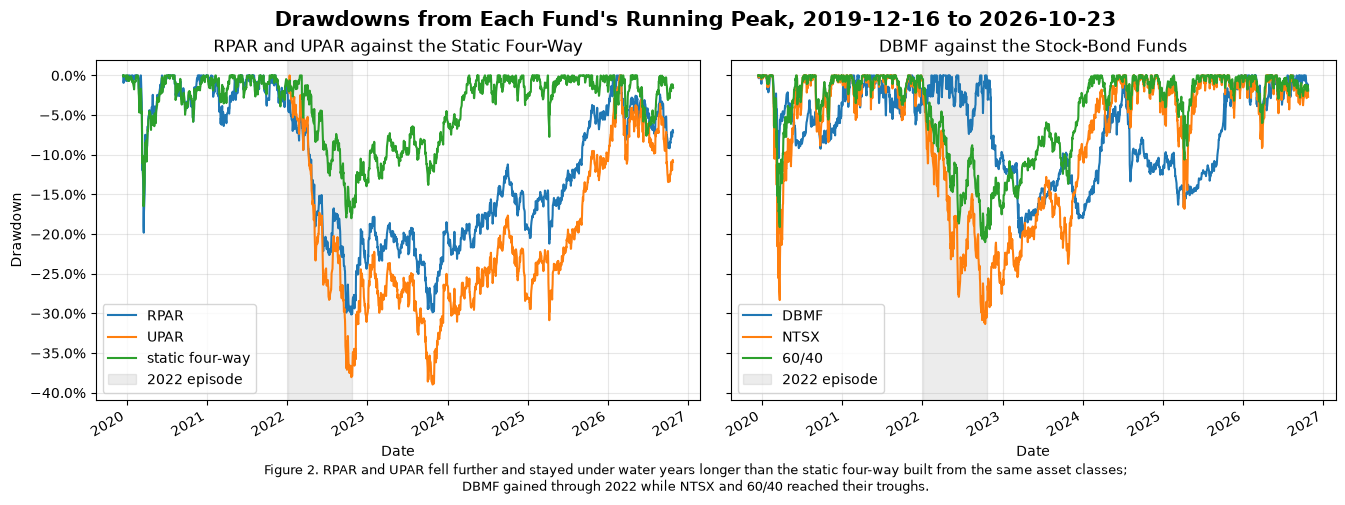

In [63]:
def drawdown_path(returns):
    wealth = (1 + returns.dropna()).cumprod()
    return wealth / wealth.cummax().clip(lower = 1) - 1

fig, axes = plt.subplots(1, 2, figsize = (16, 5), sharey = True)

panels = {"RPAR and UPAR against the Static Four-Way": ["RPAR", "UPAR", "static four-way"],
          "DBMF against the Stock-Bond Funds": ["DBMF", "NTSX", "60/40"]}

for ax, (title, funds) in zip(axes, panels.items()):
    window_returns[funds].apply(drawdown_path).plot(ax = ax, linewidth = 1.5)

    ax.set(title = title, xlabel = "Date", ylabel = "Drawdown")
    ax.axvspan(pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-24"), color = "gray", alpha = 0.15, label = "2022 episode")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(loc = "lower left")
    ax.grid(alpha = 0.3)

fig.suptitle("Drawdowns from Each Fund's Running Peak, 2019-12-16 to 2026-10-23", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 2. RPAR and UPAR fell further and stayed under water years longer than the static four-way built from the same asset classes;\n"
         "DBMF gained through 2022 while NTSX and 60/40 reached their troughs.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.2, wspace = 0.05)
plt.show()

> We made Figure 1 to put the correlations and the risk-return trade-off side by side, and Figure 2 because the claims are about how losses unfolded, which a table of statistics cannot show.
>
> **Claim 1: `NTSX` is a levered 60/40.**
>
> * Correlation 0.97 with 60/40, 1.6 times the volatility (19.1% against 12.1%), and the same Sharpe ratio (0.55 against 0.57).
> * The CAPM relation $\text{SR}_i = \rho\,\text{SR}_m$, with 60/40 as the benchmark, puts its hurdle at $0.97 \times 0.57 = 0.55$, essentially its own Sharpe ratio. Its alpha against 60/40 is about zero.
> * **Figure 1, right panel:** `NTSX` sits on 60/40's dashed Sharpe ray, at a higher volatility. Points on the same ray share a Sharpe ratio, so it is the same trade-off in a larger dose.
>
> **Claim 2: `DBMF` is the only diversifier.**
>
> * Correlation 0.01 with `RPAR` and 0.10 with 60/40. In 2022 it gained 21.5% while `RPAR` lost 22.8% and 60/40 16.4%.
> * Its Sharpe ratio (0.54) is below 60/40's, but a small weight raises 60/40's Sharpe ratio if it exceeds $0.10 \times 0.57 \approx 0.06$. It clears that hurdle by more than any other product.
> * **Figure 1, heatmap:** its row is the only pale one.
> * **Figure 2, right panel:** its drawdown begins on 2022-10-20, just as the stock-bond funds were bottoming, so it was making money exactly when they were losing.
>
> **Claim 3: `RPAR` lagged a naive mix of the same asset classes.**
>
> * The static four-way had a Sharpe ratio of 0.77 against 0.13 and a shallower drawdown (−18.0% against −30.1%), and it recovered almost two years earlier (April 2024 against January 2026).
> * The gap was widest in 2022 (−8.3% against −22.8%).
> * **Figure 2, left panel:** a maximum drawdown is one number, but this claim is about paths. Built from the same asset classes, `RPAR`'s drawdown is roughly two-thirds deeper than the static four-way's and stays under water years longer.
> * The two correlate 0.82. This judges `RPAR` as built over one seven-year record, not the risk-parity rule (Section 4).
>
> **Cannot test: that `RPAR` puts "25% of target risk" in each asset class.** Total returns show how much risk the fund carried, not where it came from; that needs its exposures (Section 2) and their risk contributions. Likewise, `ALLW`'s 0.74 Sharpe ratio rests on 1.6 years, with a standard error of about 0.78.

***


# 2. What They Hold

Sections 2 and 3 use excess returns over `SHV`.


## 2.1

Choose the factor set for the decompositions from `SPY`, `TLT`, `IEF`, `TIP`, `GLD` and `DBC`. State it and justify it in course terms, including whether both Treasury ETFs belong in one regression. Use the same set through Sections 2 and 3 unless a question asks otherwise.


In [64]:
FACTOR_MENU = ["SPY", "TLT", "IEF", "TIP", "GLD", "DBC"]
FACTORS = ["SPY", "TLT", "TIP", "GLD", "DBC"]

menu_excess = excess_returns[FACTOR_MENU].dropna()

factor_samples = {f"{menu_excess.index[0].date()} to {menu_excess.index[-1].date()}": menu_excess,
                  "RPAR's life": menu_excess.loc["2019-12-16":]}

#correlations of daily excess returns across the six candidate factors
factor_corr = pd.concat({sample: df.corr() for sample, df in factor_samples.items()}, axis = 1)

display(factor_corr.style.format("{:.2f}")
                   .background_gradient(cmap = "RdBu_r", vmin = -1, vmax = 1)
                   .set_caption("Correlations of daily excess returns over SHV"))

#variance inflation factors with both Treasury ETFs and with one dropped
menus = {"All six factors": FACTOR_MENU,
         "Without IEF": FACTORS,
         "Without TLT": ["SPY", "IEF", "TIP", "GLD", "DBC"]}

factor_vif = pd.concat({sample: pd.DataFrame({menu: project_utils.variance_inflation(df[cols]) for menu, cols in menus.items()})
                        for sample, df in factor_samples.items()}, axis = 1).loc[FACTOR_MENU]

display(factor_vif.style.format("{:.1f}", na_rep = "—")
                  .set_caption("Variance inflation factors, 1 / (1 - R-squared) of each factor on the others"))

In [65]:
#each fund's full-life daily regression under the three menus
menu_comparison = {}

for fund in LIVE:
    for menu, cols in menus.items():
        stats = project_utils.regression_stats(excess_returns[fund], excess_returns[cols])
        stats["Sum of Betas"] = stats[cols].sum()
        menu_comparison[(fund, menu)] = stats

menu_comparison = pd.DataFrame(menu_comparison).T[["TLT", "IEF", "TIP", "Sum of Betas", "R-squared"]]
menu_comparison.index.names = ["Fund", "Menu"]

display(menu_comparison.style.format("{:.2f}", na_rep = "—")
                       .format("{:.3f}", subset = "R-squared")
                       .set_caption("Treasury and TIPS betas, sum of betas and R-squared by factor menu, daily excess returns over each fund's life"))

> **Factors: `SPY`, `TLT`, `TIP`, `GLD`, `DBC`, with `IEF` dropped.**
>
> * **Why these five:** each is a distinct asset class these funds say they hold, matching `RPAR`'s and `ALLW`'s sleeves. They are also Section 4's five assets, so betas and ERC weights share units. Every VIF is about 2.5 at most.
> * **`TIP` stays despite a 0.70 correlation with `TLT`:** the part of `TIP` that `TLT` does not explain is inflation exposure, `RPAR`'s largest sleeve.
> * **`GLD` and `DBC` both stay:** they correlate only 0.28–0.34 and diverged in 2022, when `DBC` gained 19.3% and `GLD` lost 0.8%.
>
> **Not both Treasuries.**
>
> * `TLT` and `IEF` correlate 0.91. Together their VIFs rise to 6.1–7.4, inflating each beta's standard error by about 1.6x.
> * The second adds nothing for `RPAR`: an `IEF` beta of −0.00, with $R^2$ unchanged at 0.865.
> * For `DBMF` it fits an offsetting curve position (+0.32 `TLT`, −1.33 `IEF`) that would be unstable in rolling fits.
>
> **`TLT` over `IEF`.**
>
> * **Better fit:** `RPAR` 0.865 against 0.839, `UPAR` 0.795 against 0.759. `NTSX` fits marginally better with `IEF` (0.933 against 0.928), and `DBMF` stays below 0.24 under any menu.
> * **A consequence for the sum of betas:** `IEF` is less than half as volatile (6.8% against 15.0%), so the choice changes `RPAR`'s sum of betas from 1.39 to 1.70 (2.4).
>
> **The tables.**
>
> * ***Correlations of daily excess returns over `SHV`:*** the first screen for redundancy, over both the full sample and `RPAR`'s life to check the picture is stable.
>   * `TLT` and `IEF` correlate 0.91, the one pair close to being the same factor.
>   * `TIP`–`TLT` (0.70) and `GLD`–`DBC` (0.28–0.34) are distinct enough to keep.
> * ***Variance inflation factors:*** correlation looks at pairs; the VIF asks how well each factor is explained by all the others together. That is what inflates a beta's standard error, by a factor of $\sqrt{\text{VIF}}$.
>   * With both Treasuries in, their VIFs reach 6.1–7.4.
>   * Dropping `IEF` brings every VIF to about 2.5 at most (2.51 for `TLT` and `TIP` over `RPAR`'s life).
> * ***Treasury and TIPS betas, sum of betas and $R^2$ by factor menu:*** the practical test, whether the choice changes the fit or the betas of the actual funds.
>   * A second Treasury adds no $R^2$ for the risk-parity funds and creates `DBMF`'s offsetting long-short.
>   * `TLT` fits `RPAR` and `UPAR` better than `IEF` does.

## 2.2

Regress each of `RPAR`, `UPAR`, `ALLW`, `NTSX` and `DBMF` on your factor set over its full life, once with daily and once with monthly returns. Report

* the betas and their sum
* the annualized intercept with its $t$-statistic
* $R^2$ and the annualized tracking error


In [66]:
monthly_excess = monthly.sub(monthly["SHV"], axis = 0)

frequencies = {"Daily": (excess_returns, 252), "Monthly": (monthly_excess, 12)}

factor_regressions = {}

for frequency, (df, periods) in frequencies.items():
    for fund in LIVE:
        sample = df[[fund] + FACTORS].dropna()

        stats = project_utils.regression_stats(sample[fund], sample[FACTORS], periods = periods)
        stats["Sum of Betas"] = stats[FACTORS].sum()
        stats["Start"] = sample.index[0].strftime("%Y-%m-%d")
        stats["Observations"] = len(sample)

        factor_regressions[(frequency, fund)] = stats

factor_regressions = pd.DataFrame(factor_regressions).T
factor_regressions = factor_regressions[FACTORS + ["Sum of Betas", "Alpha", "Alpha t-stat", "R-squared", "Tracking Error", "Start", "Observations"]]
factor_regressions = factor_regressions.rename(columns = {"Alpha": "Annualized Intercept", "Tracking Error": "Annualized Tracking Error"})
factor_regressions.index.names = ["Frequency", "Fund"]

display(factor_regressions.style.format("{:.2f}", subset = FACTORS + ["Sum of Betas", "Alpha t-stat", "R-squared"])
                          .format("{:.2%}", subset = ["Annualized Intercept", "Annualized Tracking Error"])
                          .format("{:,.0f}", subset = "Observations")
                          .set_caption("Full-life regressions of fund excess returns on SPY, TLT, TIP, GLD and DBC excess returns over SHV"))

> * **Daily betas are attenuated.** From daily to monthly, the sum of betas rises (`RPAR` 1.39 to 1.53, `UPAR` 1.76 to 2.04, `ALLW` 1.68 to 1.82) and $R^2$ rises from 0.79–0.88 to 0.95–0.99. Asynchronous closes matter less over a month (as in 1.2).
> * **`RPAR` has a significant negative intercept:** −3.55% a year daily ($t$ = −2.01) and −3.00% monthly ($t$ = −2.30), far beyond its 0.52% fee (3.3).
> * **`ALLW`'s monthly intercept is not evidence of skill.** The fit uses 18 months for six parameters. Its 5.17% intercept ($t$ = 3.17) becomes −0.25% ($t$ = −0.08) on 411 daily returns.
> * **`DBMF` is not a fixed mix of these factors:** $R^2$ of 0.16–0.17, tracking error above 10%, and betas summing to about zero.

## 2.3

Repeat the daily regression on a trailing 252-day window, stepped forward 21 trading days at a time.

* Plot each fund's betas, $R^2$ and sum of betas through time, and report the range of each.


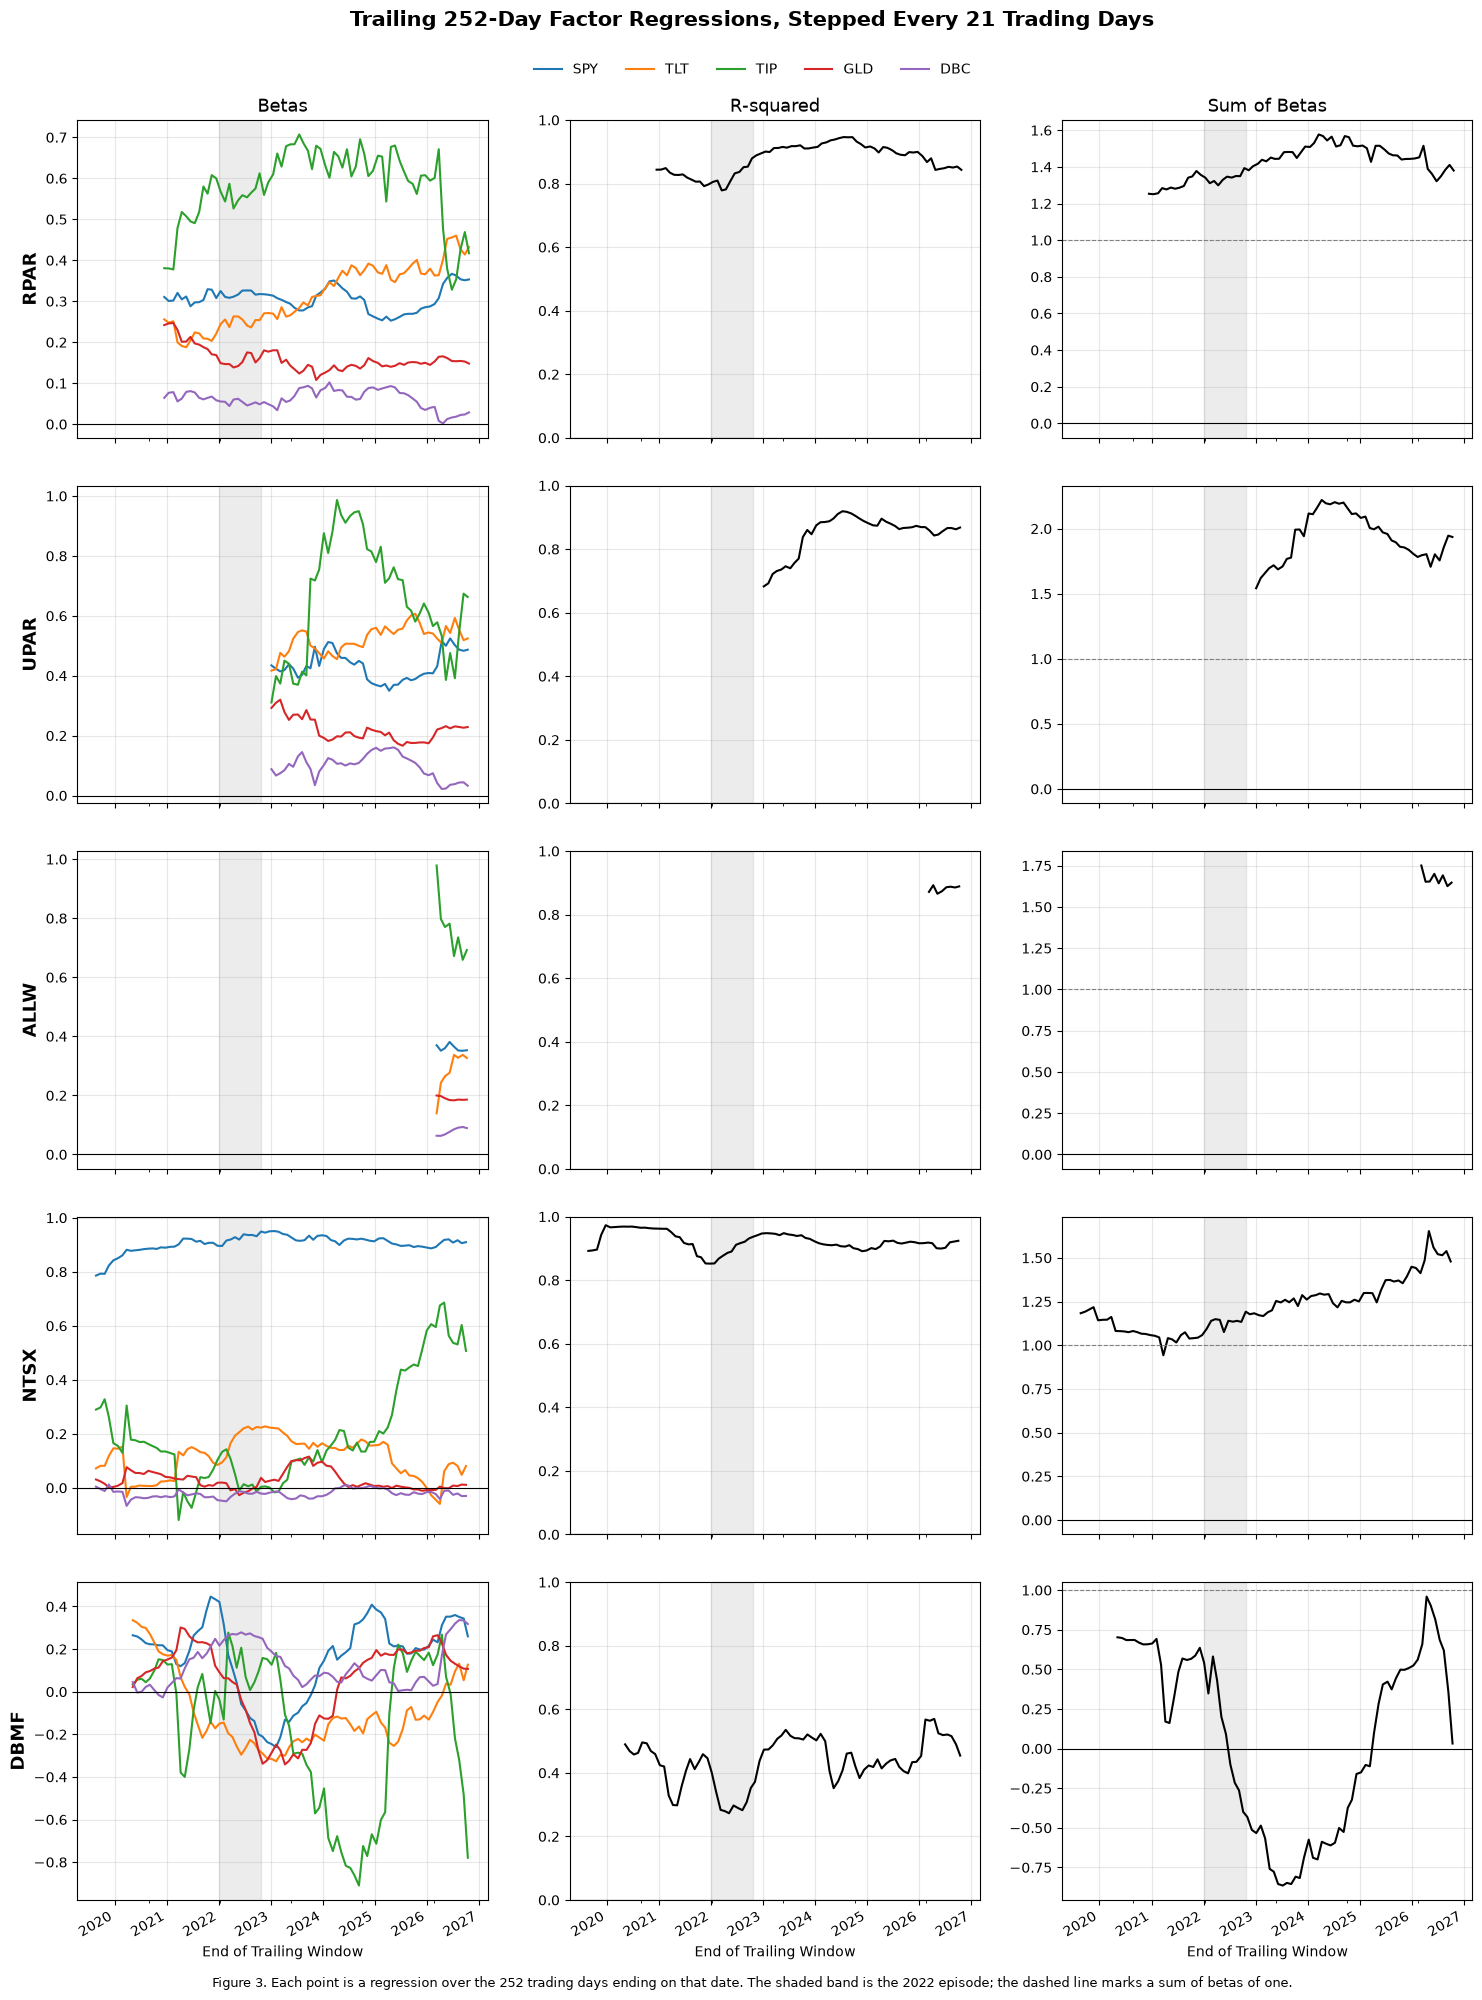

In [67]:
#trailing 252-day daily regressions, stepped forward 21 trading days at a time
rolling_betas = {fund: project_utils.rolling_regression(excess_returns[fund], excess_returns[FACTORS]) for fund in LIVE}

fig, axes = plt.subplots(len(LIVE), 3, figsize = (18, 4 * len(LIVE)), sharex = True)

for row, fund in zip(axes, LIVE):
    rolling = rolling_betas[fund]

    rolling[FACTORS].plot(ax = row[0], linewidth = 1.5, legend = False)
    rolling["R-squared"].plot(ax = row[1], linewidth = 1.5, color = "black")
    rolling["Sum of Betas"].plot(ax = row[2], linewidth = 1.5, color = "black")

    row[0].set_ylabel(fund, fontsize = 13, fontweight = "bold")
    row[1].set_ylim(0, 1)
    row[2].axhline(1, color = "gray", linestyle = "--", linewidth = 0.8)

    for ax in row:
        ax.axhline(0, color = "black", linewidth = 0.8)
        ax.axvspan(pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-24"), color = "gray", alpha = 0.15)
        ax.set_xlabel("End of Trailing Window")
        ax.grid(alpha = 0.3)

for ax, title in zip(axes[0], ["Betas", "R-squared", "Sum of Betas"]):
    ax.set_title(title, fontsize = 13)

fig.legend(FACTORS, loc = "upper center", ncol = len(FACTORS), bbox_to_anchor = (0.5, 0.975), frameon = False)
fig.suptitle("Trailing 252-Day Factor Regressions, Stepped Every 21 Trading Days", fontsize = 15, fontweight = "bold", y = 0.995)

fig.text(0.5, 0.005, "Figure 3. Each point is a regression over the 252 trading days ending on that date. The shaded band is the 2022 episode; the dashed line marks a sum of betas of one.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(top = 0.94, bottom = 0.05, hspace = 0.15, wspace = 0.2)
plt.show()

In [68]:
#range of each rolling statistic across windows
range_cols = FACTORS + ["Sum of Betas", "R-squared"]

rolling_range = pd.DataFrame({fund: rolling[range_cols].agg(["min", "max"]).unstack() for fund, rolling in rolling_betas.items()}).T
rolling_range["Windows"] = pd.Series({fund: len(rolling) for fund, rolling in rolling_betas.items()})

display(rolling_range.style.format("{:.2f}")
                     .format("{:,.0f}", subset = "Windows")
                     .set_caption("Range of trailing 252-day betas, sum of betas and R-squared across windows"))

> Each window is the CAPM lecture's time-varying-beta regression, fitted on the trailing 252 days. $R^2$ shows how well a fixed mix of the factors tracks the fund within that year. Figure 3 plots one row per fund, with its betas, $R^2$ and sum of betas. The question to ask of each row is whether the lines stay flat: flat lines mean a full-sample beta is a fair summary of the fund, and moving lines mean it is not.
>
> * **`RPAR`: stable.**
>   * Sum of betas 1.25–1.58, always above one; $R^2$ 0.78–0.95.
>   * In 2026 its `TLT` and `TIP` betas trade off. That is more likely the regression splitting exposure between two correlated factors than a change in holdings.
> * **`UPAR`: the same mix with more leverage.**
>   * Sum of betas 1.54–2.22.
>   * $R^2$ rises from 0.68 to 0.84–0.87, and the `TIP` beta varies widely (0.31–0.99).
> * **`NTSX`: steady equities, shifting bonds.**
>   * The equity beta stays at 0.79–0.95, with $R^2$ 0.85–0.97.
>   * Its Treasury exposure moves from `TLT` to `TIP` (up to 0.69), consistent with a 3–8-year futures sleeve proxied by correlated bond factors.
> * **`DBMF`: unstable.**
>   * Every beta changes sign, the sum ranges from −0.86 to 0.96, and $R^2$ from 0.27 to 0.57.
>   * Its rolling $R^2$ is above the full-sample 0.16 because each year's fit follows that year's positions.
> * **`ALLW`: too short to judge.**
>   * Only 8 windows. `TIP` beta 0.66–0.98, $R^2$ 0.87–0.89.

## 2.4

State what the sum of betas measures for these funds and how it depends on the choice in 2.1. Show the dependence for one fund by re-running 2.2 under a different menu.


In [69]:
#re-run the 2.2 regressions for RPAR under alternative factor menus
alt_menus = {"Chosen (SPY, TLT, TIP, GLD, DBC)": FACTORS,
             "IEF in place of TLT": ["SPY", "IEF", "TIP", "GLD", "DBC"],
             "Both Treasuries": FACTOR_MENU,
             "Without TIP": ["SPY", "TLT", "GLD", "DBC"]}

menu_sensitivity = {}

for frequency, (df, periods) in frequencies.items():
    sample = df[["RPAR"] + FACTOR_MENU].dropna()
    factor_vol = sample[FACTOR_MENU].std() * np.sqrt(periods)

    for menu, cols in alt_menus.items():
        stats = project_utils.regression_stats(sample["RPAR"], sample[cols], periods = periods)
        stats["Sum of Betas"] = stats[cols].sum()
        #each beta times its factor's volatility: the fund's volatility exposure to each factor, summed
        stats["Sum of Beta x Factor Vol"] = (stats[cols] * factor_vol[cols]).sum()
        menu_sensitivity[(frequency, menu)] = stats

menu_sensitivity = pd.DataFrame(menu_sensitivity).T
menu_sensitivity = menu_sensitivity[FACTOR_MENU + ["Sum of Betas", "Sum of Beta x Factor Vol", "Alpha", "Alpha t-stat", "R-squared", "Tracking Error"]]
menu_sensitivity = menu_sensitivity.rename(columns = {"Alpha": "Annualized Intercept", "Tracking Error": "Annualized Tracking Error"})
menu_sensitivity.index.names = ["Frequency", "Menu"]

display(menu_sensitivity.style.format("{:.2f}", na_rep = "—")
                        .format("{:.2%}", subset = ["Sum of Beta x Factor Vol", "Annualized Intercept", "Annualized Tracking Error"])
                        .set_caption("RPAR's full-life regression under four factor menus"))

> **What it measures.** With excess returns on both sides, each beta is the dollar position in that ETF, financed at `SHV`, that best tracks one dollar of the fund: the lecture's hedge ratio. The sum is net fitted exposure in units of the chosen ETFs, not gross leverage.
>
> * `RPAR`: 1.39 daily (1.53 monthly).
> * `UPAR`: 1.76.
> * `DBMF`: about zero, because its long and short exposures offset.
>
> **Dependence on 2.1 (`RPAR`, daily):**
>
> | Menu | Treasury beta | Sum of betas | $R^2$ | Σ beta × factor volatility |
> |---|---:|---:|---:|---:|
> | Chosen | `TLT` 0.30 | 1.39 | 0.865 | 19.0% |
> | `IEF` in place of `TLT` | `IEF` 0.56 | 1.70 | 0.839 | 18.0% |
> | Without `TIP` | `TLT` 0.46 | 1.08 | 0.834 | 19.5% |
> | Both Treasuries | `IEF` −0.00 | 1.39 | 0.865 | 19.0% |
>
> * **What changes and what doesn't:** the sum ranges from 1.08 to 1.70 while the fit barely moves and the volatility-weighted exposure stays at 18–19.5%. A less volatile proxy simply needs a larger beta for the same risk.
> * **`NTSX` shows the same effect:** with 1.50 notional exposure (90/60), it fits 1.18 with `TLT` and 1.36 with `IEF`.
> * **So the sum compares funds only under a common menu.**

***


# 3. Replication


## 3.1

Replicate each fund out of sample in the ProShares manner: fit on a trailing 252-day window, apply the fit to the next 21 trading days, roll forward. Build two replicas: one fitted with an intercept, which the replica keeps, and one fitted without an intercept. For each fund and each replica report

* the out-of-sample correlation and tracking error
* the annualized mean of the target beside the replica's


In [70]:
#fit on the trailing 252 days, hold the fit for the next 21, roll forward
replicas = {(fund, label): project_utils.oos_replication(excess_returns[fund], excess_returns[FACTORS], intercept = intercept)
            for fund in LIVE for label, intercept in [("With intercept", True), ("No intercept", False)]}

replication_stats = {}

for (fund, label), replica in replicas.items():
    target = excess_returns.loc[replica.index, fund]

    replication_stats[(fund, label)] = {"Start": replica.index[0].strftime("%Y-%m-%d"),
                                        "Days": len(replica),
                                        "Correlation": target.corr(replica),
                                        "Tracking Error": (target - replica).std() * np.sqrt(252),
                                        "Target Mean": target.mean() * 252,
                                        "Replica Mean": replica.mean() * 252}

replication_stats = pd.DataFrame(replication_stats).T
replication_stats["Mean Gap"] = replication_stats["Target Mean"] - replication_stats["Replica Mean"]
replication_stats.index.names = ["Fund", "Replica"]

display(replication_stats.style.format({"Days": "{:,.0f}",
                                        "Correlation": "{:.2f}",
                                        "Tracking Error": "{:.2%}",
                                        "Target Mean": "{:.2%}",
                                        "Replica Mean": "{:.2%}",
                                        "Mean Gap": "{:.2%}"})
                             .set_caption("Out-of-sample replication on SPY, TLT, TIP, GLD and DBC, daily excess returns; means and tracking error annualized"))

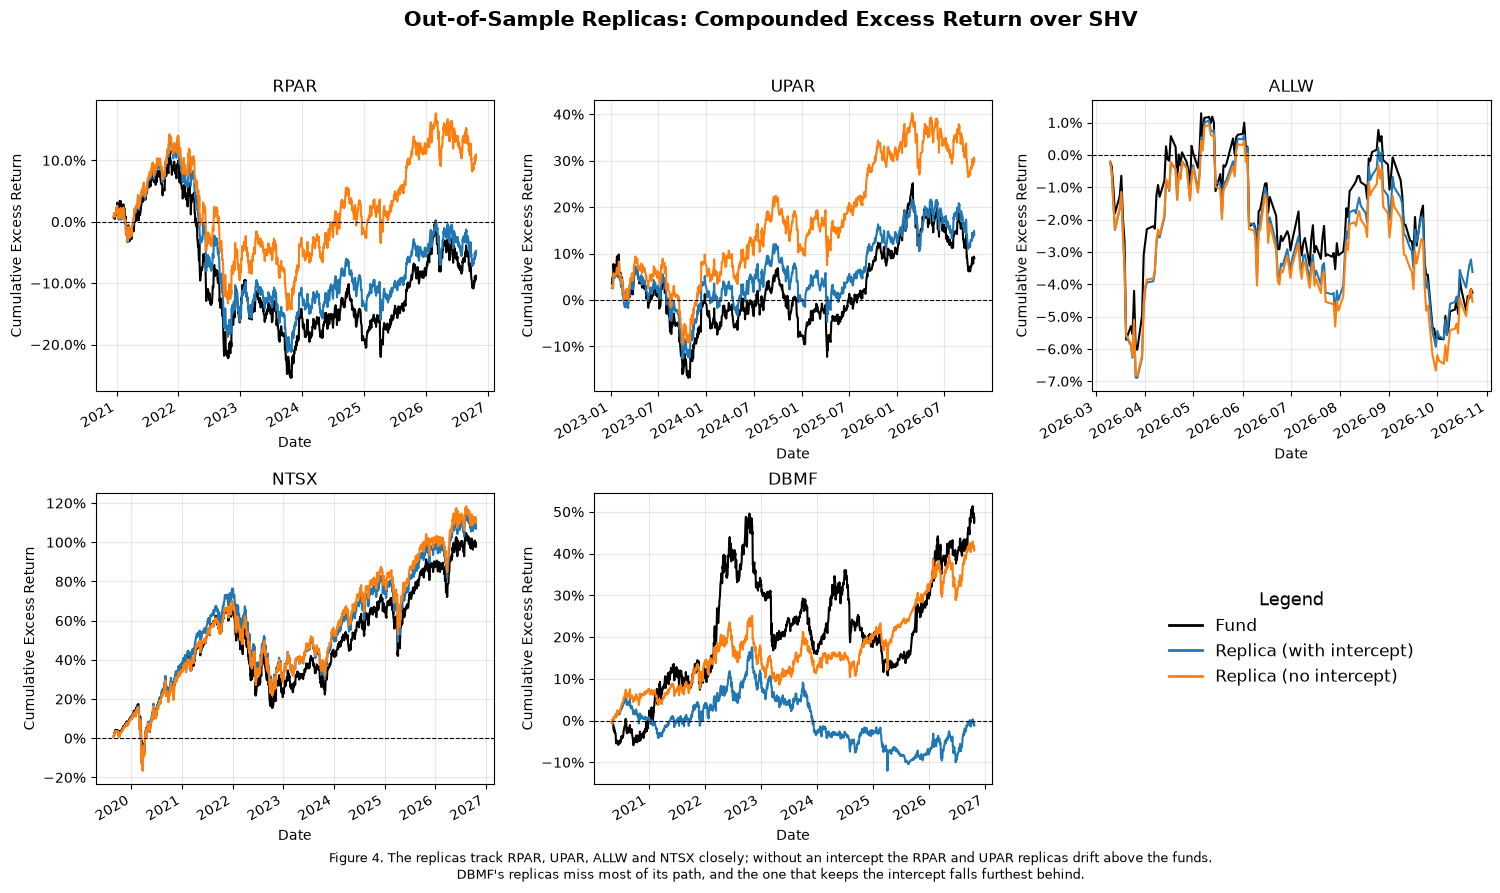

In [71]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(2, 3, figsize = (18, 9))

for ax, fund in zip(axes.flat, LIVE):
    replica_index = replicas[(fund, "With intercept")].index

    cumulative = pd.DataFrame({"Fund": excess_returns.loc[replica_index, fund],
                               "With intercept": replicas[(fund, "With intercept")],
                               "No intercept": replicas[(fund, "No intercept")]})
                               
    cumulative = (1 + cumulative).cumprod() - 1

    cumulative.plot(ax = ax, linewidth = 1.5, color = ["black", "tab:blue", "tab:orange"], legend = False)

    ax.set(title = fund, xlabel = "Date", ylabel = "Cumulative Excess Return")
    ax.axhline(0, color = "black", linestyle = "--", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha = 0.3)

legend_ax = axes.flat[-1]
legend_ax.axis("off")
legend_handles = [Line2D([0], [0], color = "black", lw = 2, label = "Fund"),
                  Line2D([0], [0], color = "tab:blue", lw = 2, label = "Replica (with intercept)"),
                  Line2D([0], [0], color = "tab:orange", lw = 2, label = "Replica (no intercept)")]
legend_ax.legend(handles = legend_handles, loc = "center", frameon = False, fontsize = 12, title = "Legend", title_fontsize = 13)

fig.suptitle("Out-of-Sample Replicas: Compounded Excess Return over SHV", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 4. The replicas track RPAR, UPAR, ALLW and NTSX closely; without an intercept the RPAR and UPAR replicas drift above the funds.\n"
         "DBMF's replicas miss most of its path, and the one that keeps the intercept falls furthest behind.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.12, hspace = 0.35, wspace = 0.25)
plt.show()

> * **The intercept moves the mean, not the fit.** Correlations agree to two decimals between the two replicas, and tracking errors to within 0.02 points. The intercept is a constant within each 21-day block, so it shifts the replica's level but adds almost nothing to its day-to-day movement.
> * **`RPAR`, `UPAR`, `ALLW` and `NTSX` replicate closely:** correlations 0.93–0.96, tracking errors 3.8%–6.0% a year.
> * **For `RPAR` and `UPAR`, the kept intercept captures a persistent shortfall.**
>   * **`RPAR`:** without the intercept, the replica earns 2.31% a year against the fund's −0.90%. That gap of −3.22% is close to the 2.2 intercept. Keeping the intercept narrows it to −0.61%.
>   * **`UPAR`:** the gap narrows from −4.38% to −0.96%.
> * **For `DBMF`, the intercept hurts.**
>   * Correlation is 0.52 and tracking error 10.7%.
>   * The replica with the intercept earns 0.18% against the fund's 6.90%; the one without comes within 1.23%.
>   * Its trailing intercept absorbs exposures that have since reversed.
> * **`ALLW`:** only 159 out-of-sample days.
>
> **Figure 4** separates the two things a replica can get right: whether the wiggles match (correlation) and whether the lines drift apart (the average return). For `RPAR` and `UPAR` the wiggles match, but the no-intercept replica (orange) climbs steadily above the fund (black). That climb is the shortfall measured above. For `DBMF` neither replica follows the 2022 surge.

## 3.2

Which of the five funds does a fixed mix of your factor ETFs replicate out of sample, and which does it not? For the fund it replicates worst, investigate whether the shortfall comes from exposures that move, from factors your menu lacks, or from both. Say what you tested and what it showed.


In [72]:
#trend-following factors built from the menu ETFs plus IEF: 12-month and 3-month lookbacks, signals known at t-1
TREND_ASSETS = FACTORS + ["IEF"]
trend_factors = pd.DataFrame({"Trend 12m": project_utils.trend_factor(excess_returns[TREND_ASSETS], lookback = 252),
                              "Trend 3m": project_utils.trend_factor(excess_returns[TREND_ASSETS], lookback = 63)})

diagnostic_excess = pd.concat([excess_returns[LIVE + TREND_ASSETS], trend_factors], axis = 1)

diagnostic_menus = {"Menu": FACTORS,
                    "Menu + IEF": FACTORS + ["IEF"],
                    "Menu + IEF + trend": FACTORS + ["IEF", "Trend 12m", "Trend 3m"]}

replica_diagnostics = {}

for fund in ["DBMF", "RPAR"]:
    #full-sample fit: a fixed mix, with and without the missing factors
    static_fit = {f"Full-sample R-squared: {menu}": project_utils.regression_stats(diagnostic_excess[fund], diagnostic_excess[cols])["R-squared"]
                  for menu, cols in diagnostic_menus.items()}

    #exposures free to move each quarter: in-sample fit within non-overlapping 63-day blocks
    block_fit = {f"Median 63-day block adj. R-squared: {menu}": project_utils.block_r_squared(diagnostic_excess[fund], diagnostic_excess[cols]).median()
                 for menu, cols in list(diagnostic_menus.items())[:2]}

    #out-of-sample replicas without intercept, compared on the dates of the 3.1 replica
    oos_dates = replicas[(fund, "No intercept")].index
    oos_variants = {"Menu, 252-day fit, 21-day hold": (FACTORS, 252, 21),
                    "Menu, 63-day fit, 5-day hold": (FACTORS, 63, 5),
                    "Menu + IEF, 252-day fit, 21-day hold": (FACTORS + ["IEF"], 252, 21),
                    "Menu + IEF + trend, 252-day fit, 21-day hold": (FACTORS + ["IEF", "Trend 12m", "Trend 3m"], 252, 21)}

    oos_fit = {}
    for label, (cols, window, step) in oos_variants.items():
        replica = project_utils.oos_replication(diagnostic_excess[fund], diagnostic_excess[cols], window = window, step = step, intercept = False)
        replica = replica.reindex(oos_dates)
        oos_fit[f"OOS correlation: {label}"] = diagnostic_excess.loc[oos_dates, fund].corr(replica)

    replica_diagnostics[fund] = pd.Series({**static_fit, **block_fit, **oos_fit})

replica_diagnostics = pd.DataFrame(replica_diagnostics)

display(replica_diagnostics.style.format("{:.2f}")
                           .set_caption("Why DBMF does not replicate: fit with moving exposures and with added factors, RPAR as a control"))

,DBMF,RPAR
Full-sample R-squared: Menu,0.16,0.86
Full-sample R-squared: Menu + IEF,0.24,0.86
Full-sample R-squared: Menu + IEF + trend,0.41,0.87
Median 63-day block adj. R-squared: Menu,0.58,0.86
Median 63-day block adj. R-squared: Menu + IEF,0.58,0.87
"OOS correlation: Menu, 252-day fit, 21-day hold",0.52,0.94
"OOS correlation: Menu, 63-day fit, 5-day hold",0.64,0.93
"OOS correlation: Menu + IEF, 252-day fit, 21-day hold",0.55,0.94
"OOS correlation: Menu + IEF + trend, 252-day fit, 21-day hold",0.61,0.94


> **The fixed mix replicates `RPAR`, `UPAR`, `ALLW` and `NTSX` (3.1) but not `DBMF`:** correlation 0.52, tracking error 10.7%, and it misses the 2022 gain. We tested `DBMF` with `RPAR` as a control.
>
> **The logic of the tests:**
>
> * **If the problem is moving exposures,** letting the betas change should help a lot.
> * **If the problem is missing factors,** no reweighting of the same five ETFs can help, but adding the right factor will.
> * **`RPAR` is the control:** a fund with stable exposures should gain nothing from the extra flexibility.
>
> | Test | `DBMF` | `RPAR` |
> |---|---|---|
> | **Moving exposures:** separate fit in each 63-day block (median adjusted $R^2$, in sample) | 0.16 → 0.58 | 0.86 → 0.86 |
> | **Moving exposures:** 63-day fit, 5-day hold (out-of-sample correlation) | 0.52 → 0.64 | 0.94 → 0.93 |
> | **Missing factor:** add `IEF` (full-sample $R^2$) | 0.16 → 0.24 | — |
> | **Missing factor:** 12- and 3-month trend factors on the menu ETFs (full-sample $R^2$, out-of-sample correlation) | 0.41, 0.61 | — |
>
> **Both, with moving exposures the larger part.**
>
> * Letting the betas move explains far more of `DBMF`, and a trend rule on the same ETFs recovers much of that, consistent with a long-short trend book.
> * Even quarterly fits leave about 42% of its variance unexplained, against 14% for `RPAR`. That points to markets the menu lacks: currencies, foreign equity indices, short-rate futures and single commodities.
> * The block fit is in sample, so these are explanations, not a tradable replica.
>
> **The table.** *Why `DBMF` does not replicate* holds every test above, for both funds, so each number in the summary can be traced to its source. `RPAR`'s column is the control: the tests that help `DBMF` should leave a stable fund unchanged.

## 3.3

For `RPAR`, compute by calendar year the sum of its daily excess returns minus the sum of a replica's, where the replica applies your full-sample daily betas to the factors with no intercept.

* Report the gap by year.
* Propose at least two distinct explanations for its sign and persistence, and state what evidence, in this file or obtainable from the issuer, would separate them.


In [73]:
#replica: RPAR's full-sample daily betas from 2.2 (fitted with an intercept), applied to the factors without the intercept
rpar_sample = excess_returns[["RPAR"] + FACTORS].dropna()
rpar_betas = factor_regressions.loc[("Daily", "RPAR"), FACTORS].astype(float)
rpar_replica = rpar_sample[FACTORS] @ rpar_betas
rpar_gap = rpar_sample["RPAR"] - rpar_replica

#the same replica with the full-sample monthly betas from 2.2, to check whether daily attenuation drives the sign
rpar_monthly_betas = factor_regressions.loc[("Monthly", "RPAR"), FACTORS].astype(float)
rpar_gap_monthly_betas = rpar_sample["RPAR"] - rpar_sample[FACTORS] @ rpar_monthly_betas

#RPAR's total return against its benchmark index, which is a price index (no reinvested income)
rpar_vs_index = (returns["RPAR"] - returns["RPARTR"]).dropna()

years = rpar_gap.index.year
gap_by_year = pd.DataFrame({"Days": rpar_gap.groupby(years).count(),
                            "RPAR": rpar_sample["RPAR"].groupby(years).sum(),
                            "Replica": rpar_replica.groupby(years).sum(),
                            "Gap": rpar_gap.groupby(years).sum(),
                            "Gap t-stat": rpar_gap.groupby(years).mean() / rpar_gap.groupby(years).std() * np.sqrt(rpar_gap.groupby(years).count()),
                            "Gap, monthly betas": rpar_gap_monthly_betas.groupby(years).sum(),
                            "RPAR minus RPARTR": rpar_vs_index.groupby(rpar_vs_index.index.year).sum(),
                            "SPY": rpar_sample["SPY"].groupby(years).sum(),
                            "GLD": rpar_sample["GLD"].groupby(years).sum()})
gap_by_year.index = [f"{year} (partial)" if year in [2019, 2026] else str(year) for year in gap_by_year.index]
gap_by_year.loc["Total"] = gap_by_year.drop(columns = "Gap t-stat").sum()
gap_by_year.loc["Total", "Gap t-stat"] = rpar_gap.mean() / rpar_gap.std() * np.sqrt(len(rpar_gap))

print("Full-sample daily betas, no intercept: " + ", ".join(f"{factor} {beta:.2f}" for factor, beta in rpar_betas.items()))

display(gap_by_year.style.format("{:.2%}")
                   .format("{:,.0f}", subset = "Days")
                   .format("{:.2f}", subset = "Gap t-stat")
                   .set_caption("RPAR minus its replica: sums of daily excess returns by calendar year; SPY and GLD are sums of daily excess returns"))

Full-sample daily betas, no intercept: SPY 0.33, TLT 0.30, TIP 0.54, GLD 0.17, DBC 0.05


,Days,RPAR,Replica,Gap,Gap t-stat,"Gap, monthly betas",RPAR minus RPARTR,SPY,GLD
2019 (partial),11,0.05%,0.29%,-0.25%,-0.20,-0.12%,-0.30%,1.84%,2.67%
2020,253,18.06%,21.51%,-3.45%,-0.55,-4.56%,-2.11%,21.70%,23.27%
2021,252,7.79%,11.81%,-4.02%,-0.97,-5.31%,-1.65%,26.22%,-3.20%
2022,251,-25.45%,-23.33%,-2.12%,-0.40,-0.14%,0.14%,-18.06%,-0.55%
2023,250,1.78%,6.41%,-4.62%,-1.19,-3.79%,-0.63%,19.20%,7.92%
2024,252,-4.38%,3.56%,-7.94%,-2.34,-6.53%,-0.54%,18.02%,19.77%
2025,250,12.91%,14.32%,-1.41%,-0.38,-1.72%,-0.72%,14.05%,47.15%
2026 (partial),204,0.22%,0.69%,-0.46%,-0.11,-1.99%,-0.14%,9.47%,-6.88%
Total,"1,723",10.99%,35.27%,-24.28%,-2.01,-24.15%,-5.94%,92.44%,90.15%


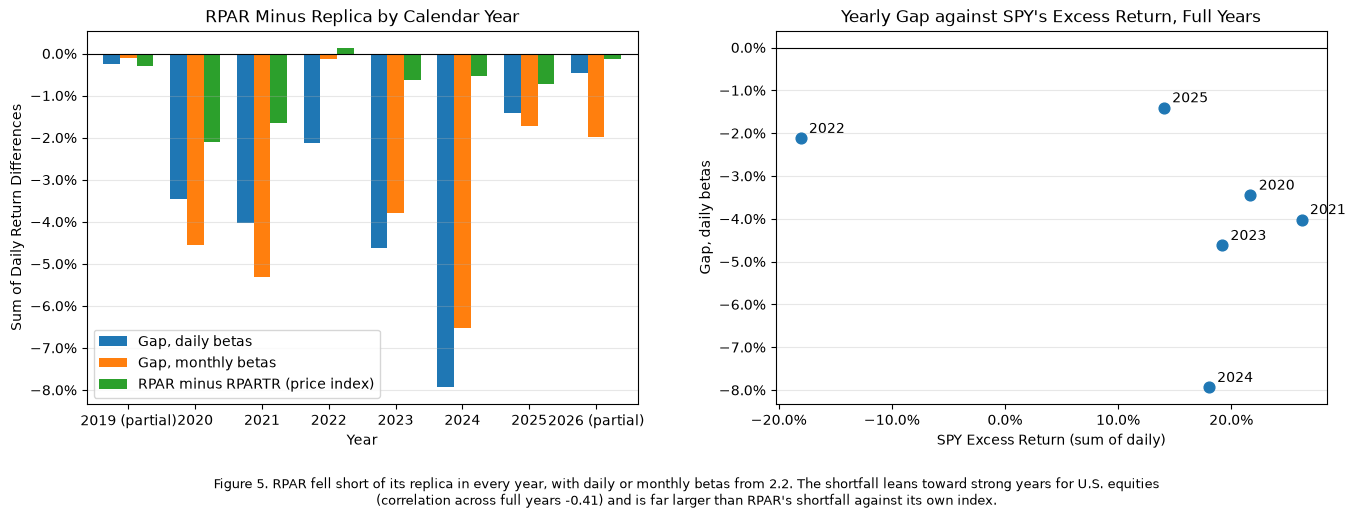

In [74]:
full_years = gap_by_year.drop(["2019 (partial)", "2026 (partial)", "Total"])

fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))

gap_by_year.drop("Total")[["Gap", "Gap, monthly betas", "RPAR minus RPARTR"]].plot(kind = "bar", ax = axes[0], width = 0.75, rot = 0)
axes[0].set(title = "RPAR Minus Replica by Calendar Year", xlabel = "Year", ylabel = "Sum of Daily Return Differences")
axes[0].legend(["Gap, daily betas", "Gap, monthly betas", "RPAR minus RPARTR (price index)"])

axes[1].scatter(full_years["SPY"], full_years["Gap"], s = 60, zorder = 3)
for year, row in full_years.iterrows():
    axes[1].annotate(year, (row["SPY"], row["Gap"]), xytext = (6, 4), textcoords = "offset points")
axes[1].set(title = "Yearly Gap against SPY's Excess Return, Full Years", xlabel = "SPY Excess Return (sum of daily)", ylabel = "Gap, daily betas")
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))

for ax in axes:
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

fig.text(0.5, 0.01, "Figure 5. RPAR fell short of its replica in every year, with daily or monthly betas from 2.2. The shortfall leans toward strong years for U.S. equities\n"
         f"(correlation across full years {full_years['Gap'].corr(full_years['SPY']):.2f}) and is far larger than RPAR's shortfall against its own index.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.2, wspace = 0.25)
plt.show()

> **The gap.**
>
> * `RPAR` fell short of the replica in every year, from −1.4% (2025) to −7.9% (2024). The total is −24.3% ($t$ = −2.01), about −3.5% a year. Only 2024 is significant on its own ($t$ = −2.34).
> * The replica uses the 2.2 betas without the intercept, and OLS residuals sum to zero, so the total equals the 2.2 intercept exactly. The intercept is the part of `RPAR`'s average return that its factor exposures cannot replicate, and this table shows how that shortfall is spread across years.
> * It is not a daily-timing artifact: with the 2.2 monthly betas the gap is negative in every year too (total −24.2%).
>
> **Figure 5** shows both views.
>
> * **Left panel:** the yearly gaps. Blue uses daily betas, orange monthly betas, and green is `RPAR` against its own index. Every blue and orange bar is below zero, and the green bars are much smaller.
> * **Right panel:** each year's gap against `SPY`'s return, the direct test of explanation 1.
>
> **Explanation 1, basis.** `RPAR` holds global equities, commodity-producer equities and Treasury futures, not `SPY`, `DBC` and `TLT`.
>
> * U.S. large caps outran global equities, so a `SPY`-based replica gains most when U.S. equities lead.
> * The support is weak: the yearly gap correlates −0.41 with `SPY`'s excess return, and 2022 (`SPY` −18%) had the second-smallest gap.
>
> **Explanation 2, implementation costs.** The 0.52% fee, rebalancing and futures-roll costs, and financing above `SHV`. These predict a steady drag unrelated to markets.
>
> **What would separate them.**
>
> * **The fund against its own index:** `RPAR` lagged its index `RPARTR` by only 0.9% a year (5.9% in total), against 3.5% a year behind the replica. That points to basis. But `RPARTR` is a price index, so this understates implementation; the issuer's total-return index would settle it.
> * **Sleeve holdings with matching benchmark returns:** these would test basis directly. Under basis, the gap should regress on each sleeve benchmark's return minus `SPY`'s or `DBC`'s, with slopes near the sleeve weights.
>
> **The table.** Beyond the gap itself, the yearly table adds three sets of columns, one for each check in this answer:
>
> * **The gap with monthly betas:** rules out daily timing.
> * **`RPAR` minus `RPARTR`:** splits the gap into fund against index and index against replica.
> * **`SPY`'s and `GLD`'s yearly excess returns:** the market moves that the basis explanation says the gap should follow.

***


# 4. Before It Existed

Cash is `SHV` throughout. Choose and state the estimation window and covariance estimator.


## 4.1

Build three portfolios of `SPY`, `TLT`, `TIP`, `GLD` and `DBC`: inverse variance, inverse volatility, and equal risk contribution. Re-estimate the weights at each month-end from trailing data and hold them through the next month. The backtest begins on 2008-02-01.

* State the estimation window and the covariance estimator.
* For the ERC portfolio, verify at one date that the five risk contributions are equal, and plot its weights through time.

#### Risk Contributions

For weights $\boldsymbol{w}$ on $n$ assets with covariance $\Sigma$, asset $i$'s risk contribution is $\text{RC}_i = w_i\,(\Sigma\boldsymbol{w})_i$, and the contributions sum to the portfolio variance $\boldsymbol{w}'\Sigma\boldsymbol{w}$. Inverse variance sets $w_i \propto 1/\sigma_i^2$, the rule the Harvard case calls risk parity. Inverse volatility sets $w_i \propto 1/\sigma_i$. Equal risk contribution (ERC) sets every $\text{RC}_i$ equal and is solved numerically. When every pair of assets has the same correlation, ERC coincides with inverse volatility; otherwise the three rules differ.


In [75]:
RP_ASSETS = ["SPY", "TLT", "TIP", "GLD", "DBC"]
RP_WINDOW = 252

rules = {"Inverse Variance": project_utils.inverse_variance_weights,
         "Inverse Volatility": project_utils.inverse_vol_weights,
         "ERC": project_utils.erc_weights}

#weights set at each month-end close from the trailing 252-day sample covariance, held through the next month
rp_weights = {name: project_utils.month_end_weights(returns[RP_ASSETS], rule, window = RP_WINDOW, start = "2008-01-31")
              for name, rule in rules.items()}

rp_returns, rp_held = {}, {}
for name, weights in rp_weights.items():
    rp_returns[name], rp_held[name] = project_utils.buy_and_hold_backtest(returns[RP_ASSETS], weights)

rp_returns = pd.DataFrame(rp_returns)

print(f"Rebalances: {len(rp_weights['ERC'])}, first set at {rp_weights['ERC'].index[0].date()}, last at {rp_weights['ERC'].index[-1].date()}")
print(f"Backtest returns: {rp_returns.index[0].date()} to {rp_returns.index[-1].date()}")

Rebalances: 225, first set at 2008-01-31, last at 2026-09-30
Backtest returns: 2008-02-01 to 2026-10-23


In [76]:
#verify the ERC solution at one rebalance date with the same covariance it was solved from
check_date = pd.Timestamp("2020-02-28")
check_cov = returns[RP_ASSETS].dropna().loc[:check_date].iloc[-RP_WINDOW:].cov() * 252

erc_check = project_utils.risk_contributions(rp_weights["ERC"].loc[check_date], check_cov)

display(erc_check.style.format({"Weight": "{:.2%}",
                                "Volatility": "{:.2%}",
                                "Risk Contribution": "{:.6f}",
                                "Share of Variance": "{:.2%}"})
                 .set_caption(f"ERC risk contributions at {check_date.date()}, annualized trailing {RP_WINDOW}-day covariance"))

print(f"Portfolio variance {erc_check['Risk Contribution'].sum():.6f} (volatility {np.sqrt(erc_check['Risk Contribution'].sum()):.2%}); "
      f"largest minus smallest contribution {erc_check['Risk Contribution'].max() - erc_check['Risk Contribution'].min():.1e}")

#the three rules differ because the correlations are not all equal
rule_comparison = pd.DataFrame({name: weights.loc[check_date] for name, weights in rp_weights.items()})

display(rule_comparison.style.format("{:.2%}")
                       .set_caption(f"Weights set by each rule at {check_date.date()}"))

,Weight,Volatility,Risk Contribution,Share of Variance
SPY,20.13%,13.58%,0.000475,20.00%
TLT,16.70%,12.63%,0.000475,20.00%
TIP,36.15%,3.97%,0.000475,20.00%
GLD,13.18%,12.48%,0.000475,20.00%
DBC,13.84%,14.04%,0.000475,20.00%


Portfolio variance 0.002373 (volatility 4.87%); largest minus smallest contribution 1.3e-10


,Inverse Variance,Inverse Volatility,ERC
SPY,6.26%,13.24%,20.13%
TLT,7.23%,14.24%,16.70%
TIP,73.23%,45.30%,36.15%
GLD,7.41%,14.41%,13.18%
DBC,5.86%,12.81%,13.84%


In [77]:
#the one-date check above does not show every month converged: re-solve every 4.1 rebalance date and test the ERC
#condition itself, each asset's share of variance equal to 20%
erc_convergence = project_utils.erc_convergence(returns[RP_ASSETS], rp_weights["ERC"], window = RP_WINDOW)
erc_convergence[["Max Share Deviation", "Max Weight Difference"]] = erc_convergence[["Max Share Deviation", "Max Weight Difference"]].astype(float)

ERC_TOLERANCE = 1e-6

convergence_summary = pd.Series(dtype = object, data = {"Rebalance dates": len(erc_convergence),
                                 "Optimizer reports success": int(erc_convergence["Optimizer Success"].sum()),
                                 "Largest share deviation from 20%, any asset, any date": erc_convergence["Max Share Deviation"].max(),
                                 "Mean across dates of each date's largest deviation": erc_convergence["Max Share Deviation"].mean(),
                                 f"Dates with a deviation above {ERC_TOLERANCE:.0e}": int((erc_convergence["Max Share Deviation"] > ERC_TOLERANCE).sum()),
                                 "Largest difference between re-solved and stored weights": erc_convergence["Max Weight Difference"].max()})

display(convergence_summary.to_frame("ERC convergence").style.format(lambda x: f"{x:.1e}" if isinstance(x, float) else f"{x:,}")
                           .set_caption(f"ERC convergence at every month-end, {erc_convergence.index[0].date()} to {erc_convergence.index[-1].date()}"))

#dates where scipy's flag is not success: the share test decides whether the weights are usable
flagged = erc_convergence.loc[~erc_convergence["Optimizer Success"].astype(bool)]
display(flagged.style.format({"Max Share Deviation": "{:.1e}", "Max Weight Difference": "{:.1e}"})
               .set_caption("Rebalance dates where the optimizer did not report success"))

,ERC convergence
Rebalance dates,225
Optimizer reports success,223
"Largest share deviation from 20%, any asset, any date",3.4e-08
Mean across dates of each date's largest deviation,1.5e-09
Dates with a deviation above 1e-06,0
Largest difference between re-solved and stored weights,0.0e+00


,Optimizer Success,Message,Iterations,Max Share Deviation,Max Weight Difference
2018-02-28 00:00:00,False,ABNORMAL:,12,3.5e-09,0.0e+00
2024-07-31 00:00:00,False,ABNORMAL:,14,3.1e-09,0.0e+00


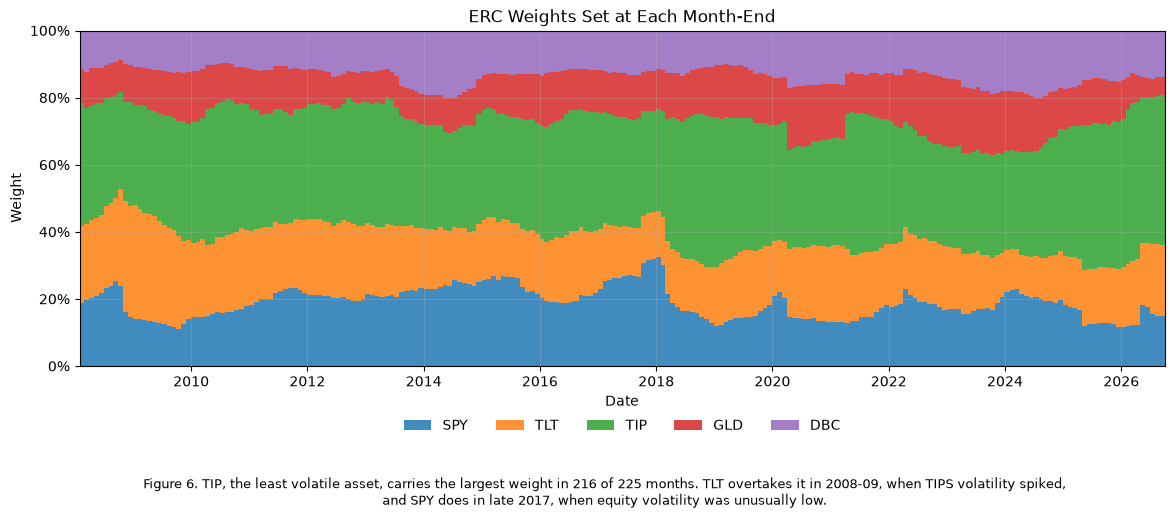

In [78]:
fig, ax = plt.subplots(figsize = (14, 5.5))

erc_plot = rp_weights["ERC"]
ax.stackplot(erc_plot.index, erc_plot.T.to_numpy(), labels = RP_ASSETS, step = "post", alpha = 0.85)

ax.set(title = "ERC Weights Set at Each Month-End", xlabel = "Date", ylabel = "Weight", ylim = (0, 1), xlim = (erc_plot.index[0], erc_plot.index[-1]))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc = "upper center", ncol = len(RP_ASSETS), bbox_to_anchor = (0.5, -0.12), frameon = False)
ax.grid(alpha = 0.3)

fig.text(0.5, 0.01, "Figure 6. TIP, the least volatile asset, carries the largest weight in 216 of 225 months. TLT overtakes it in 2008-09, when TIPS volatility spiked,\n"
         "and SPY does in late 2017, when equity volatility was unusually low.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.27)
plt.show()

> **Window and estimator.**
>
> * **Window:** the trailing 252 daily returns ending at each month-end close. A year balances estimation error in a 5×5 matrix against responsiveness.
> * **Estimator:** the equally weighted sample covariance of total returns. It is practically identical to the excess-return version, and it lets the window start before `SHV` existed.
> * **Holding:** weights act from the next trading day and drift until the next month-end, with 225 rebalances from 2008-01-31.
>
> **ERC verification.**
>
> * **One date (2020-02-28):** each contribution $w_i(\Sigma\boldsymbol{w})_i$ is 0.000475, 20% of the variance of 0.002373. The largest and smallest differ by about $10^{-10}$.
> * **Every date:** re-solving all 225 (and the 236 used in 4.2 and 7.2), no asset's share differs from 20% by more than $3.4\times10^{-8}$, and the stored weights are reproduced exactly.
> * **Optimizer flags:** scipy flags a few dates "ABNORMAL", and which ones varies between runs. Their shares are still within $10^{-8}$ of 20%: the line search stopped at machine precision. The share test, not the flag, is the evidence of convergence.
>
> **Why the rules differ.** At 2020-02-28, `TIP` gets 73% under inverse variance, 45% under inverse volatility and 36% under ERC. ERC cuts `TIP`, whose risk overlaps with `TLT`'s, and raises `SPY` from 13% to 20%, because its low correlation with bonds lowers its marginal risk.
>
> **Weights through time (Figure 6).** ERC sizes each position so that every asset adds the same risk. The least volatile asset therefore gets the most weight, and the weights move whenever relative volatilities do. Figure 6 stacks the month-end weights; an asset's weight is the thickness of its band.
>
> * `TIP` is the largest weight in 216 of 225 months (29%–47%). The ranges for the others: `SPY` 11%–33%, `TLT` 12%–34%, `GLD` 5%–21%, `DBC` 9%–20%.
> * `TLT` overtakes `TIP` in 2008–09, when TIPS volatility spiked, and `SPY` leads in late 2017, when equity volatility was unusually low.
>
> **The tables.**
>
> * ***Weights set by each rule at 2020-02-28:*** shows concretely how ERC departs from inverse volatility once the correlations are unequal.
> * ***The convergence summary and the dates scipy flagged:*** show that every month, not just the one checked, satisfies the ERC condition, and that the flagged dates are a reporting quirk rather than failed solutions.

## 4.2

For the three unlevered rules, 60/40, the static four-way, `SPY` and `TLT`, report annualized mean and volatility, Sharpe ratio and maximum drawdown over the full backtest and the sub-periods before and after 2019-12-13. Also report calendar-year total returns, including 2008, 2013, 2020 and 2022.

Repeat the full-backtest statistics for the ERC rule and 60/40 with the backtest started in 2007, the earliest start the ETFs and your estimation window allow. What moves?


In [79]:
BACKTEST_SERIES = ["Inverse Variance", "Inverse Volatility", "ERC", "60/40", "static four-way", "SPY", "TLT"]
backtest_returns = pd.concat([rp_returns, returns.loc[rp_returns.index, ["60/40", "static four-way", "SPY", "TLT"]]], axis = 1)[BACKTEST_SERIES]

backtest_periods = {f"Full backtest, {backtest_returns.index[0].date()} to {backtest_returns.index[-1].date()}": backtest_returns,
                    "Before RPAR, to 2019-12-12": backtest_returns.loc[:"2019-12-12"],
                    "After RPAR, from 2019-12-13": backtest_returns.loc["2019-12-13":]}

stat_cols = ["Annualized Mean", "Annualized Volatility", "Sharpe Ratio", "Max Drawdown", "Peak Date", "Trough Date", "Recovery Date"]

backtest_stats = pd.concat({period: project_utils.performance_stats(df, returns.loc[df.index, "SHV"])[stat_cols]
                            for period, df in backtest_periods.items()}, names = ["Period", "Strategy"])

backtest_format = {"Annualized Mean": "{:.2%}",
                   "Annualized Volatility": "{:.2%}",
                   "Sharpe Ratio": "{:.2f}",
                   "Max Drawdown": "{:.2%}",
                   "Peak Date": format_date,
                   "Trough Date": format_date,
                   "Recovery Date": format_date}

display(backtest_stats.style.format(backtest_format)
                      .set_caption("Unlevered rules and benchmarks; Sharpe ratios on excess returns over SHV"))

In [80]:
backtest_calendar = project_utils.calendar_year_returns(backtest_returns).T
backtest_calendar = backtest_calendar.rename(columns = {2008: "2008 (Feb-Dec)", 2026: "2026 YTD"})

highlight_years = ["2008 (Feb-Dec)", 2013, 2020, 2022]

display(backtest_calendar.style.format("{:.2%}")
                         .set_properties(subset = highlight_years, **{"font-weight": "bold"})
                         .set_caption("Calendar-year total returns over the backtest; 2008 starts 2008-02-01 and 2026 ends 2026-10-23"))

,2008 (Feb-Dec),2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026 YTD
Inverse Variance,0.30%,4.03%,8.85%,12.64%,6.98%,-6.28%,1.35%,-4.26%,6.39%,6.67%,-1.31%,10.89%,13.00%,6.91%,-11.85%,6.50%,6.80%,9.26%,2.49%
Inverse Volatility,-3.70%,6.17%,12.02%,12.25%,7.29%,-5.91%,1.23%,-6.15%,7.92%,8.78%,-2.24%,13.86%,13.22%,9.44%,-11.16%,7.34%,8.34%,13.44%,6.54%
ERC,-3.21%,3.64%,12.12%,12.95%,7.66%,-3.63%,2.73%,-5.60%,8.29%,10.46%,-1.82%,15.11%,11.59%,9.44%,-11.70%,7.39%,8.72%,13.47%,8.02%
60/40,-14.77%,13.26%,13.46%,8.29%,11.26%,15.61%,11.95%,1.78%,7.80%,13.76%,-1.95%,21.77%,16.94%,15.09%,-16.38%,16.98%,14.24%,14.32%,6.32%
static four-way,-10.63%,11.30%,17.27%,11.75%,7.83%,-6.02%,0.94%,-9.62%,10.69%,12.34%,-4.46%,19.22%,15.07%,14.49%,-8.29%,8.99%,11.08%,22.51%,12.54%
SPY,-32.74%,26.37%,15.06%,1.89%,15.99%,32.31%,13.46%,1.25%,12.00%,21.70%,-4.56%,31.22%,18.37%,28.75%,-18.17%,26.19%,24.89%,17.72%,12.32%
TLT,31.18%,-21.80%,9.05%,33.96%,2.63%,-13.37%,27.30%,-1.79%,1.18%,9.18%,-1.61%,14.12%,18.15%,-4.60%,-31.24%,2.77%,-8.06%,4.25%,-3.42%


In [81]:
#earliest start the ETFs and the 252-day window allow: first full window ends at the 2007-02-28 close
early_erc_weights = project_utils.month_end_weights(returns[RP_ASSETS], project_utils.erc_weights, window = RP_WINDOW)

#the same convergence check as 4.1, on the eleven extra month-ends from 2007-02-28
early_convergence = project_utils.erc_convergence(returns[RP_ASSETS], early_erc_weights, window = RP_WINDOW)
print(f"ERC convergence, {len(early_convergence)} month-ends from {early_convergence.index[0].date()}: "
      f"largest share deviation from 20% {early_convergence['Max Share Deviation'].astype(float).max():.1e}")
early_erc_returns, _ = project_utils.buy_and_hold_backtest(returns[RP_ASSETS], early_erc_weights)

early_returns = pd.DataFrame({"ERC": early_erc_returns,
                              "60/40": returns.loc[early_erc_returns.index, "60/40"]})

start_comparison = pd.concat({f"From {early_returns.index[0].date()}": project_utils.performance_stats(early_returns, returns.loc[early_returns.index, "SHV"])[stat_cols],
                              f"From {backtest_returns.index[0].date()}": backtest_stats.xs(list(backtest_periods)[0]).loc[["ERC", "60/40"]]},
                             names = ["Start", "Strategy"]).swaplevel()
start_comparison = start_comparison.reindex(["ERC", "60/40"], level = "Strategy")

display(start_comparison.style.format(backtest_format)
                        .set_caption("Full-backtest statistics for ERC and 60/40 by start date"))

print("Return from 2007-03-01 to 2008-01-31: " + ", ".join(f"{name} {ret:.2%}" for name, ret in ((1 + early_returns.loc[:"2008-01-31"]).prod() - 1).items()))

ERC convergence, 236 month-ends from 2007-02-28: largest share deviation from 20% 3.4e-08


Return from 2007-03-01 to 2008-01-31: ERC 14.09%, 60/40 4.79%


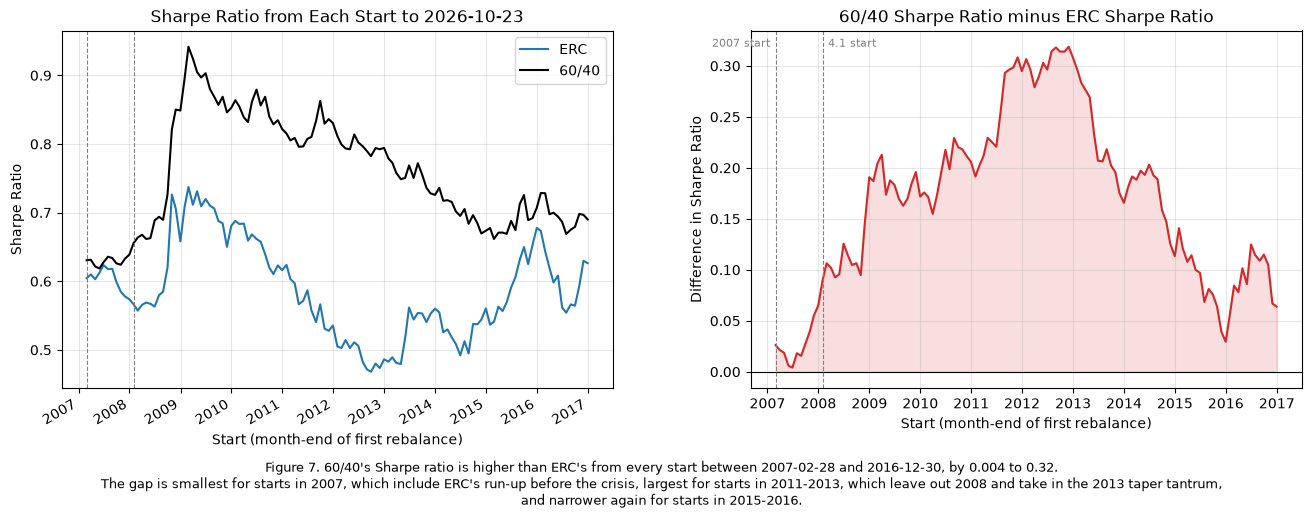

In [82]:
#rerun ERC and 60/40 from every month-end rebalance through 2016, so every sample still runs at least ten years
start_dates = early_erc_weights.loc[:"2016-12-31"].index

start_sharpes = {}
for start in start_dates:
    sample = early_returns.loc[early_returns.index > start]
    sample_excess = sample.sub(returns.loc[sample.index, "SHV"], axis = 0)
    start_sharpes[start] = sample_excess.mean() / sample_excess.std() * np.sqrt(252)

start_sharpes = pd.DataFrame(start_sharpes).T
start_sharpes["60/40 minus ERC"] = start_sharpes["60/40"] - start_sharpes["ERC"]

fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))

start_sharpes[["ERC", "60/40"]].plot(ax = axes[0], linewidth = 1.5, color = ["tab:blue", "black"])
axes[0].set(title = f"Sharpe Ratio from Each Start to {early_returns.index[-1].date()}", xlabel = "Start (month-end of first rebalance)", ylabel = "Sharpe Ratio")

axes[1].plot(start_sharpes.index, start_sharpes["60/40 minus ERC"], linewidth = 1.5, color = "tab:red")
axes[1].fill_between(start_sharpes.index, start_sharpes["60/40 minus ERC"], 0, color = "tab:red", alpha = 0.15)
axes[1].axhline(0, color = "black", linewidth = 0.8)
axes[1].set(title = "60/40 Sharpe Ratio minus ERC Sharpe Ratio", xlabel = "Start (month-end of first rebalance)", ylabel = "Difference in Sharpe Ratio")

#the two starts compared in the table above
for ax in axes:
    for date in [early_erc_weights.index[0], rp_weights["ERC"].index[0]]:
        ax.axvline(date, color = "gray", linestyle = "--", linewidth = 0.8)
    ax.grid(alpha = 0.3)

for date, label, side in [(early_erc_weights.index[0], "2007 start", "right"), (rp_weights["ERC"].index[0], "4.1 start", "left")]:
    axes[1].annotate(label, (date, start_sharpes["60/40 minus ERC"].max()), xytext = (-4 if side == "right" else 4, 0), textcoords = "offset points",
                     ha = side, fontsize = 8, color = "gray")

fig.text(0.5, 0.01, f"Figure 7. 60/40's Sharpe ratio is higher than ERC's from every start between {start_dates[0].date()} and {start_dates[-1].date()}, by {start_sharpes['60/40 minus ERC'].min():.3f} to {start_sharpes['60/40 minus ERC'].max():.2f}.\n"
         "The gap is smallest for starts in 2007, which include ERC's run-up before the crisis, largest for starts in 2011-2013, which leave out 2008 and take in the 2013 taper tantrum,\n"
         "and narrower again for starts in 2015-2016.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.23, wspace = 0.25)
plt.show()

> **Full backtest.**
>
> * **Risk:** unlevered, the three rules run at half to two-thirds of 60/40's volatility (6.3%–7.3% against 11.3%), with drawdowns of −16.6% to −18.0% against −30.8%.
> * **Return:** they earn 4.2%–5.5% a year against 8.9%.
> * **Sharpe ratio:** none matches 60/40's 0.66. ERC reaches 0.57, inverse volatility 0.53, inverse variance 0.44. The more a rule leans on low-volatility `TIP`, the less it earns per unit of risk.
>
> **Sub-periods.**
>
> * **Before 2019-12-13:** ERC 0.62 against 60/40's 0.71.
> * **After:** every rule fell (ERC to 0.50, inverse variance to 0.30) while the static four-way reached 0.77. ERC's 2022 drawdown (−18.0%) matched its 2008 one.
>
> **Key years (Figure 8).** Figure 8 splits each strategy's return in four telling years into contributions by asset, which shows which sleeve carried or sank each rule.
>
> * **2008:** the rules lost at most 3.7% against 60/40's −14.8%. `TLT` carried them (+9.1% for ERC), not TIPS.
> * **2013:** the rules lost 3.6%–6.3% against 60/40's +15.6%, as bonds, TIPS and gold fell together.
> * **2020:** ERC gained 11.6% against 16.9%, with too little equity for the rebound.
> * **2022:** ERC lost 11.7%, less than 60/40 (−16.4%) but more than the static four-way (−8.3%), whose 50% in gold and commodities offset more. `TLT` and `TIP` cost ERC 10.7%.
>
> **Starting in 2007.**
>
> * The eleven extra months (ERC +14.1%, 60/40 +4.8%) raise ERC's Sharpe ratio from 0.57 to 0.60 and cut 60/40's from 0.66 to 0.63. Volatilities and ERC's drawdown barely move.
> * **Why we made Figure 7:** moving the start by eleven months cut the Sharpe gap from 0.09 to 0.03, so one start date could be luck. Figure 7 reruns the comparison from every month-end start from 2007 to 2016. 60/40 stays ahead by 0.004 to 0.32. The ranking never flips, but the size of the gap depends heavily on the start date.

## 4.3

Lever the ERC portfolio, borrowing at `SHV`, to match 60/40's volatility over the full backtest. Report

* the leverage applied
* annualized mean and volatility, Sharpe ratio and maximum drawdown
* one-way turnover per year, counting changes in both weights and leverage


In [83]:
from scipy.optimize import brentq

backtest_rf = returns.loc[backtest_returns.index, "SHV"]
target_vol = backtest_returns["60/40"].std() * np.sqrt(252)

def levered_erc_vol(leverage):
    levered, _, _ = project_utils.levered_backtest(returns[RP_ASSETS], rp_weights["ERC"], returns["SHV"], leverage = leverage)
    return levered.std() * np.sqrt(252)

#one constant leverage, chosen so the levered ERC's full-backtest volatility equals 60/40's
ERC_LEVERAGE = brentq(lambda leverage: levered_erc_vol(leverage) - target_vol, 1, 4)

levered_erc_returns, levered_erc_positions, levered_erc_turnover = project_utils.levered_backtest(returns[RP_ASSETS], rp_weights["ERC"], returns["SHV"], leverage = ERC_LEVERAGE)
_, erc_positions, erc_turnover = project_utils.levered_backtest(returns[RP_ASSETS], rp_weights["ERC"], returns["SHV"], leverage = 1)

backtest_years = len(backtest_returns) / 252

levered_comparison = pd.DataFrame({"Levered ERC": levered_erc_returns,
                                   "ERC": backtest_returns["ERC"],
                                   "60/40": backtest_returns["60/40"]})

levered_stats = project_utils.performance_stats(levered_comparison, backtest_rf)[stat_cols]
levered_stats.insert(0, "Leverage", [ERC_LEVERAGE, 1.0, 1.0])
levered_stats["One-Way Turnover per Year"] = [levered_erc_turnover.sum() / backtest_years, erc_turnover.sum() / backtest_years, np.nan]

print(f"Leverage: {ERC_LEVERAGE:.3f}x, set to match 60/40's full-backtest volatility of {target_vol:.2%}")

display(levered_stats.style.format({**backtest_format, "Leverage": "{:.2f}x", "One-Way Turnover per Year": "{:.2f}"}, na_rep = "—")
                     .set_caption(f"Levered ERC against unlevered ERC and 60/40, {backtest_returns.index[0].date()} to {backtest_returns.index[-1].date()}"))

#leverage just before each reset, after a month of drift
month_end_gross = {date: (levered_erc_positions.loc[date] * (1 + returns.loc[date, RP_ASSETS])).sum() / (1 + levered_erc_returns.loc[date])
                   for date in levered_erc_turnover.index}
month_end_gross = pd.Series(month_end_gross)

#the risky positions drift in proportion with or without leverage, so the weight changes alone cost leverage x the unlevered turnover
weight_turnover = ERC_LEVERAGE * erc_turnover.sum() / backtest_years

print(f"Turnover per year: {levered_erc_turnover.sum() / backtest_years:.2f}, of which weight changes {weight_turnover:.2f} "
      f"and restoring the drifted leverage {levered_erc_turnover.sum() / backtest_years - weight_turnover:.2f}")
print(f"Leverage just before each reset: mean {month_end_gross.mean():.2f}x, range {month_end_gross.min():.2f}x to {month_end_gross.max():.2f}x")

Leverage: 1.555x, set to match 60/40's full-backtest volatility of 11.34%


,Leverage,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown,Peak Date,Trough Date,Recovery Date,One-Way Turnover per Year
Levered ERC,1.55x,7.77%,11.34%,0.56,-27.41%,2008-05-21,2008-10-27,2010-08-02,0.35
ERC,1.00x,5.51%,7.26%,0.57,-17.97%,2022-03-08,2022-10-20,2024-07-16,0.22
60/40,1.00x,8.86%,11.34%,0.66,-30.80%,2008-05-19,2009-03-09,2010-04-23,—


Turnover per year: 0.35, of which weight changes 0.34 and restoring the drifted leverage 0.01
Leverage just before each reset: mean 1.55x, range 1.50x to 1.67x


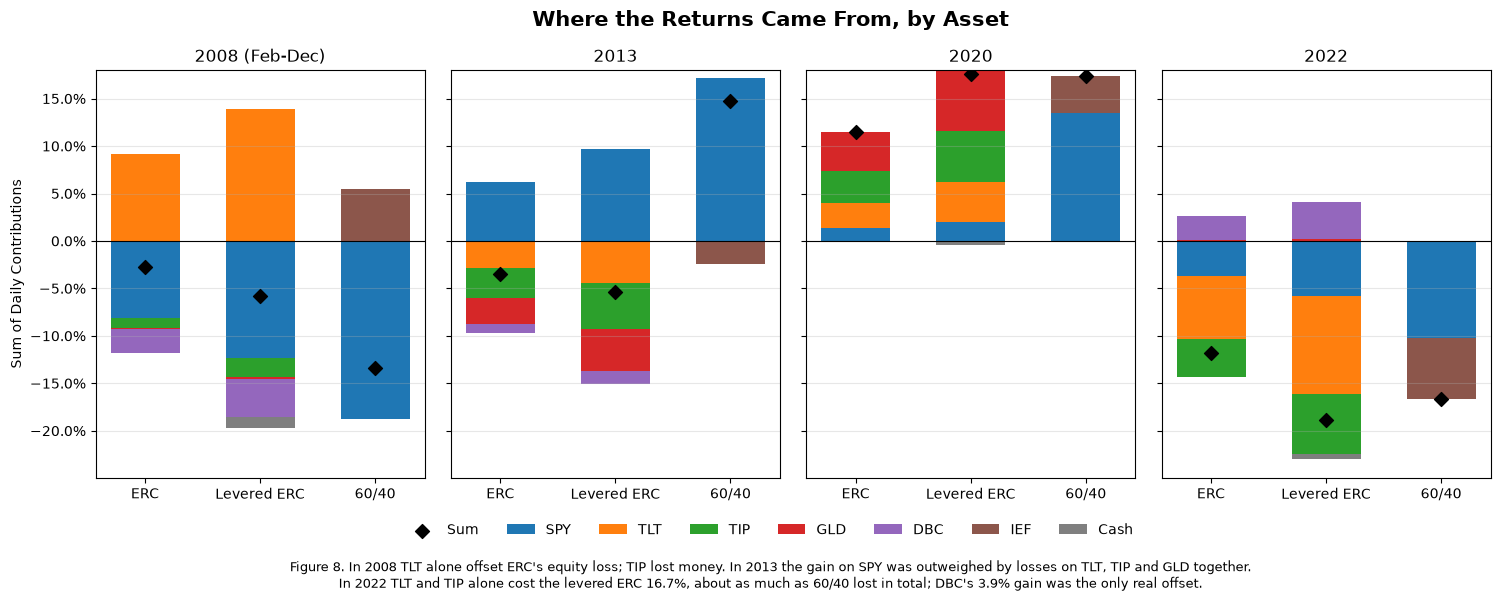

In [84]:
CONTRIBUTION_YEARS = [2008, 2013, 2020, 2022]
CONTRIBUTION_COLS = RP_ASSETS + ["IEF", "Cash"]

#each day's return split by asset: the weight (or position) held at the start of the day times the asset's return;
#Cash is the levered ERC's borrowing cost at SHV, and 60/40 holds 0.6 SPY and 0.4 IEF every day
asset_returns = returns.loc[backtest_returns.index]

contributions = {"ERC": rp_held["ERC"].loc[backtest_returns.index] * asset_returns[RP_ASSETS],
                 "Levered ERC": (levered_erc_positions * asset_returns[RP_ASSETS]).assign(Cash = (1 - levered_erc_positions.sum(axis = 1)) * asset_returns["SHV"]),
                 "60/40": pd.DataFrame({"SPY": 0.6 * asset_returns["SPY"], "IEF": 0.4 * asset_returns["IEF"]})}

#sums of daily contributions by calendar year; they add up to the sum of daily portfolio returns, close to but not equal to the compounded return
contributions_by_year = pd.concat({year: pd.DataFrame({name: df.loc[str(year)].sum() for name, df in contributions.items()}).T
                                   for year in CONTRIBUTION_YEARS}, names = ["Year", "Strategy"])[CONTRIBUTION_COLS]
contributions_by_year["Sum"] = contributions_by_year.sum(axis = 1)
contributions_by_year["Compounded Return"] = [(1 + levered_comparison.loc[str(year), name]).prod() - 1 for year, name in contributions_by_year.index]

display(contributions_by_year.style.format("{:.2%}", na_rep = "—")
                             .set_caption("Sums of daily return contributions by asset in four calendar years (2008 from February)"))

fig, axes = plt.subplots(1, len(CONTRIBUTION_YEARS), figsize = (18, 6), sharey = True)
colors = dict(zip(CONTRIBUTION_COLS, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:gray"]))

for ax, year in zip(axes, CONTRIBUTION_YEARS):
    year_data = contributions_by_year.loc[year].fillna(0)

    #stack gains upward and losses downward from zero
    positive = np.zeros(len(year_data))
    negative = np.zeros(len(year_data))
    for asset in CONTRIBUTION_COLS:
        values = year_data[asset].to_numpy()
        ax.bar(year_data.index, values, bottom = np.where(values >= 0, positive, negative), width = 0.6, color = colors[asset], label = asset)
        positive += np.clip(values, 0, None)
        negative += np.clip(values, None, 0)

    ax.scatter(year_data.index, year_data["Sum"], marker = "D", s = 50, color = "black", zorder = 3, label = "Sum")

    ax.set(title = "2008 (Feb-Dec)" if year == 2008 else str(year), xlabel = "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

axes[0].set_ylabel("Sum of Daily Contributions")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.08), frameon = False)

fig.suptitle("Where the Returns Came From, by Asset", fontsize = 15, fontweight = "bold")

levered_2022 = contributions_by_year.loc[(2022, "Levered ERC")]
fig.text(0.5, 0.01, "Figure 8. In 2008 TLT alone offset ERC's equity loss; TIP lost money. In 2013 the gain on SPY was outweighed by losses on TLT, TIP and GLD together.\n"
         f"In 2022 TLT and TIP alone cost the levered ERC {-levered_2022[['TLT', 'TIP']].sum():.1%}, about as much as 60/40 lost in total; DBC's {levered_2022['DBC']:.1%} gain was the only real offset.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.2, wspace = 0.08)
plt.show()

> **Construction.**
>
> * **Rebalancing:** the portfolio is reset each month to $L$ times the 4.1 ERC weights, borrowing $L - 1$ at `SHV`. Positions drift between resets.
> * **Leverage:** $L$ is chosen on the full backtest to match 60/40's 11.34% volatility, a hindsight choice.
>
> **Results.**
>
> * **Leverage 1.55x:** 1.50x–1.67x after a month of drift.
> * **Return and Sharpe ratio:** 7.77% a year at 11.34% volatility, a Sharpe ratio of 0.56. That is unchanged from the unlevered ERC, as it must be when borrowing at the cash rate, and below 60/40's 0.66. At equal risk, ERC gives up about 1.1% a year.
> * **Maximum drawdown −27.4%** (2008-05 to 2008-10, recovered 2010-08), against 60/40's −30.8%. Leverage gives back most of the drawdown advantage. It scales losses as well as gains: the unlevered ERC's −17.8% drawdown in 2008 becomes −27.4% at 1.55x.
> * **Turnover 0.35 a year:** almost all weight changes (1.55 times the unlevered 0.22); restoring leverage adds 0.01.
> * **2022:** it lost 18.5% against 60/40's 16.4%. `TLT` and `TIP` alone cost it 16.7% (Figure 8, 2022 panel), about what 60/40 lost in total.

## 4.4

Over `RPAR`'s life, compare the ERC weights with `RPAR`'s revealed allocation, its betas from 2.2 scaled to sum to one, and regress `RPAR`'s daily excess return on the levered ERC portfolio's. Report

* the two allocations side by side
* the slope, the annualized intercept with its $t$-statistic, and $R^2$

Does the 2008 to 2019 record change what a reader of Section 1 would conclude? Keep the allocation rule and `RPAR`'s implementation of it separate in the answer.


In [85]:
rpar_dates = excess_returns["RPAR"].dropna().index

#RPAR's revealed allocation: its full-life betas from 2.2 scaled to sum to one
revealed = factor_regressions.loc[(slice(None), "RPAR"), FACTORS].astype(float).droplevel("Fund")
revealed = revealed.div(revealed.sum(axis = 1), axis = 0)

#ERC weights over the same dates: the month-end targets and the drifted weights actually held
#start from the last month-end target set before RPAR's first return, which was held through its first weeks
erc_target_rpar_life = rp_weights["ERC"].loc[rp_weights["ERC"].index[rp_weights["ERC"].index < rpar_dates[0]][-1]:]
erc_held_rpar_life = rp_held["ERC"].loc[rpar_dates]

#RPAR's stated index allocation, with its commodity sleeve split evenly between gold and broad commodities for comparison
stated = pd.Series({"SPY": 0.25, "TLT": 0.15, "TIP": 0.35, "GLD": 0.125, "DBC": 0.125})

allocations = pd.DataFrame({"ERC, mean month-end target": erc_target_rpar_life.mean(),
                            "ERC, mean held": erc_held_rpar_life.mean(),
                            "RPAR revealed, daily betas": revealed.loc["Daily"],
                            "RPAR revealed, monthly betas": revealed.loc["Monthly"],
                            "RPAR index, stated": stated})
allocations.loc["Sum of betas (unscaled)"] = [np.nan, np.nan,
                                              factor_regressions.loc[("Daily", "RPAR"), "Sum of Betas"],
                                              factor_regressions.loc[("Monthly", "RPAR"), "Sum of Betas"],
                                              np.nan]

display(allocations.style.format("{:.1%}", na_rep = "—")
                   .format("{:.2f}", na_rep = "—", subset = (["Sum of betas (unscaled)"], slice(None)))
                   .set_caption(f"ERC weights and RPAR's allocation over RPAR's life, {rpar_dates[0].date()} to {rpar_dates[-1].date()}"))

,"ERC, mean month-end target","ERC, mean held","RPAR revealed, daily betas","RPAR revealed, monthly betas","RPAR index, stated"
SPY,16.6%,16.6%,23.4%,20.4%,25.0%
TLT,17.7%,17.6%,21.9%,25.8%,15.0%
TIP,35.6%,35.4%,39.0%,35.8%,35.0%
GLD,14.8%,14.9%,12.1%,11.2%,12.5%
DBC,15.3%,15.4%,3.6%,6.8%,12.5%
Sum of betas (unscaled),—,—,1.39,1.53,—


In [86]:
levered_erc_excess = (levered_erc_returns - returns["SHV"]).rename("Levered ERC")

#daily regression as asked, and monthly sums of the same daily excess returns to remove the asynchronous-close attenuation (1.2, 2.2)
rpar_erc_daily = pd.concat([excess_returns.loc[rpar_dates, "RPAR"], levered_erc_excess.loc[rpar_dates]], axis = 1)
rpar_erc_monthly = rpar_erc_daily.groupby(rpar_erc_daily.index.to_period("M")).sum().iloc[1:-1]

rpar_on_erc = pd.DataFrame({"Daily": project_utils.regression_stats(rpar_erc_daily["RPAR"], rpar_erc_daily["Levered ERC"]),
                            "Monthly (full months)": project_utils.regression_stats(rpar_erc_monthly["RPAR"], rpar_erc_monthly["Levered ERC"], periods = 12)})
rpar_on_erc = rpar_on_erc.rename({"Levered ERC": "Slope", "Alpha": "Annualized Intercept"})

display(rpar_on_erc.style.format("{:.2f}")
                   .format("{:.2%}", subset = (["Annualized Intercept", "Tracking Error"], slice(None)))
                   .set_caption("RPAR's excess return on the levered ERC portfolio's, over RPAR's life"))

#the rule and RPAR side by side over RPAR's life and over the backtest before it
rule_vs_rpar = pd.concat({"RPAR's life": project_utils.performance_stats(pd.DataFrame({"RPAR": returns.loc[rpar_dates, "RPAR"],
                                                                                      "Levered ERC": levered_erc_returns.loc[rpar_dates],
                                                                                      "60/40": returns.loc[rpar_dates, "60/40"]}),
                                                                        returns.loc[rpar_dates, "SHV"])[stat_cols[:4]],
                          "2008-02-01 to 2019-12-12": project_utils.performance_stats(pd.DataFrame({"Levered ERC": levered_erc_returns.loc[:"2019-12-12"],
                                                                                                   "60/40": returns.loc[levered_erc_returns.loc[:"2019-12-12"].index, "60/40"]}),
                                                                                     returns.loc[levered_erc_returns.loc[:"2019-12-12"].index, "SHV"])[stat_cols[:4]]},
                         names = ["Period", "Strategy"])

display(rule_vs_rpar.style.format(backtest_format)
                    .set_caption("The levered ERC rule and RPAR, each at its own volatility"))

,Daily,Monthly (full months)
Slope,0.85,1.02
Annualized Intercept,-3.79%,-4.56%
Alpha t-stat,-1.65,-2.58
R-squared,0.77,0.89
Tracking Error,6.02%,4.52%


Date,2019 (partial),2020,2021,2022,2023,2024,2025,2026 (partial)
RPAR minus Levered ERC,-0.77%,1.30%,-6.72%,-5.68%,-2.07%,-10.04%,-0.80%,-7.58%


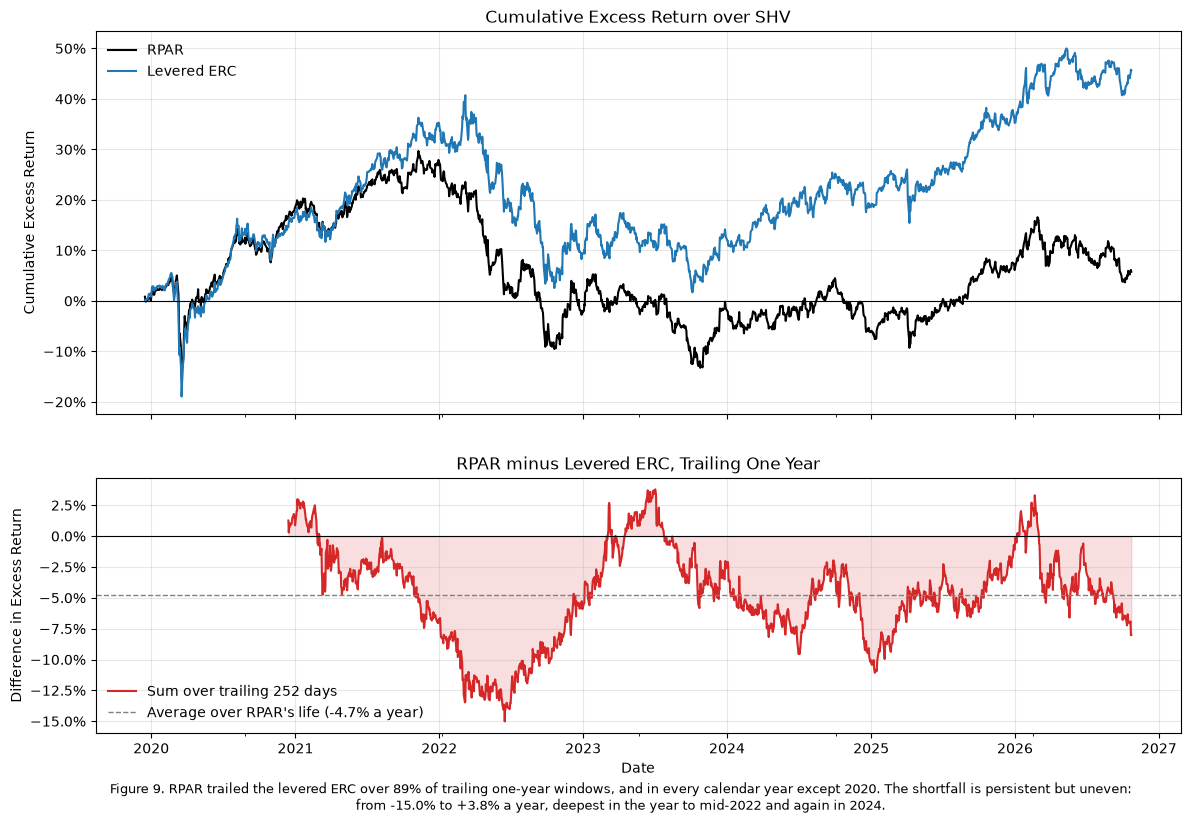

In [87]:
rpar_gap = (rpar_erc_daily["RPAR"] - rpar_erc_daily["Levered ERC"]).rename("RPAR minus Levered ERC")
trailing_gap = rpar_gap.rolling(252).sum()

#sum of daily excess-return differences by calendar year
rpar_gap_by_year = rpar_gap.groupby(rpar_gap.index.year).sum().to_frame().T
rpar_gap_by_year = rpar_gap_by_year.rename(columns = {2019: "2019 (partial)", rpar_gap.index[-1].year: f"{rpar_gap.index[-1].year} (partial)"})

display(rpar_gap_by_year.style.format("{:.2%}")
                        .set_caption("RPAR minus the levered ERC by calendar year, sum of daily excess returns"))

fig, axes = plt.subplots(2, 1, figsize = (14, 9), sharex = True, gridspec_kw = {"height_ratios": [3, 2]})

((1 + rpar_erc_daily).cumprod() - 1).plot(ax = axes[0], linewidth = 1.5, color = ["black", "tab:blue"])
axes[0].set(title = "Cumulative Excess Return over SHV", ylabel = "Cumulative Excess Return")
axes[0].legend(frameon = False)

axes[1].plot(trailing_gap.index, trailing_gap, linewidth = 1.5, color = "tab:red", label = "Sum over trailing 252 days")
axes[1].fill_between(trailing_gap.index, trailing_gap, 0, color = "tab:red", alpha = 0.15)
axes[1].axhline(rpar_gap.mean() * 252, color = "gray", linestyle = "--", linewidth = 1, label = f"Average over RPAR's life ({rpar_gap.mean() * 252:.1%} a year)")
axes[1].set(title = "RPAR minus Levered ERC, Trailing One Year", xlabel = "Date", ylabel = "Difference in Excess Return")
axes[1].legend(frameon = False, loc = "lower left")

for ax in axes:
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha = 0.3)

fig.text(0.5, 0.01, f"Figure 9. RPAR trailed the levered ERC over {(trailing_gap.dropna() < 0).mean():.0%} of trailing one-year windows, and in every calendar year except 2020. The shortfall is persistent but uneven:\n"
         f"from {trailing_gap.min():.1%} to {trailing_gap.max():+.1%} a year, deepest in the year to mid-2022 and again in 2024.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.1, hspace = 0.2)
plt.show()

> **Allocations.**
>
> * **The same core:** both put the most in `TIP` (35%–39%).
> * **The differences:** `RPAR` holds more `SPY` (20%–23% against 17%) and more `TLT` (22%–26% against 18%), and much less `DBC` (4%–7% against 15%). That fits a commodity sleeve of producer equities and gold.
> * **Scale:** its sum of betas (1.39 daily, 1.53 monthly) is close to the levered ERC's 1.55x.
>
> **Regression.**
>
> * **Daily:** slope 0.85, intercept −3.79% a year ($t$ = −1.65), $R^2$ 0.77.
> * **Monthly sums, which remove the daily attenuation:** slope 1.02, intercept −4.56% ($t$ = −2.58), $R^2$ 0.89.
> * **What it shows:** `RPAR` moves one-for-one with the rule but trails it by about 4.5% a year. It trailed in every calendar year since 2021 and in 89% of trailing years, with swings from −15.0% to +3.8% (Figure 9). Swings that large point to basis rather than costs alone; costs would produce a smaller, steadier drag.
> * **Figure 9:** the top panel shows the two paths overlapping until 2021 and then separating for good. The bottom panel plots the trailing one-year gap, which stays below zero almost throughout, deepest in mid-2022. A slope near one with a negative intercept means the same risk with less return.
>
> **Does 2008–2019 change the Section 1 conclusion?**
>
> * **For the rule: partly.**
>   * Levered to 60/40's risk, it had a Sharpe ratio of 0.61 in 2008–2019 and 0.49 over `RPAR`'s life, with a shallower 2008 drawdown (−27.4% against −30.8%).
>   * But it never beat 60/40 (0.71 and 0.57). The rule works; it does not beat a stock-bond mix at equal risk.
>   * 2022 belongs to the rule too: its drawdown was −26.9%, against `RPAR`'s −30.1%.
> * **For `RPAR` as built: no.**
>   * The backtest contains no `RPAR`.
>   * Over `RPAR`'s life, the 4.5% gap accounts for most of the distance from the rule's 0.49 to `RPAR`'s 0.13.
>   * But that gap is to a simplified benchmark built in hindsight from five ETFs. It mixes implementation, index design, holdings, leverage and rebalancing choices, financing and fees, and this file cannot separate them.
>
> **The tables.**
>
> * ***The levered ERC rule and `RPAR`, each at its own volatility:*** compares Sharpe ratios and drawdowns over `RPAR`'s life and over 2008–2019. It is the basis for the "does 2008–2019 change the conclusion" answer.
> * ***`RPAR` minus the levered ERC by calendar year:*** shows whether the shortfall is steady or comes from a few bad years. It is steady, but uneven in size.

***


# 5. What Broke

| Episode | Window |
|---|---|
| 2020 | 2020-02-19 to 2020-03-23 |
| 2022 | 2022-01-03 to 2022-10-24 |
| Calm | 2023-01-03 to 2024-12-31 |

For the VaR backtests, extend the 2020 window to April 30 and the 2022 window to December 30. A breach is a day whose return falls below the forecast. With the 252-day burn-in, `RPAR` and `DBMF` have no historical-simulation forecast inside the 2020 window; their 2020 rows carry EWMA only. Attribution in 5.3 uses the shorter windows tabled above.


## 5.1

For `RPAR`, the levered ERC portfolio from 4.3, 60/40, `NTSX` and `DBMF`, forecast the one-day 5% VaR for every day by rolling historical simulation (the trailing 252 returns) and Normal EWMA with $\lambda = 0.97$. Report

* the breach rate over each series' full forecast sample and within each episode in which it has forecasts
* a blank where a method has no forecast, and say so


In [88]:
VAR_LEVEL = 0.05
EWMA_LAMBDA = 0.97
VAR_SERIES = ["RPAR", "Levered ERC", "60/40", "NTSX", "DBMF"]

#the episodes extended for the VaR backtests; Calm is unchanged
VAR_WINDOWS = {"2020": ("2020-02-19", "2020-04-30"),
               "2022": ("2022-01-03", "2022-12-30"),
               "Calm": ("2023-01-03", "2024-12-31")}

var_returns = pd.concat([returns[["RPAR", "60/40", "NTSX", "DBMF"]], levered_erc_returns.rename("Levered ERC")], axis = 1)[VAR_SERIES]

#forecasts for day t use returns through t - 1, each series from its own first return
var_forecasts, ewma_vols = {}, {}
for series in VAR_SERIES:
    series_returns = var_returns[series].dropna()
    ewma_vols[series] = project_utils.ewma_volatility(series_returns, lam = EWMA_LAMBDA)
    var_forecasts[(series, "Historical")] = project_utils.historical_var(series_returns, level = VAR_LEVEL)
    var_forecasts[(series, "EWMA")], _ = project_utils.normal_var_cvar(ewma_vols[series], level = VAR_LEVEL)

var_forecasts = pd.DataFrame(var_forecasts)
ewma_vols = pd.DataFrame(ewma_vols)

forecast_starts = pd.DataFrame({"First Return": var_returns.apply(pd.Series.first_valid_index),
                                "First Historical Forecast": var_forecasts.xs("Historical", axis = 1, level = 1).apply(pd.Series.first_valid_index),
                                "First EWMA Forecast": var_forecasts.xs("EWMA", axis = 1, level = 1).apply(pd.Series.first_valid_index)})

display(forecast_starts.style.format(format_date)
                       .set_caption("First forecast of each method: historical simulation after 252 returns, EWMA from the 22nd day"))

,First Return,First Historical Forecast,First EWMA Forecast
RPAR,2019-12-16,2020-12-15,2020-01-16
Levered ERC,2008-02-01,2009-02-02,2008-03-04
60/40,2002-07-29,2003-07-29,2002-08-27
NTSX,2018-08-03,2019-08-26,2018-09-04
DBMF,2019-05-09,2020-05-08,2019-06-10


In [89]:
var_periods = ["Full sample"] + list(VAR_WINDOWS)

breaches = pd.concat({(series, method): project_utils.breach_stats(var_returns[series], var_forecasts[(series, method)], VAR_WINDOWS)
                      for series, method in var_forecasts.columns}, names = ["Series", "Method", "Period"])

#rows by series and method, columns by period; a period with no forecasts is left blank
breach_table = breaches.unstack("Period").swaplevel(axis = 1)
breach_table = breach_table.reindex(columns = pd.MultiIndex.from_product([var_periods, ["Breach Rate", "Breaches", "Forecast Days"]]))
breach_table = breach_table.reindex(var_forecasts.columns)

#a window with no forecasts is left blank, including its day count
for period in var_periods:
    breach_table.loc[breach_table[(period, "Forecast Days")] == 0, period] = np.nan

display(breach_table.style.format("{:.0f}", na_rep = "—")
                    .format("{:.1%}", na_rep = "—", subset = pd.IndexSlice[:, pd.IndexSlice[:, "Breach Rate"]])
                    .set_caption("One-day 5% VaR breaches (expected rate 5%). Episodes extended to 2020-04-30 and 2022-12-30. "
                                 "— : no forecast in that window (historical simulation needs 252 prior returns)"))

#the breach rate measures coverage only; the lecture notes also ask whether breaches cluster. Compare the chance of a breach
#on any forecast day with the chance on the day after a breach (independent breaches would make the two equal)
breach_clustering = {}
for series, method in var_forecasts.columns:
    forecast = var_forecasts[(series, method)]
    breached = (var_returns[series] < forecast)[forecast.notna() & var_returns[series].notna()]
    after_breach = breached[breached.shift(1, fill_value = False)]
    breach_clustering[(series, method)] = {"Breach Rate": breached.mean(),
                                           "Breach Rate the Day after a Breach": after_breach.mean(),
                                           "Days after a Breach": len(after_breach)}

breach_clustering = pd.DataFrame(breach_clustering).T
display(breach_clustering.style.format({"Breach Rate": "{:.1%}", "Breach Rate the Day after a Breach": "{:.1%}", "Days after a Breach": "{:.0f}"})
                         .set_caption("Breach clustering over each full forecast sample"))

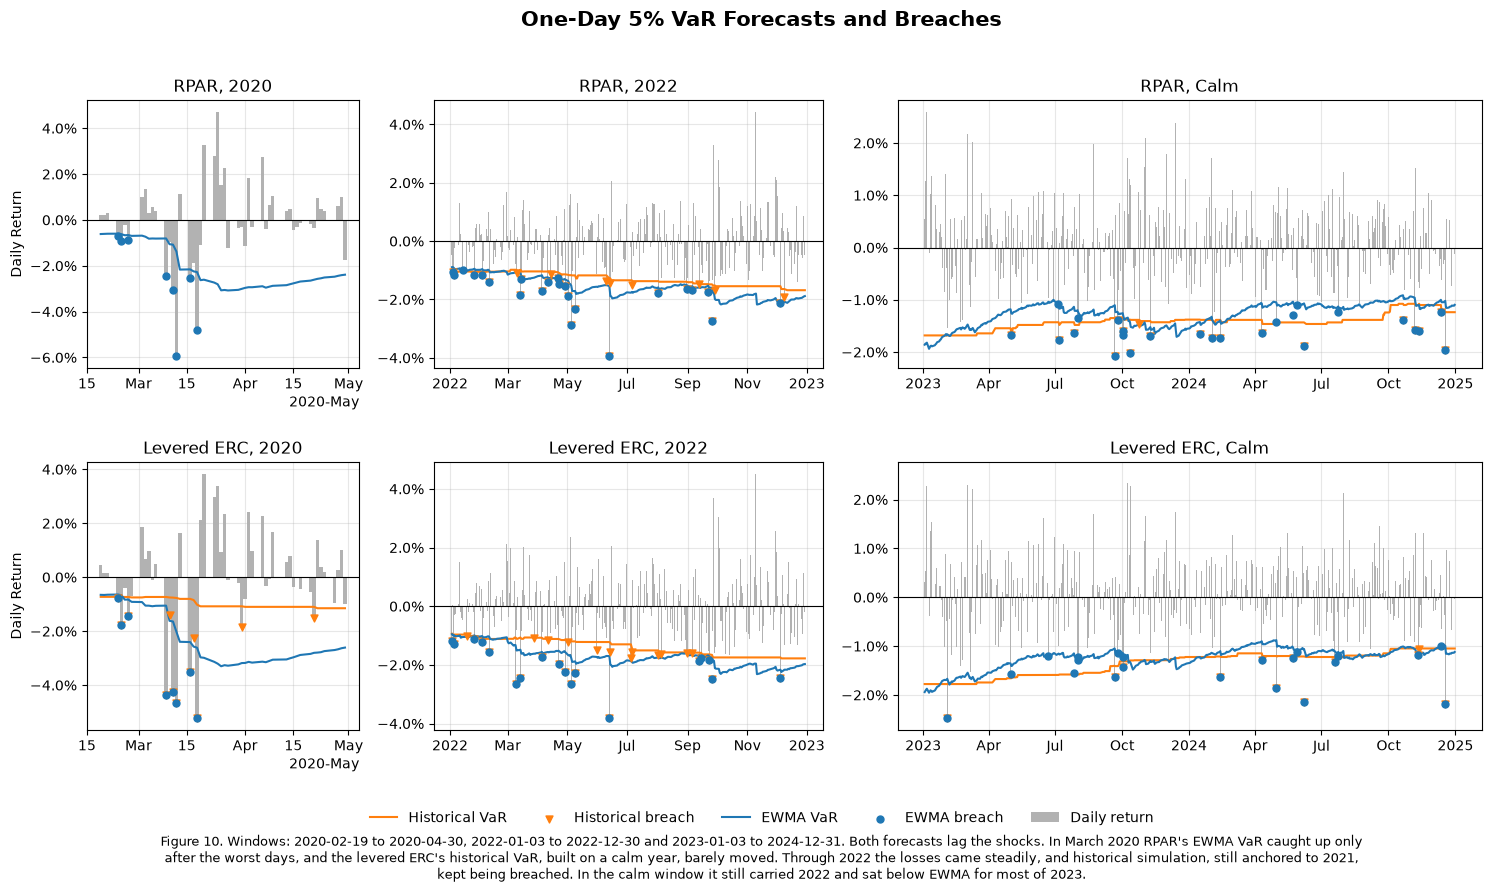

In [90]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 3, figsize = (18, 9), gridspec_kw = {"width_ratios": [1.4, 2, 3]})

method_colors = {"Historical": "tab:orange", "EWMA": "tab:blue"}

for row, series in zip(axes, ["RPAR", "Levered ERC"]):
    for ax, (label, (start, end)) in zip(row, VAR_WINDOWS.items()):
        window_returns = var_returns.loc[start:end, series]
        ax.bar(window_returns.index, window_returns, color = "gray", width = 1.0, alpha = 0.6, label = "Daily return")

        for method, color in method_colors.items():
            forecast = var_forecasts.loc[start:end, (series, method)]
            if forecast.notna().any():
                ax.plot(forecast.index, forecast, color = color, linewidth = 1.5, label = f"{method} VaR")
                breach_days = window_returns[window_returns < forecast]
                ax.scatter(breach_days.index, breach_days, color = color, s = 25, zorder = 3, marker = "v" if method == "Historical" else "o",
                           label = f"{method} breach")

        ax.set(title = f"{series}, {label}", ylabel = "Daily Return" if ax is row[0] else "")
        ax.axhline(0, color = "black", linewidth = 0.8)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
        ax.grid(alpha = 0.3)

handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.06), frameon = False)

fig.suptitle("One-Day 5% VaR Forecasts and Breaches", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 10. Windows: 2020-02-19 to 2020-04-30, 2022-01-03 to 2022-12-30 and 2023-01-03 to 2024-12-31. Both forecasts lag the shocks. In March 2020 RPAR's EWMA VaR caught up only\n"
         "after the worst days, and the levered ERC's historical VaR, built on a calm year, barely moved. Through 2022 the losses came steadily, and historical simulation, still anchored to 2021,\n"
         "kept being breached. In the calm window it still carried 2022 and sat below EWMA for most of 2023.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.18, hspace = 0.35, wspace = 0.18)
plt.show()

> **Method.**
>
> * **Inputs:** total returns, with the forecast for day $t$ using returns through $t-1$.
> * **Historical simulation:** the lower empirical 5% quantile (the lecture convention) of the trailing 252 returns, which is the 13th-lowest.
> * **Normal EWMA:** zero mean, $\lambda = 0.97$, seeded with the variance of the first 21 returns, and VaR $= -1.645\,\sigma_t$. A weight that decays by 3% a day gives a half-life of about 23 trading days, so EWMA reacts within weeks. Historical simulation weights all 252 days equally, so one bad week barely moves its 5th percentile.
> * **Expected breaches:** 2.6 in 2020, 12.6 in 2022 and 25 in the calm window.
> * **Blanks:** `RPAR` and `DBMF` have no historical forecast until after the 2020 window, because they had fewer than 252 prior returns.
>
> **Results.**
>
> * **Full sample:** 4.6%–5.8% for every series and method, so the forecasts are calibrated on average.
> * **2020: every forecast failed.**
>   * Historical simulation breached on 23.5%–29.4% of days; it was built on a calm year.
>   * EWMA breached on 11.8%–17.6%. All eight of `RPAR`'s breaches came before its variance caught up on March 18.
> * **2022:**
>   * Historical simulation breached on 11.2%–12.0% of days, except `DBMF` (5.6%).
>   * EWMA came closer (6.8%–8.0%), except `RPAR` at 9.2% (23 breaches).
> * **Calm window:** every rate is at or below 5.4%. Historical simulation breached less than EWMA for every series, because its window still held 2022.
> * **Clustering, the lecture's second test:**
>   * The day after a breach, the breach rate is 6.5%–13.3%, against 4.6%–5.8% overall.
>   * In 2020, `RPAR` and the levered ERC breached on the same eight days.
>   * So rates near 5% overstate calibration.
>
> **Figure 10** shows the timing behind these rates for `RPAR` and the levered ERC in each window. Gray bars are daily returns, lines are each day's forecast, and markers are breaches.
>
> * **March 2020:** the blue EWMA line steps down only after the first large losses, while the orange historical line barely moves.
> * **2022:** breaches are spread across the year, a grind rather than a single shock.
>
> **Overall.**
>
> * EWMA adapts faster, so it breached less in the episodes and more in the calm window.
> * Neither method kept up with a jump like March 2020.
> * In 2022's year-long grind, even EWMA underestimated `RPAR`.
>
> **The tables.**
>
> * ***First forecast of each method:*** documents why some cells are blank. Historical simulation needs 252 prior returns, so `RPAR` and `DBMF` have no forecast in the 2020 window.
> * ***Breach clustering:*** the lecture's second test. It compares the breach rate on any day with the rate on the day after a breach; independent breaches would make the two equal.

## 5.2

On the breach days of the Normal EWMA ($\lambda = 0.97$) forecast within the extended 2020 and 2022 windows, report for each series

* the number of breaches
* the mean realized loss beside the mean CVaR forecast on those days
* the worst day's return as a multiple of the VaR forecast made for that day


In [91]:
#Normal EWMA VaR and CVaR forecasts for every day, from the volatility forecasts in 5.1
ewma_var, ewma_cvar = project_utils.normal_var_cvar(ewma_vols, level = VAR_LEVEL)

breach_days = {}
for series in VAR_SERIES:
    for label in ["2020", "2022"]:
        start, end = VAR_WINDOWS[label]
        window = pd.DataFrame({"Return": var_returns.loc[start:end, series],
                               "VaR": ewma_var.loc[start:end, series],
                               "CVaR": ewma_cvar.loc[start:end, series]}).dropna()
        window = window[window["Return"] < window["VaR"]]
        worst = window["Return"].idxmin()

        breach_days[(series, label)] = {"Breaches": len(window),
                                        "Mean Return on Breach Days": window["Return"].mean(),
                                        "Mean CVaR Forecast": window["CVaR"].mean(),
                                        "Realized / CVaR": window["Return"].mean() / window["CVaR"].mean(),
                                        "Worst Day": worst,
                                        "Worst Return": window.loc[worst, "Return"],
                                        "VaR Forecast that Day": window.loc[worst, "VaR"],
                                        "Worst Return / VaR": window.loc[worst, "Return"] / window.loc[worst, "VaR"]}

breach_days = pd.DataFrame(breach_days).T.rename_axis(["Series", "Episode"])
breach_days = breach_days.swaplevel().sort_index(level = "Episode", sort_remaining = False).reindex(VAR_SERIES, level = "Series")

display(breach_days.style.format({"Breaches": "{:.0f}",
                                  "Mean Return on Breach Days": "{:.2%}",
                                  "Mean CVaR Forecast": "{:.2%}",
                                  "Realized / CVaR": "{:.2f}x",
                                  "Worst Day": format_date,
                                  "Worst Return": "{:.2%}",
                                  "VaR Forecast that Day": "{:.2%}",
                                  "Worst Return / VaR": "{:.2f}x"})
                     .set_caption("Normal EWMA (λ = 0.97) breach days, 2020-02-19 to 2020-04-30 and 2022-01-03 to 2022-12-30; expected breaches 2.6 and 12.6"))

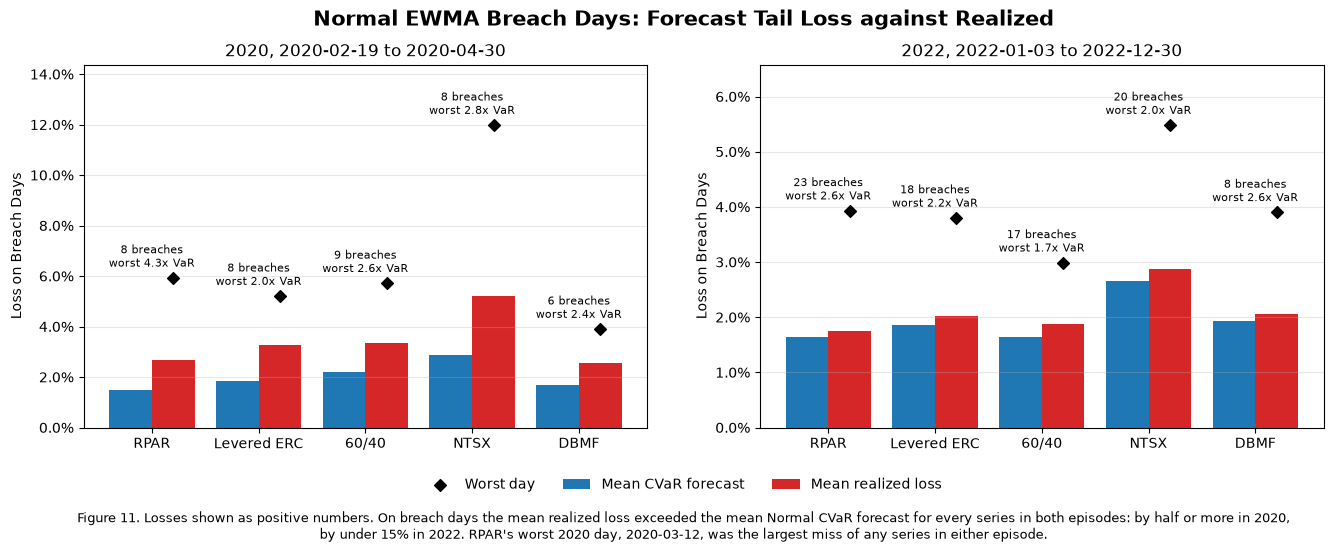

In [92]:
fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))

for ax, label in zip(axes, ["2020", "2022"]):
    episode = breach_days.loc[label]
    x = np.arange(len(episode))

    ax.bar(x - 0.2, -episode["Mean CVaR Forecast"].astype(float), width = 0.4, color = "tab:blue", label = "Mean CVaR forecast")
    ax.bar(x + 0.2, -episode["Mean Return on Breach Days"].astype(float), width = 0.4, color = "tab:red", label = "Mean realized loss")
    ax.scatter(x + 0.2, -episode["Worst Return"].astype(float), marker = "D", color = "black", zorder = 3, label = "Worst day")

    for xi, (series, row) in zip(x, episode.iterrows()):
        ax.annotate(f"{row['Breaches']:.0f} breaches\nworst {row['Worst Return / VaR']:.1f}x VaR", (xi, -row["Worst Return"]), xytext = (0, 8),
                    textcoords = "offset points", ha = "center", fontsize = 8)

    ax.set(title = f"{label}, {VAR_WINDOWS[label][0]} to {VAR_WINDOWS[label][1]}", ylabel = "Loss on Breach Days")
    ax.set_xticks(x, episode.index)
    ax.set_ylim(0, -episode["Worst Return"].astype(float).min() * 1.2)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.08), frameon = False)

fig.suptitle("Normal EWMA Breach Days: Forecast Tail Loss against Realized", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 11. Losses shown as positive numbers. On breach days the mean realized loss exceeded the mean Normal CVaR forecast for every series in both episodes: by half or more in 2020,\n"
         "by under 15% in 2022. RPAR's worst 2020 day, 2020-03-12, was the largest miss of any series in either episode.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.22, wspace = 0.2)
plt.show()

> **Method.** The zero-mean Normal EWMA from 5.1: VaR $= -1.645\,\sigma_t$, CVaR $= -\sigma_t\,\phi(1.645)/0.05 = -2.063\,\sigma_t$. CVaR is the model's expected loss given a breach, so it is the forecast to compare against on breach days.
>
> | | 2020 (2.6 expected) | 2022 (12.6 expected) |
> |---|---|---|
> | Breaches | 6–9 | 8 (`DBMF`) to 23 (`RPAR`) |
> | Mean loss ÷ mean CVaR | 1.51x–1.82x | 1.06x–1.14x |
> | Worst day ÷ VaR | 1.99x–4.31x | 1.72x–2.60x |
>
> * **2020, a jump: too many breaches, each too large.**
>   * `RPAR`'s −5.93% on 2020-03-12 was 4.31 times a stale VaR of −1.38%, a 7σ day under the model.
>   * 60/40's similar −5.72% was only 2.59 times its −2.21% VaR.
> * **2022, a grind: each breach about the predicted size, but too many.**
>   * For `RPAR`, −1.75% against a CVaR forecast of −1.65%.
>   * Four series had their worst day on 2022-06-13, after the May CPI report.
>
> **Figure 11** shows the comparison on breach days only. The blue bar is the loss the model expected given a breach, the red bar is the loss that happened, and the diamond is the worst day. In 2020 red towers over blue for every series; in 2022 the bars nearly match, but the breach counts in the labels are too high.
>
> **What the lecture models would change.**
>
> * **Student's t:** it raises the CVaR-to-VaR multiple above the Normal's 1.25, which addresses 2020's size problem. It does not fix the breach frequency, which comes from a lagging volatility forecast.
> * **Filtered historical simulation:** this targets that lag.
> * **Either way, CVaR is the measure that matters here,** and the Normal CVaR was too small exactly when it mattered.

## 5.3

Attribute each live fund's 2020 and 2022 episode to its factors day by day: each factor's excess return times the fund's full-sample daily beta from 2.2, summed over the episode by factor, beside the sum of the fund's daily excess returns. Do the same for the levered ERC portfolio with its actual daily weights and leverage.

* Report the attribution for each series and episode.
* Compute the static approximation, each beta times the factor's compounded total return over the window (episode-start weights for the ERC), and say what the gap between the two attributions contains.


In [93]:
ATTRIBUTION_WINDOWS = {"2020": ("2020-02-19", "2020-03-23"),
                       "2022": ("2022-01-03", "2022-10-24")}

daily_betas = factor_regressions.loc["Daily", FACTORS].astype(float)

#exposures held on each day of the window: constant full-sample betas for the funds, actual positions for the levered ERC
episode_exposures, episode_notes = {}, {}
for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    for fund in LIVE:
        days = excess_returns.loc[start:end, fund].dropna().index
        if days.empty:
            episode_notes[(label, fund)] = "no returns in the window"
            continue
        if days[0] > pd.Timestamp(start):
            episode_notes[(label, fund)] = f"from its first return, {days[0].date()}"
        episode_exposures[(label, fund)] = pd.DataFrame([daily_betas.loc[fund]] * len(days), index = days)

    episode_exposures[(label, "Levered ERC")] = levered_erc_positions.loc[start:end, FACTORS]

dynamic_attribution, static_attribution, attribution_gap = {}, {}, {}
for (label, series), exposure in episode_exposures.items():
    days = exposure.index
    factor_excess = excess_returns.loc[days, FACTORS]
    series_excess = levered_erc_excess.loc[days] if series == "Levered ERC" else excess_returns.loc[days, series]
    series_total = levered_erc_returns.loc[days] if series == "Levered ERC" else returns.loc[days, series]

    #day by day: exposure held that day times the factor's excess return, summed over the window
    dynamic = (exposure * factor_excess).sum()
    dynamic["Sum of Factors"] = dynamic[FACTORS].sum()
    dynamic["Excess Return (sum of daily)"] = series_excess.sum()
    dynamic["Residual"] = dynamic["Excess Return (sum of daily)"] - dynamic["Sum of Factors"]

    #the fund's residual split into its 2.2 intercept over the window's days and the rest
    intercept = 0.0 if series == "Levered ERC" else factor_regressions.loc[("Daily", series), "Annualized Intercept"] / 252 * len(days)
    dynamic["Intercept x Days"] = intercept
    dynamic["Unexplained"] = dynamic["Residual"] - intercept
    dynamic_attribution[(label, series)] = dynamic

    #static: the window's first exposure times the factor's compounded total return
    start_exposure = exposure.iloc[0]
    factor_compound = (1 + returns.loc[days, FACTORS]).prod() - 1
    static = start_exposure * factor_compound
    static["Sum of Factors"] = static[FACTORS].sum()
    static["Total Return (compounded)"] = (1 + series_total).prod() - 1
    static_attribution[(label, series)] = static

    #static minus dynamic, summed over factors, split exactly into three pieces
    attribution_gap[(label, series)] = {"Gap (static minus dynamic)": static["Sum of Factors"] - dynamic["Sum of Factors"],
                                        "Compounding": (start_exposure * (factor_compound - returns.loc[days, FACTORS].sum())).sum(),
                                        "Cash (exposure x SHV)": (start_exposure * returns.loc[days, "SHV"].sum()).sum(),
                                        "Weight Drift and Rebalancing": (start_exposure * factor_excess.sum() - (exposure * factor_excess).sum()).sum()}

attribution_names = ["Episode", "Series"]
dynamic_attribution = pd.DataFrame(dynamic_attribution).T.rename_axis(attribution_names)
static_attribution = pd.DataFrame(static_attribution).T.rename_axis(attribution_names)
attribution_gap = pd.DataFrame(attribution_gap).T.rename_axis(attribution_names)

for series_label, note in episode_notes.items():
    print(f"{series_label[0]}, {series_label[1]}: {note}")

display(dynamic_attribution.style.format("{:.2%}")
                           .set_caption("Day-by-day attribution: each factor's daily excess return times the full-sample daily beta (actual positions for the levered ERC), summed over the episode"))

display(static_attribution.style.format("{:.2%}")
                          .set_caption("Static approximation: each beta (episode-start position for the levered ERC) times the factor's compounded total return over the episode"))

display(attribution_gap.style.format("{:.2%}")
                       .set_caption("Static minus day-by-day attribution, summed over factors: compounding + cash + weight drift and rebalancing"))

2020, UPAR: no returns in the window
2020, ALLW: no returns in the window
2022, UPAR: from its first return, 2022-01-05
2022, ALLW: no returns in the window


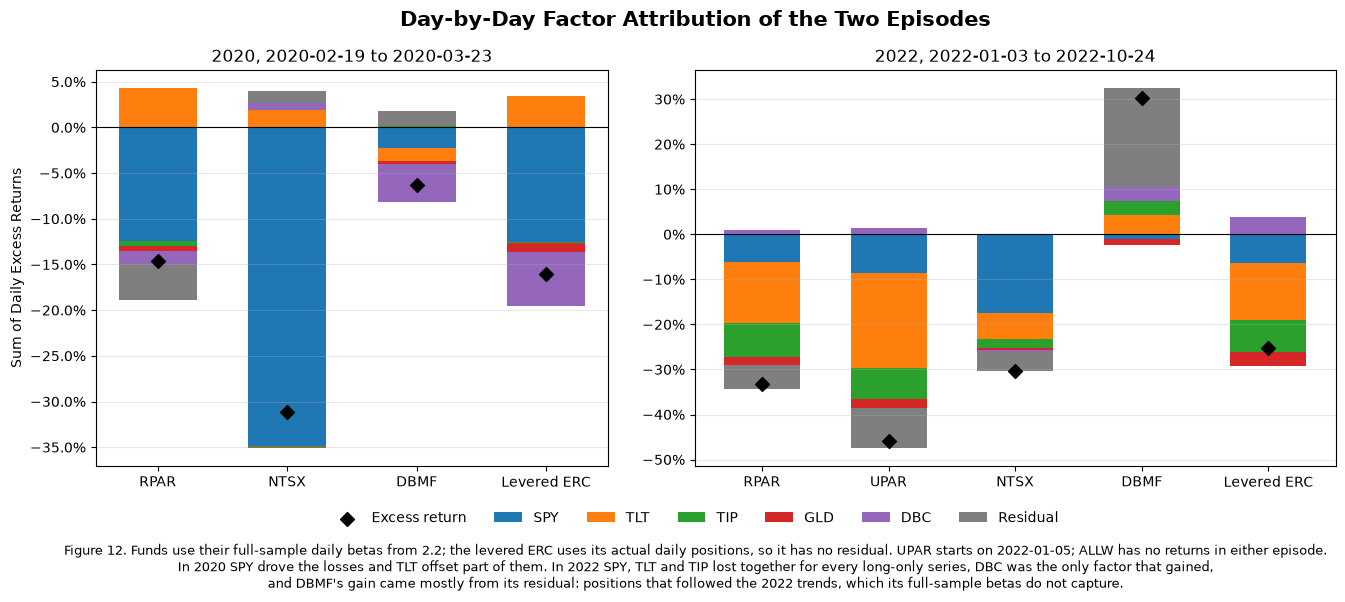

In [94]:
fig, axes = plt.subplots(1, 2, figsize = (16, 6), gridspec_kw = {"width_ratios": [4, 5]})

attribution_cols = FACTORS + ["Residual"]
attribution_colors = dict(zip(attribution_cols, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:gray"]))

for ax, label in zip(axes, ATTRIBUTION_WINDOWS):
    episode = dynamic_attribution.loc[label]

    #stack gains upward and losses downward from zero
    positive = np.zeros(len(episode))
    negative = np.zeros(len(episode))
    for col in attribution_cols:
        values = episode[col].to_numpy()
        ax.bar(episode.index, values, bottom = np.where(values >= 0, positive, negative), width = 0.6, color = attribution_colors[col], label = col)
        positive += np.clip(values, 0, None)
        negative += np.clip(values, None, 0)

    ax.scatter(episode.index, episode["Excess Return (sum of daily)"], marker = "D", s = 50, color = "black", zorder = 3, label = "Excess return")

    start, end = ATTRIBUTION_WINDOWS[label]
    ax.set(title = f"{label}, {start} to {end}", ylabel = "Sum of Daily Excess Returns" if ax is axes[0] else "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis = "y", alpha = 0.3)

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc = "lower center", ncol = len(labels), bbox_to_anchor = (0.5, 0.1), frameon = False)

fig.suptitle("Day-by-Day Factor Attribution of the Two Episodes", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 12. Funds use their full-sample daily betas from 2.2; the levered ERC uses its actual daily positions, so it has no residual. UPAR starts on 2022-01-05; ALLW has no returns in either episode.\n"
         "In 2020 SPY drove the losses and TLT offset part of them. In 2022 SPY, TLT and TIP lost together for every long-only series, DBC was the only factor that gained,\n"
         "and DBMF's gain came mostly from its residual: positions that followed the 2022 trends, which its full-sample betas do not capture.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.22, wspace = 0.15)
plt.show()

> **Method.**
>
> * **Funds:** factor $k$ contributes $\beta_k \sum_t (r_{k,t}-r^f_t)$, using the 2.2 daily betas. The residual splits into the intercept times the number of days and an unexplained part.
> * **Levered ERC:** actual daily positions, so its attribution is exact.
> * **Windows:** 2020-02-19 to 2020-03-23 and 2022-01-03 to 2022-10-24.
>
> **2020: an equity shock.**
>
> * **`RPAR`:** −14.6% (`SPY` −12.4%, `TLT` +4.3%).
>   * The factors explain −10.6%, leaving −4.0% unexplained; the intercept accounts for only −0.3%.
>   * That fits understated daily betas and producer equities falling with stocks.
> * **Levered ERC:** −16.1%, hurt more by `DBC` (−6.0% against −1.4%).
> * **`NTSX`:** −31.1%, almost all from `SPY`.
>
> **2022: a bond and inflation shock.**
>
> * **`RPAR`:** −33.2% (`TLT` −13.4%, `TIP` −7.7%, `SPY` −6.3%), with only `DBC` (+1.1%) offsetting.
>   * The residual is −5.2%, of which −2.9% is the intercept.
> * **Levered ERC:** lost less (−25.3%) on similar bond losses, thanks to `DBC` (+4.0%) and having no residual.
> * **`DBMF`:** gained 30.2%, but its betas explain only 8.3%. The rest is trend positioning that a fixed beta cannot capture.
>
> **Figure 12** stacks each series' episode return by factor, with the residual in gray and the actual return as a diamond.
>
> * **2020:** dominated by `SPY`, with `TLT` pushing back above zero for `RPAR` and the levered ERC.
> * **2022:** `TLT` and `TIP` lose together.
> * **`DBMF` in 2022:** its bar is mostly gray, which is what "a fixed beta cannot capture" looks like.
>
> **Static minus day by day.** A constant daily beta is a portfolio rebalanced every day, while the static version holds its starting exposure through the whole window. The difference splits exactly into three pieces:
>
> 1. **Compounding:** beta times the compounded factor return minus the summed one. This is the largest piece. In 2022 `TLT` summed −44.0% but compounded to −36.6%. It contributes +1.1% (2020) and +2.4% (2022) for `RPAR` and +3.7% for `NTSX` in 2020. It is negative only for `DBMF` in 2022, because its bond betas are short.
> 2. **Cash:** beta times the summed `SHV` return. Small.
> 3. **Weight drift, for the ERC only:** −1.4% in 2020, as falling assets shrank, and +1.0% in 2022, as resets bought falling bonds back.
>
> **What the gap leaves out.** It contains none of the residual. The static version also understates the factors' share every time: for `RPAR` in 2020, −8.7% against −10.6%.

## 5.4

Compare `RPAR` in 2020 and 2022 using the factor paths, the attribution in 5.3, the breach rates in 5.1 and 5.2, and the rolling sums of betas from 2.3. Explain the similarities and differences in at most half a page.


In [95]:
rpar_rolling = rolling_betas["RPAR"]

rpar_episodes = {}
for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    days = excess_returns.loc[start:end, "RPAR"].dropna().index
    factor_compound = (1 + returns.loc[days, FACTORS]).prod() - 1

    #trailing 252-day windows ending before the episode, inside it, and the first one ending after it
    before = rpar_rolling.loc[:pd.Timestamp(start) - pd.Timedelta(days = 1), "Sum of Betas"]
    during = rpar_rolling.loc[start:end, "Sum of Betas"]
    after = rpar_rolling.loc[pd.Timestamp(end) + pd.Timedelta(days = 1):, "Sum of Betas"]

    rpar_episodes[label] = {"Trading Days": len(days),
                            "RPAR Total Return": (1 + returns.loc[days, "RPAR"]).prod() - 1,
                            **{f"{factor} Total Return": factor_compound[factor] for factor in FACTORS},
                            "SPY-TLT Correlation": returns.loc[days, "SPY"].corr(returns.loc[days, "TLT"]),
                            "Sum of Factors (5.3)": dynamic_attribution.loc[(label, "RPAR"), "Sum of Factors"],
                            "Residual (5.3)": dynamic_attribution.loc[(label, "RPAR"), "Residual"],
                            "Historical Breach Rate (5.1)": breach_table.loc[("RPAR", "Historical"), (label, "Breach Rate")],
                            "EWMA Breach Rate (5.1)": breach_table.loc[("RPAR", "EWMA"), (label, "Breach Rate")],
                            "EWMA Realized / CVaR (5.2)": breach_days.loc[(label, "RPAR"), "Realized / CVaR"],
                            "EWMA Worst Return / VaR (5.2)": breach_days.loc[(label, "RPAR"), "Worst Return / VaR"],
                            "Sum of Betas, Last Window Before": before.iloc[-1] if len(before) else np.nan,
                            "Sum of Betas, Windows Ending Inside": f"{during.min():.2f} to {during.max():.2f}" if len(during) else "—",
                            "Sum of Betas, First Window After": after.iloc[0] if len(after) else np.nan}

rpar_episodes = pd.DataFrame(rpar_episodes)

pct_rows = ["RPAR Total Return"] + [f"{factor} Total Return" for factor in FACTORS] + ["Sum of Factors (5.3)", "Residual (5.3)", "Historical Breach Rate (5.1)", "EWMA Breach Rate (5.1)"]
ratio_rows = ["SPY-TLT Correlation", "EWMA Realized / CVaR (5.2)", "EWMA Worst Return / VaR (5.2)", "Sum of Betas, Last Window Before", "Sum of Betas, First Window After"]

display(rpar_episodes.style.format(lambda x: x if isinstance(x, str) else ("—" if pd.isna(x) else f"{x:.0f}"))
                     .format(lambda x: "—" if pd.isna(x) else f"{x:.1%}", subset = (pct_rows, slice(None)))
                     .format(lambda x: "—" if pd.isna(x) else f"{x:.2f}", subset = (ratio_rows, slice(None)))
                     .set_caption("RPAR in the two episodes. Factor paths and attribution over the short windows; breach statistics over the extended windows (to 2020-04-30 and 2022-12-30)"))

print(f"First trailing 252-day RPAR regression ends {rpar_rolling.index[0].date()}; no window ends before the 2020 episode")

,2020,2022
Trading Days,24,204
RPAR Total Return,-13.6%,-28.8%
SPY Total Return,-33.4%,-19.3%
TLT Total Return,14.2%,-36.6%
TIP Total Return,-0.6%,-13.3%
GLD Total Return,-3.1%,-10.1%
DBC Total Return,-25.0%,20.1%
SPY-TLT Correlation,-0.50,0.02
Sum of Factors (5.3),-10.6%,-28.0%
Residual (5.3),-4.0%,-5.2%


First trailing 252-day RPAR regression ends 2020-12-14; no window ends before the 2020 episode


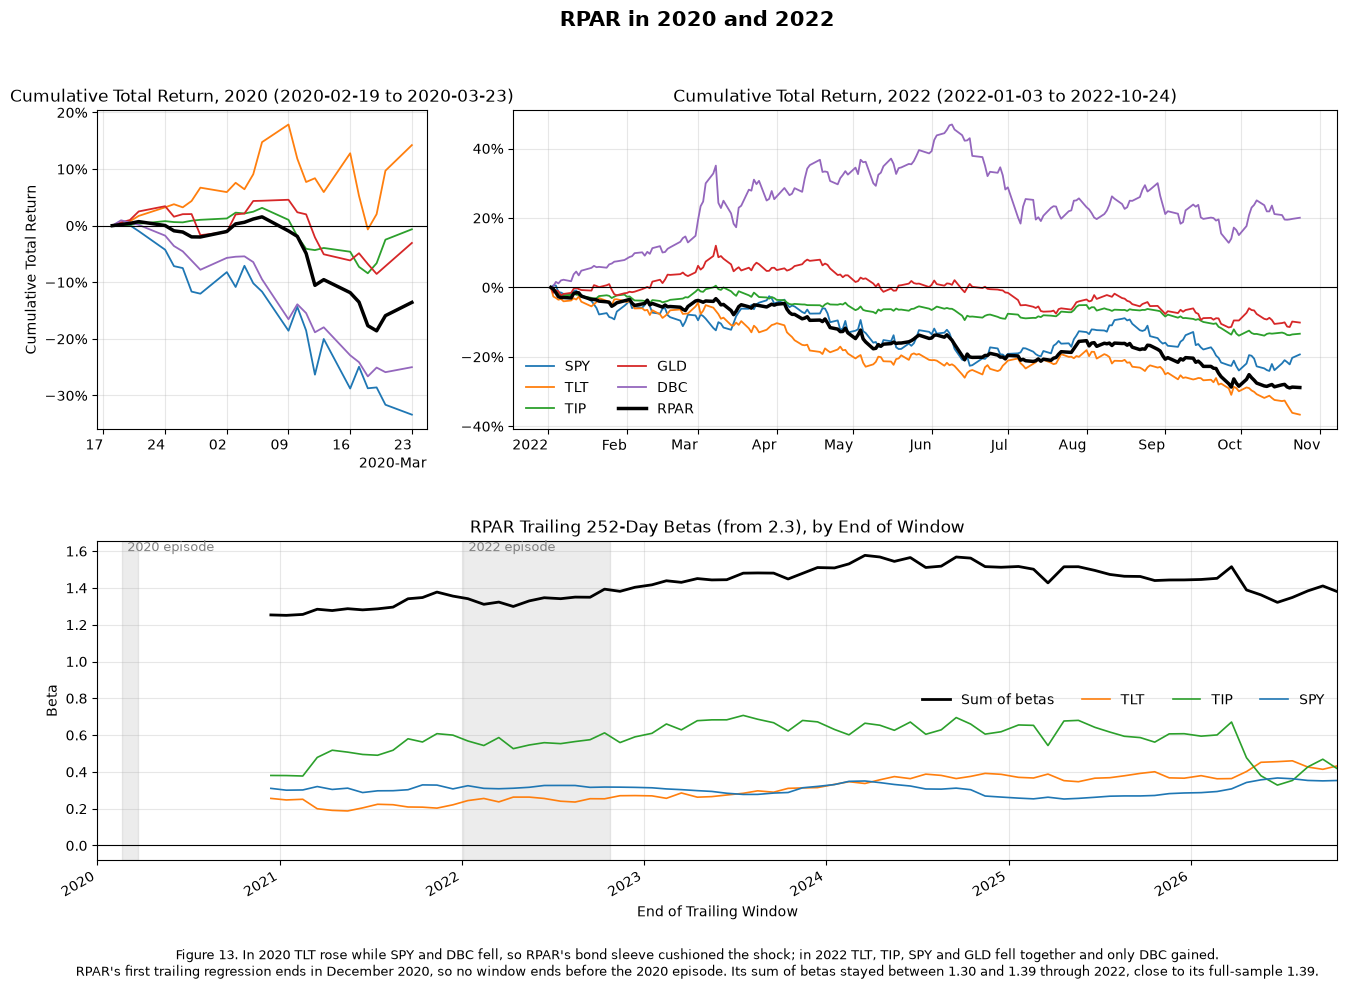

In [96]:
fig, axes = plt.subplot_mosaic([["2020", "2022"], ["betas", "betas"]], figsize = (16, 10), gridspec_kw = {"width_ratios": [1, 2.5]})

for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    ax = axes[label]
    days = returns.loc[start:end].index

    #growth of $1 from the close before the window, so every path starts at zero
    paths = (1 + returns.loc[days, FACTORS + ["RPAR"]]).cumprod() - 1
    paths = pd.concat([pd.DataFrame(0.0, index = [days[0] - pd.Timedelta(days = 1)], columns = paths.columns), paths])

    paths[FACTORS].plot(ax = ax, linewidth = 1.3, legend = False, x_compat = True)
    paths["RPAR"].plot(ax = ax, linewidth = 2.5, color = "black", legend = False, x_compat = True)

    ax.set(title = f"Cumulative Total Return, {label} ({start} to {end})", xlabel = "", ylabel = "Cumulative Total Return" if label == "2020" else "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    if label == "2020":
        ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday = mdates.MO))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.tick_params(axis = "x", labelrotation = 0)
    ax.grid(alpha = 0.3)

handles, labels = axes["2022"].get_legend_handles_labels()
axes["2022"].legend(handles, labels, frameon = False, loc = "lower left", ncol = 2)

ax = axes["betas"]
rpar_rolling["Sum of Betas"].plot(ax = ax, linewidth = 2, color = "black", label = "Sum of betas")
rpar_rolling[["TLT", "TIP", "SPY"]].plot(ax = ax, linewidth = 1.2, color = ["tab:orange", "tab:green", "tab:blue"])
for label, (start, end) in ATTRIBUTION_WINDOWS.items():
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color = "gray", alpha = 0.15)
    ax.annotate(f"{label} episode", (pd.Timestamp(start), 1.6), xytext = (4, 0), textcoords = "offset points", fontsize = 9, color = "gray")
ax.set(title = "RPAR Trailing 252-Day Betas (from 2.3), by End of Window", xlabel = "End of Trailing Window", ylabel = "Beta",
       xlim = (pd.Timestamp("2020-01-01"), rpar_rolling.index[-1]))
ax.axhline(0, color = "black", linewidth = 0.8)
ax.legend(frameon = False, ncol = 4, loc = "center right")
ax.grid(alpha = 0.3)

fig.suptitle("RPAR in 2020 and 2022", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 13. In 2020 TLT rose while SPY and DBC fell, so RPAR's bond sleeve cushioned the shock; in 2022 TLT, TIP, SPY and GLD fell together and only DBC gained.\n"
         "RPAR's first trailing regression ends in December 2020, so no window ends before the 2020 episode. Its sum of betas stayed between 1.30 and 1.39 through 2022, close to its full-sample 1.39.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.13, hspace = 0.35, wspace = 0.15)
plt.show()

> **Similarities.** Both episodes were large losses for `RPAR`: −13.6% in 24 days in 2020 and −28.8% in 204 days in 2022. In both, its factor exposures explain most of the loss (−10.6% and −28.0% of summed excess return), with a negative residual on top (−4.0% and −5.2%). Both broke the VaR forecasts. EWMA breached on 15.7% and 9.2% of days against 5%, and the worst days were 4.3x and 2.6x the VaR. Its exposure did not shift going into either episode. The sum of betas was 1.25 in the first trailing window (which contains March 2020) and 1.30 to 1.39 across windows before and inside 2022, close to the full-sample 1.39. So the losses came from what `RPAR` holds, not from a change in it. Figure 13 shows both points: in its top panels `TLT` rises while `SPY` falls in 2020, but every line except `DBC` falls in 2022, and the flat betas in its bottom panel show `RPAR`'s exposure did not change.
>
> **Differences.**
>
> * **What fell.** 2020 was an equity and commodity shock in which bonds worked as a hedge: `SPY` −33%, `DBC` −25%, `TLT` +14%, with a daily `SPY`–`TLT` correlation of −0.50. `TLT` contributed +4.3% against `SPY`'s −12.4%. 2022 was a rate shock: `TLT` −37%, `TIP` −13%, `SPY` −19% and `GLD` −10%, with a `SPY`–`TLT` correlation of 0.02. Only `DBC` gained (+20%), and `RPAR`'s small `DBC` beta captured just +1.1% of it. The bond and TIPS sleeves, the largest because they are the least volatile, supplied 21 points of the loss. Risk parity relies on its sleeves being diversifiers, and that held in 2020 but failed in 2022.
> * **A jump against a grind.** In 2020 losses arrived faster than the forecasts could adapt: on breach days, realized losses were 1.77x the CVaR forecast. In 2022 the size of each breach was about right (1.06x CVaR), but there were too many of them (23 against 12.6 expected). Historical simulation, built on calm 2021, breached on 12% of days.
> * **The residual.** In 2020 almost all of it is unexplained (−3.7% against an intercept of −0.3%). That fits the understated daily betas and the commodity-equity sleeve found in earlier sections. In 2022 more than half is the steady intercept drag (−2.9%), the same shortfall 4.4 found against the levered ERC.
>
> 2020 tested whether `RPAR`'s diversification held in an equity crash, and it partly did. 2022 hit the scenario risk parity is most exposed to: stocks and bonds falling together while the largest weights sit in duration. The loss was twice as large, built up slowly, and came from the portfolio's holdings, not from forecasts reacting too slowly.
>
> **The table** gathers the inputs the question names into one view per episode: factor returns, the 5.3 attribution, the 5.1 and 5.2 breach statistics, and the rolling sums of betas.

***


# 6. Regime Drivers


## 6.1

Choose two drivers from the list below. Construct each so that the value applied to month $t$ is known at the end of month $t-1$. Treat their relationships with returns as hypotheses to test.

* trailing stock-bond correlation of `SPY` and `TLT`, on a 12-month window of monthly returns and on a 63-day window of daily returns
* trailing 63-day realized volatility of `TLT`, annualized
* trailing 63-day realized volatility of `SPY`, annualized
* the three-month change in the 10-year zero-coupon yield on the `yields` sheet

For `RPAR` over its life, and for the levered ERC portfolio and 60/40 over the full backtest, report the annualized mean, volatility and Sharpe ratio of monthly excess returns within each tercile of the driver, or on each side of zero for a correlation. The yields end 2026-07-31, so the yield driver's last month is August 2026.


In [97]:
#samples as (first month, last month, strategies); October 2026 is a partial month and is left out
REGIME_SAMPLES = {"Full backtest": ("2008-02", "2026-09", ["Levered ERC", "60/40"]),
                  "RPAR's life": ("2020-01", "2026-09", ["RPAR", "Levered ERC", "60/40"])}

#monthly total returns compounded from daily ones, and excess returns over SHV compounded the same way
daily_regime = pd.concat([returns[["RPAR", "60/40", "SHV"]], levered_erc_returns.rename("Levered ERC")], axis = 1)
monthly_regime = (1 + daily_regime).groupby(daily_regime.index.to_period("M")).prod(min_count = 1) - 1
monthly_regime_excess = monthly_regime[["RPAR", "Levered ERC", "60/40"]].sub(monthly_regime["SHV"], axis = 0)

def month_end_value(series):
    return series.groupby(series.index.to_period("M")).last()

#each driver is measured at the close of month t - 1 and applied to month t
drivers = pd.DataFrame({"Stock-Bond Correlation, 12 Months": monthly["SPY"].rolling(12).corr(monthly["TLT"]).set_axis(monthly.index.to_period("M")),
                        "Stock-Bond Correlation, 63 Days": month_end_value(returns["SPY"].rolling(63).corr(returns["TLT"])),
                        "10-Year Yield, 3-Month Change": month_end_value(yields["10y zero yield (pct)"]).diff(3)})
drivers.index = drivers.index + 1
drivers.index.name = "Month Applied"

CORRELATION_DRIVERS = ["Stock-Bond Correlation, 12 Months", "Stock-Bond Correlation, 63 Days"]
YIELD_DRIVER = "10-Year Yield, 3-Month Change"

#tercile breakpoints of the yield change over the full backtest's months, applied to both samples
yield_terciles = drivers.loc["2008-02":"2026-08", YIELD_DRIVER].quantile([1 / 3, 2 / 3])

regimes = pd.DataFrame({**{driver: drivers[driver].gt(0).map({True: "Positive", False: "Negative"}).where(drivers[driver].notna())
                           for driver in CORRELATION_DRIVERS},
                        YIELD_DRIVER: pd.cut(drivers[YIELD_DRIVER], [-np.inf, *yield_terciles, np.inf], labels = ["Falling", "Flat", "Rising"])})

print(f"Yield-change terciles over the full backtest: below {yield_terciles.iloc[0]:+.2f}, between, and above {yield_terciles.iloc[1]:+.2f} percentage points. "
      f"Last yield on {yields.index[-1].date()}, so the driver's last month is {drivers[YIELD_DRIVER].last_valid_index()}.")

#how often each regime occurs in each sample
regime_counts = pd.concat({sample: pd.concat({driver: regimes.loc[start:end, driver].value_counts() for driver in drivers.columns})
                           for sample, (start, end, _) in REGIME_SAMPLES.items()}, axis = 1)
regime_counts.index.names = ["Driver", "Regime"]

display(regime_counts.style.format("{:.0f}")
                     .set_caption("Months in each regime"))

for sample, (start, end, _) in REGIME_SAMPLES.items():
    both = drivers.loc[start:end, CORRELATION_DRIVERS].dropna()
    print(f"{sample}: the 12-month and 63-day correlations have the same sign in {(np.sign(both).nunique(axis = 1) == 1).mean():.0%} of months; "
          f"their correlation with each other is {both.corr().iloc[0, 1]:.2f}")

Yield-change terciles over the full backtest: below -0.17, between, and above +0.16 percentage points. Last yield on 2026-07-31, so the driver's last month is 2026-08.


Full backtest: the 12-month and 63-day correlations have the same sign in 79% of months; their correlation with each other is 0.76
RPAR's life: the 12-month and 63-day correlations have the same sign in 69% of months; their correlation with each other is 0.62


In [98]:
regime_tables = {}
for driver in drivers.columns:
    regime_tables[driver] = pd.concat({(sample, strategy): project_utils.regime_stats(monthly_regime_excess.loc[start:end, strategy], regimes.loc[start:end, driver])
                                       for sample, (start, end, strategies) in REGIME_SAMPLES.items() for strategy in strategies},
                                      names = ["Sample", "Strategy", "Regime"])

regime_format = {"Months": "{:.0f}",
                 "Annualized Mean": "{:.2%}",
                 "Annualized Volatility": "{:.2%}",
                 "Sharpe Ratio": "{:.2f}"}

captions = {"Stock-Bond Correlation, 12 Months": "Monthly excess returns by the sign of the SPY-TLT correlation over the 12 months to the end of the previous month",
            "Stock-Bond Correlation, 63 Days": "Monthly excess returns by the sign of the SPY-TLT correlation over the 63 trading days to the end of the previous month",
            "10-Year Yield, 3-Month Change": "Monthly excess returns by tercile of the 10-year zero-coupon yield's change over the three months to the end of the previous month"}

for driver, table in regime_tables.items():
    display(table.style.format(regime_format)
                 .set_caption(captions[driver]))

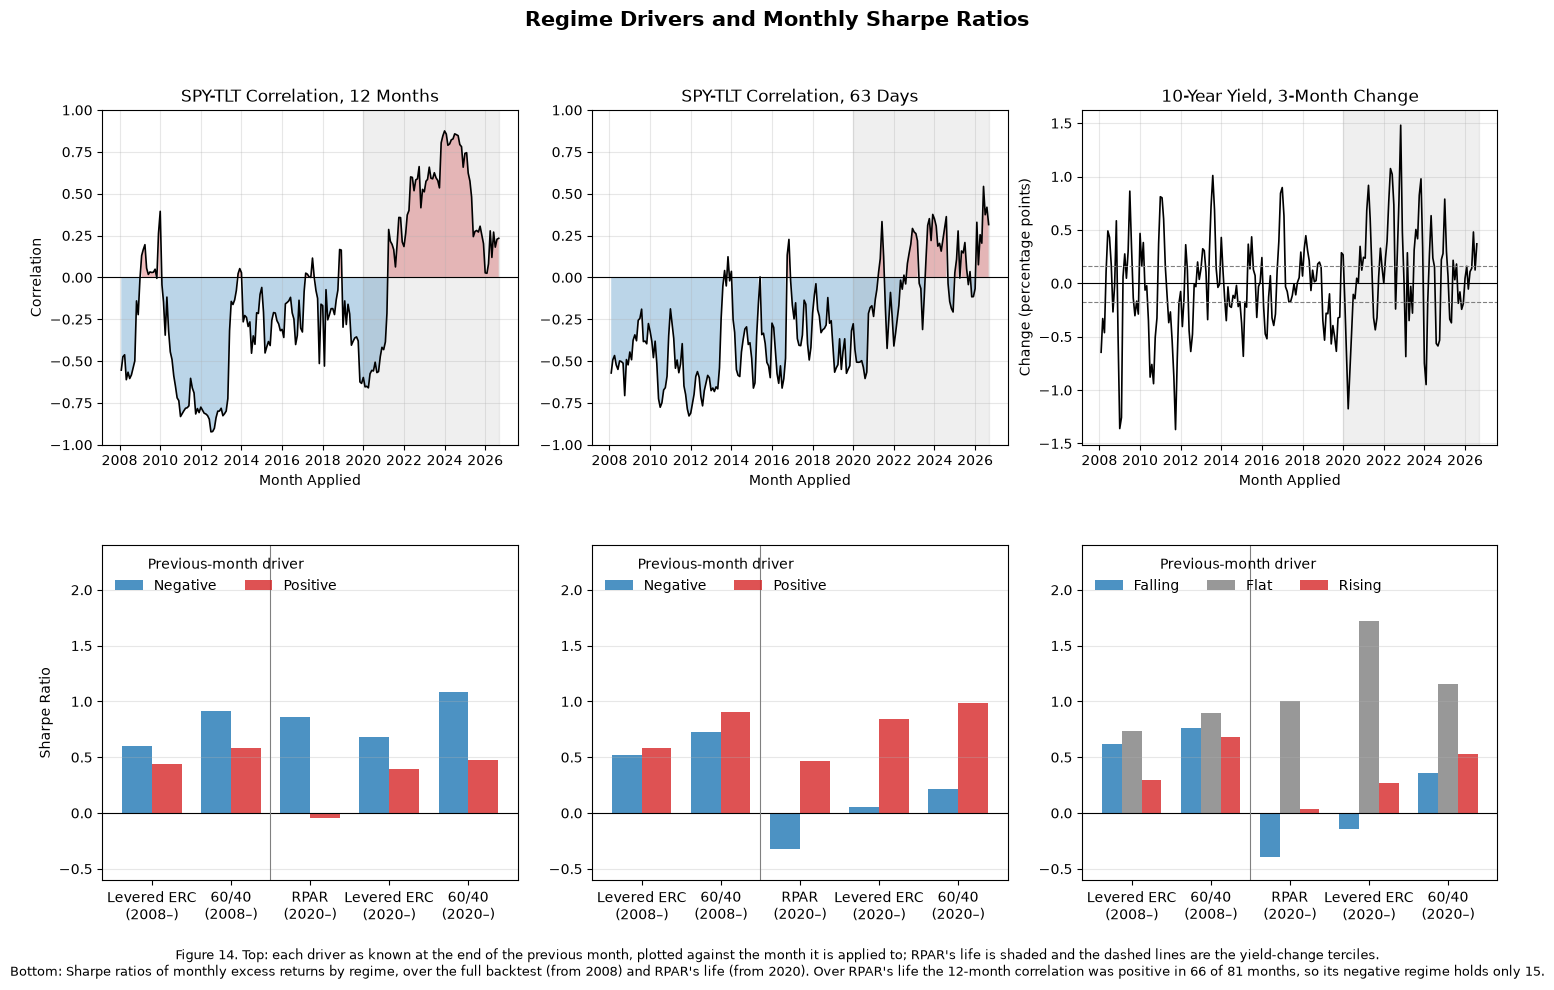

In [99]:
fig, axes = plt.subplots(2, 3, figsize = (18, 10))

regime_colors = {"Negative": "tab:blue", "Positive": "tab:red", "Falling": "tab:blue", "Flat": "tab:gray", "Rising": "tab:red"}
driver_titles = {"Stock-Bond Correlation, 12 Months": "SPY-TLT Correlation, 12 Months",
                 "Stock-Bond Correlation, 63 Days": "SPY-TLT Correlation, 63 Days",
                 "10-Year Yield, 3-Month Change": "10-Year Yield, 3-Month Change"}

for col, driver in enumerate(drivers.columns):
    #top: each driver by the month it is applied to, with RPAR's life shaded
    ax = axes[0, col]
    path = drivers.loc["2008-02":"2026-09", driver].to_timestamp()
    ax.plot(path.index, path, color = "black", linewidth = 1.2)

    if driver == YIELD_DRIVER:
        for breakpoint in yield_terciles:
            ax.axhline(breakpoint, color = "gray", linestyle = "--", linewidth = 0.8)
        ax.set_ylabel("Change (percentage points)")
    else:
        ax.fill_between(path.index, 0, path, where = path > 0, color = "tab:red", alpha = 0.3, linewidth = 0)
        ax.fill_between(path.index, 0, path, where = path <= 0, color = "tab:blue", alpha = 0.3, linewidth = 0)
        ax.set_ylim(-1, 1)
        ax.set_ylabel("Correlation" if col == 0 else "")

    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.axvspan(pd.Timestamp("2020-01-01"), path.index[-1], color = "gray", alpha = 0.12)
    ax.set(title = driver_titles[driver], xlabel = "Month Applied")
    ax.grid(alpha = 0.3)

    #bottom: Sharpe ratio in each regime, by sample and strategy
    ax = axes[1, col]
    sharpes = regime_tables[driver]["Sharpe Ratio"].unstack("Regime").reindex(regime_tables[driver].index.droplevel("Regime").unique())
    sharpes.index = [f"{strategy}\n({REGIME_SAMPLES[sample][0][:4]}–)" for sample, strategy in sharpes.index]
    sharpes.plot.bar(ax = ax, color = [regime_colors[regime] for regime in sharpes.columns], alpha = 0.8, width = 0.75, rot = 0)

    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.axvline(1.5, color = "gray", linewidth = 0.8)
    ax.set(xlabel = "", ylabel = "Sharpe Ratio" if col == 0 else "", ylim = (-0.6, 2.4))
    ax.legend(title = "Previous-month driver", frameon = False, loc = "upper left", ncol = len(sharpes.columns))
    ax.grid(alpha = 0.3, axis = "y")

fig.suptitle("Regime Drivers and Monthly Sharpe Ratios", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 14. Top: each driver as known at the end of the previous month, plotted against the month it is applied to; RPAR's life is shaded and the dashed lines are the yield-change terciles.\n"
         "Bottom: Sharpe ratios of monthly excess returns by regime, over the full backtest (from 2008) and RPAR's life (from 2020). Over RPAR's life the 12-month correlation was positive in 66 of 81 months, so its negative regime holds only 15.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.11, hspace = 0.3, wspace = 0.18)
plt.show()

> **Drivers.**
>
> * **Stock-bond correlation,** on 12 months of monthly returns and on 63 days of daily returns. It tests the diversification risk parity relies on.
> * **The three-month change in the 10-year yield.** It tests the duration-heavy weights (`TIP`, `TLT`) that drove 2022 (5.3).
>
> **Construction.**
>
> * **Timing:** each driver is measured at the close of month $t-1$ and applied to month $t$.
> * **Regimes:** the correlations are split at zero. The yield-change terciles are cut at −0.17 and +0.16 points, set on the backtest's 223 months and applied to both samples. They describe regimes and are not a trading rule.
> * **Returns:** monthly returns compound the daily ones, and excess returns subtract compounded `SHV`.
>
> **What the tables show.** Figure 14 has the drivers over time on top and the Sharpe ratio in each regime below. The top row explains the main caution: the 12-month correlation moves in a few long runs, mostly negative from 2008 to 2020 and positive since 2021. Its regimes are therefore a handful of episodes, not many independent months.
>
> * **12-month correlation:** months after a negative correlation had higher Sharpe ratios everywhere: levered ERC 0.60 against 0.44, 60/40 0.91 against 0.58, `RPAR` 0.86 against −0.05. But only 15 of `RPAR`'s 81 months were negative.
> * **63-day correlation:** the result reverses; positive months were better. The gap is small over the backtest and large over `RPAR`'s life (`RPAR` 0.47 against −0.32).
> * **Yield change:**
>   * Over the backtest, rising-yield months were the levered ERC's worst tercile (0.30, against 0.61 falling and 0.74 flat), while 60/40 barely varied (0.68–0.90).
>   * Over `RPAR`'s life, the flat tercile was best and the falling one worst.
> * **Volatility:** it varies by less than five points across regimes, so the Sharpe differences are differences in mean return.
> * **Sample size:** with 15–41 months per regime, a Sharpe ratio's standard error is about 0.5–0.9.
>
> **The tables.**
>
> * ***Months in each regime:*** comes first because every Sharpe ratio in the next tables is only as reliable as the number of months behind it. It shows just 15 negative-correlation months over `RPAR`'s life, and a 22/22/36 tercile split.
> * ***The three regime tables:*** the statistics the question asks for, one table per driver.

## 6.2

Which drivers separate good months from bad, for which strategies, and does the separation hold in both samples? Compare the two drivers in one concise interpretation, including both horizons if you chose stock-bond correlation.


In [100]:
#the hypotheses fixed in advance: negative stock-bond correlation and falling yields are the good regimes
GOOD_BAD = {"Stock-Bond Correlation, 12 Months": ("Negative", "Positive"),
            "Stock-Bond Correlation, 63 Days": ("Negative", "Positive"),
            "10-Year Yield, 3-Month Change": ("Falling", "Rising")}

#non-overlapping samples: the backtest before RPAR listed, and RPAR's life
TEST_SAMPLES = {"Before RPAR": ("2008-02", "2019-12", ["Levered ERC", "60/40"]),
                "RPAR's life": ("2020-01", "2026-09", ["RPAR", "Levered ERC", "60/40"])}

regime_tests = {}
for driver, (good, bad) in GOOD_BAD.items():
    for sample, (start, end, strategies) in TEST_SAMPLES.items():
        for strategy in strategies:
            excess = monthly_regime_excess.loc[start:end, strategy]
            stats = project_utils.regime_stats(excess, regimes.loc[start:end, driver])
            difference = project_utils.regime_difference(excess, regimes.loc[start:end, driver], good, bad)

            regime_tests[(driver, sample, strategy)] = {"Good Regime": good,
                                                        "Good / Bad Months": f"{stats.loc[good, 'Months']:.0f} / {stats.loc[bad, 'Months']:.0f}",
                                                        "Good Spells": difference["Good Spells"],
                                                        "Sharpe, Good": stats.loc[good, "Sharpe Ratio"],
                                                        "Sharpe, Bad": stats.loc[bad, "Sharpe Ratio"],
                                                        "Mean Difference (Good - Bad)": difference["Mean Difference"],
                                                        "t-stat": difference["t-stat"],
                                                        "Correlation with Driver": excess.corr(drivers[driver])}

regime_tests = pd.DataFrame(regime_tests).T
regime_tests.index.names = ["Driver", "Sample", "Strategy"]

display(regime_tests.style.format({"Good Spells": "{:.0f}",
                                   "Sharpe, Good": "{:.2f}",
                                   "Sharpe, Bad": "{:.2f}",
                                   "Mean Difference (Good - Bad)": "{:+.2%}",
                                   "t-stat": "{:+.2f}",
                                   "Correlation with Driver": "{:+.2f}"})
                          .set_caption("Good regime against bad, in two non-overlapping samples. Correlation with Driver uses the driver's value, not its regime"))

In [101]:
#the same quantities measured over the month being explained, which are not known in advance
month_end_10y = month_end_value(yields["10y zero yield (pct)"])
monthly_spy_tlt = returns[["SPY", "TLT"]].groupby(returns.index.to_period("M")).apply(lambda month: month["SPY"].corr(month["TLT"]))

measures = {"Yield Change, Previous 3 Months (Driver)": drivers[YIELD_DRIVER],
            "Yield Change, Same Month": month_end_10y.diff(),
            "SPY-TLT Correlation, Previous 63 Days (Driver)": drivers["Stock-Bond Correlation, 63 Days"],
            "SPY-TLT Correlation, Same Month": monthly_spy_tlt}

same_month = pd.DataFrame({(sample, strategy): {measure: monthly_regime_excess.loc[start:end, strategy].corr(values) for measure, values in measures.items()}
                           for sample, (start, end, strategies) in TEST_SAMPLES.items() for strategy in strategies}).T
same_month.index.names = ["Sample", "Strategy"]

display(same_month.style.format("{:+.2f}")
                  .background_gradient(cmap = "RdBu_r", vmin = -1, vmax = 1)
                  .set_caption("Correlation of monthly excess returns with each driver and with the same quantity measured over the same month"))

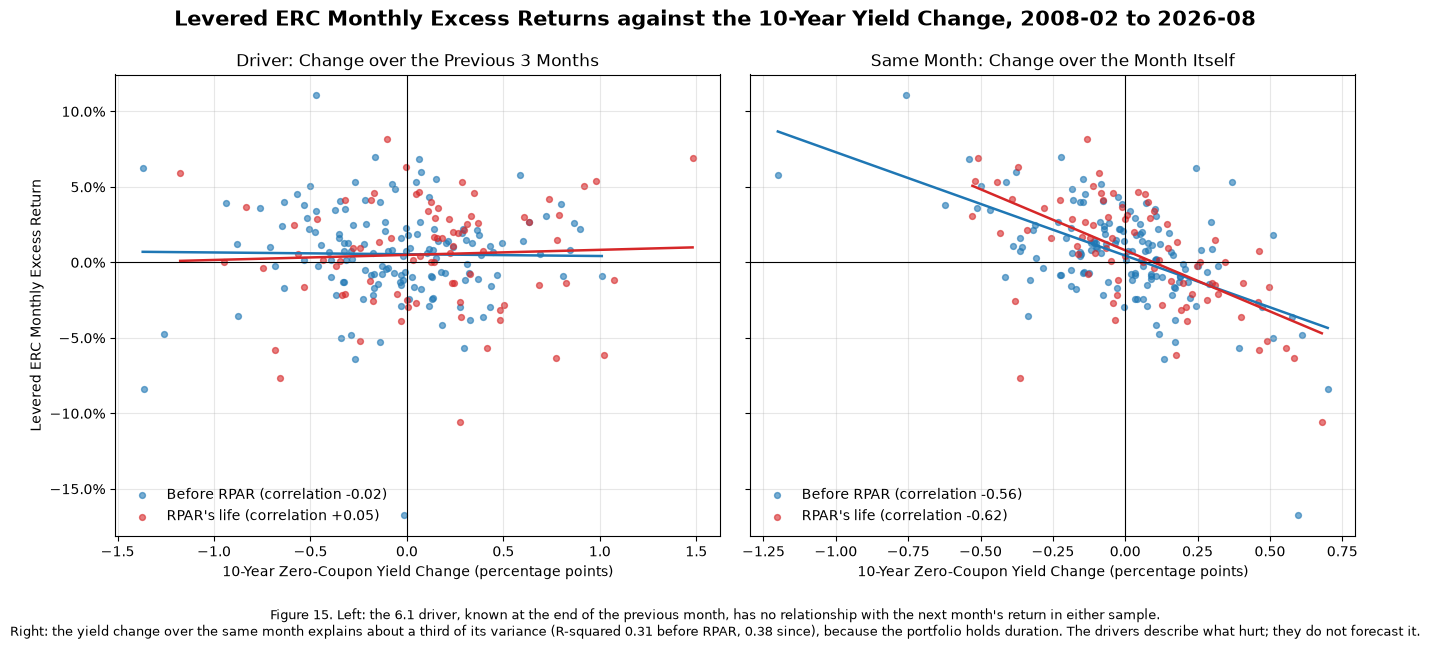

In [102]:
fig, axes = plt.subplots(1, 2, figsize = (16, 6.5), sharey = True)

scatter_sample = monthly_regime_excess.loc["2008-02":"2026-08", "Levered ERC"]
panels = {"Driver: Change over the Previous 3 Months": drivers[YIELD_DRIVER],
          "Same Month: Change over the Month Itself": month_end_10y.diff()}
sample_colors = {"Before RPAR": "tab:blue", "RPAR's life": "tab:red"}

for ax, (title, change) in zip(axes, panels.items()):
    for sample, (start, end, _) in TEST_SAMPLES.items():
        pairs = pd.concat([change.rename("x"), scatter_sample.rename("y")], axis = 1).loc[start:end].dropna()
        x, y = pairs["x"], pairs["y"]
        slope, intercept = np.polyfit(x, y, 1)
        ax.scatter(x, y, s = 18, alpha = 0.6, color = sample_colors[sample], label = f"{sample} (correlation {x.corr(y):+.2f})")
        line = np.linspace(x.min(), x.max(), 2)
        ax.plot(line, intercept + slope * line, color = sample_colors[sample], linewidth = 1.8)

    ax.set(title = title, xlabel = "10-Year Zero-Coupon Yield Change (percentage points)", ylabel = "Levered ERC Monthly Excess Return" if ax is axes[0] else "")
    ax.axhline(0, color = "black", linewidth = 0.8)
    ax.axvline(0, color = "black", linewidth = 0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(frameon = False, loc = "lower left")
    ax.grid(alpha = 0.3)

fig.suptitle("Levered ERC Monthly Excess Returns against the 10-Year Yield Change, 2008-02 to 2026-08", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, "Figure 15. Left: the 6.1 driver, known at the end of the previous month, has no relationship with the next month's return in either sample.\n"
         "Right: the yield change over the same month explains about a third of its variance (R-squared 0.31 before RPAR, 0.38 since), because the portfolio holds duration. The drivers describe what hurt; they do not forecast it.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.17, wspace = 0.05)
plt.show()

> **Neither driver separates good months from bad in both samples.**
>
> * **The test:** two non-overlapping samples, 2008–2019 and `RPAR`'s life, with the good regimes fixed in advance.
> * **The result:** no difference has a |t| above 1.1 except one cell built on six months. Each driver's correlation with next month's excess return is between −0.10 and +0.07.
>
> **By driver.**
>
> * **12-month correlation:**
>   * No effect before 2020 (levered ERC 0.58 against 0.59).
>   * The effect over `RPAR`'s life rests on one spell, January 2020 to March 2021, the COVID recovery. That is effectively one observation.
> * **63-day correlation: the result reverses between samples.**
>   * Before 2020 the correlation was positive in only six isolated months.
>   * Over `RPAR`'s life, negative months were worse ($t \approx -1.0$), because the correlation was still negative going into most of 2022.
>   * The two horizons point opposite ways over `RPAR`'s life.
> * **Yield change:** falling-yield months were better for the levered ERC before 2020 (0.93 against 0.36, $t$ = 1.10) and worse after (`RPAR` −0.39).
>
> **Comparing the two: both describe what hurts risk parity; neither forecasts it.**
>
> * **Yield changes matter in the same month.** We made Figure 15 to show why the regime splits find so little. Its left panel plots next month's return against the prior three months' yield change, the only one known in advance, and the cloud is flat. Its right panel plots the same return against the same month's change, and the cloud slopes down by about 7–8% per percentage point, the portfolio's effective duration.
>   * The month's own 10-year change correlates −0.56 to −0.74 with the levered ERC's and `RPAR`'s returns. The prior three months' change has a correlation near zero (Figure 15).
>   * Rate shocks hit duration at once and then do not persist.
>   * 60/40 showed the same-month link only after 2020 (−0.07 before, −0.54 since), when stocks and bonds stopped offsetting.
> * **Stock-bond correlation describes the environment, not the next month.** It has been positive since 2021, risk parity's weakest stretch.
>   * The 12-month signal turned positive in April 2021 and stayed positive through the recovery.
>   * The 63-day signal turned only after 2022's damage began.
>
> **Neither driver justifies switching allocations.**
>
> **The tables.**
>
> * ***Good regime against bad:*** the formal test. It fixes the hypothesis in advance, uses two non-overlapping samples, and reports t-statistics and the number of separate spells, that is, how many independent episodes stand behind each regime.
> * ***Correlation with each driver and with the same quantity in the same month:*** separates "describes" from "forecasts". The same-month yield change is strongly related to returns (−0.54 to −0.74 where it matters); the drivers, known in advance, are near zero.

***


# 7. The Allocation

Choose the evaluation criteria, cost assumptions, allocation rule, and comparison window. Different allocations and recommendations can be supported by the evidence; explain the choices that determine yours.


## 7.1

Before computing any Section 7 result, write a dated markdown cell stating

* at least three pass-fail criteria a strategy must meet for you to run it, each numeric and tied to a statistic from Sections 1 to 6
* a cost per unit of one-way turnover
* a borrowing spread over `SHV` on levered exposure

Give a source or a one-sentence rationale for each cost. Keep the original declaration. Record any revision in a second dated cell. The design uses evidence from the full history; Section 7 is a retrospective evaluation, not an untouched test.


> **Declaration, 2026-10-30.** Written before any Section 7 result was computed. The thresholds use evidence from Sections 1 to 6, which cover the full history, so Section 7 is a retrospective check against these thresholds, not an untouched test.
>
> **Pass-fail criteria.** A strategy must pass all four, on the window it is evaluated over, for us to run it. Each comparison with 60/40 uses the same window, and the live funds' returns are already net of their fees.
>
> 1. **Sharpe ratio above the diversification hurdle.** Net Sharpe ratio > (correlation of its daily returns with 60/40) × (60/40's Sharpe ratio).
>    * *Why this hurdle:* adding a small weight of a strategy to 60/40 raises 60/40's Sharpe ratio only if the strategy clears it.
>    * *Reference values:* 60/40's Sharpe ratio was 0.66 over the full backtest (4.2) and 0.57 over `RPAR`'s life (4.4). `RPAR`'s daily correlation with 60/40 was 0.70 (Figure 1). Together those put the hurdle near 0.40.
> 2. **Maximum drawdown no deeper than 60/40's.**
>    * *Reference values:* 60/40's maximum drawdown was −30.8% over the full backtest (4.2) and −21.0% over `RPAR`'s life (1.1).
>    * *Why:* a risk-balanced portfolio is sold on avoiding the deep losses of a stock-heavy one. If it does not, its lower Sharpe ratio buys nothing.
> 3. **2022 calendar-year total return no worse than 60/40's −16.4%** (1.1, 4.2).
>    * *Why:* 5.3 and 5.4 identified 2022, when stocks and bonds fell together, as the scenario risk parity is most exposed to.
>    * *Reference values:* `RPAR` lost 22.8% that year and the unlevered ERC 11.7%.
> 4. **Daily correlation with 60/40 of at most 0.80.**
>    * *Why:* above that level a strategy is mostly a re-levered 60/40, which `NTSX` (correlation 0.97, Figure 1) already offers for a 0.20% fee.
>    * *Reference values:* the risk-parity products sit at 0.70 to 0.75 (Figure 1).
>
> **Costs.** These apply to our strategy and to the levered ERC portfolio. The live funds already bear their own costs.
>
> * **Trading: 0.10% per unit of one-way turnover** (10 basis points of the value traded).
>   * *Rationale:* all five ETFs are large, exchange-listed U.S. funds. 10 basis points is a conservative allowance for half the bid-ask spread plus market impact and commissions, set high enough to cover `DBC`, the least liquid of them.
> * **Borrowing: 0.75% a year over `SHV`** on the borrowed amount (gross exposure minus net asset value), charged daily.
>   * *Source:* Interactive Brokers' IBKR Pro USD margin rates are its benchmark rate plus 1% on balances from \$100,000 to \$1 million, plus 0.75% from \$1 million to \$50 million, and plus 0.5% above that (interactivebrokers.com, Margin Rates and Financing, accessed 2026-10-30). We take the middle tier as the cost for an allocator of moderate size.
>   * *A conservative choice:* financing through Treasury futures, as `RPAR` does, would usually be cheaper.
>
> At the 4.3 levered ERC's leverage (1.55x) and turnover (0.35 a year), these costs come to about 0.45% a year. That is below `RPAR`'s 0.52% expense ratio, so running the rule directly is not ruled out by cost.

In [103]:
#costs declared in 7.1, as fractions: per unit of one-way turnover, and per year over SHV on the borrowed amount
COST_PER_TURNOVER = 0.0010
BORROW_SPREAD = 0.0075

#pass-fail criteria declared in 7.1; each compares a strategy with 60/40 over the same window
CRITERIA = {"Sharpe above diversification hurdle": "Net Sharpe > correlation with 60/40 x 60/40's Sharpe",
            "Max drawdown no deeper than 60/40's": "Max drawdown >= 60/40's max drawdown",
            "2022 return no worse than 60/40's": "2022 calendar-year total return >= 60/40's (-16.4%)",
            "Correlation with 60/40 at most 0.80": "Daily return correlation with 60/40 <= 0.80"}
MAX_CORRELATION_WITH_6040 = 0.80

display(pd.Series(CRITERIA, name = "Rule").to_frame().style.set_caption("Pass-fail criteria declared 2026-10-30"))
print(f"Trading cost {COST_PER_TURNOVER:.2%} per unit of one-way turnover; borrowing spread {BORROW_SPREAD:.2%} a year over SHV on the borrowed amount")

,Rule
Sharpe above diversification hurdle,Net Sharpe > correlation with 60/40 x 60/40's Sharpe
Max drawdown no deeper than 60/40's,Max drawdown >= 60/40's max drawdown
2022 return no worse than 60/40's,2022 calendar-year total return >= 60/40's (-16.4%)
Correlation with 60/40 at most 0.80,Daily return correlation with 60/40 <= 0.80


Trading cost 0.10% per unit of one-way turnover; borrowing spread 0.75% a year over SHV on the borrowed amount


## 7.2

Build one risk-balanced strategy you would run, from the asset-class ETFs and, if you choose, a sleeve of `DBMF` or another live fund. Any signal uses information available at the month-end before it acts. State the rule in full. Backtest it over the longest window the rule allows and report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, plus any other metric needed to apply your criteria
* one-way turnover per year
* returns gross and net of the costs declared in 7.1


> **Rule: trend-filtered ERC at a 10% volatility target.** At each month-end close $t-1$, using data through that close:
>
> 1. **Weights:** ERC on `SPY`, `TLT`, `TIP`, `GLD` and `DBC`, from the trailing 252-day sample covariance (4.1).
> 2. **Leverage:** $L = \min(10\%/\hat\sigma,\ 2)$, with $\hat\sigma = \sqrt{252\,\boldsymbol{w}'\hat\Sigma\boldsymbol{w}}$.
> 3. **Trend filter:** an asset whose summed daily excess return over the trailing 252 days is not positive gets a zero position, and its share stays in `SHV`. The filter is applied after leverage, so a removed asset's risk is not handed to the others.
> 4. **Cash and costs:** cash is one minus the positions. Borrowing costs `SHV` plus 0.75%, and trading costs 0.10% per unit of one-way turnover (7.1).
> 5. **Holding:** no trading until the next month-end.
>
> The backtest runs from 2007-03-01 to 2026-10-23, the longest the 252-day window allows.
>
> **Why this rule.**
>
> * **ERC base:** it balances risk across the asset classes. 4.4 found that `RPAR`, with a similar allocation, trailed this simplified benchmark.
> * **Volatility target:** it replaces 4.3's hindsight leverage with one set from data known at the time. The 2x cap limits financing risk; `UPAR` runs 1.6–1.8x.
> * **Trend filter:** it targets the 2022 failure (5.3, 5.4), when bonds and TIPS fell for months while the trailing covariance still showed them diversifying. 6.2 found that no driver times this in advance, and a filter makes no forecast.
> * **No `DBMF` sleeve:** it would cut the backtest to six years.

In [104]:
#7.2 strategy: ERC weights from the earliest full 252-day window (4.2), scaled to a 10% volatility target, then trend-filtered
TARGET_VOL = 0.10
MAX_LEVERAGE = 2.0

strategy_targets, strategy_leverage = project_utils.trend_filtered_positions(returns[RP_ASSETS], excess_returns[RP_ASSETS], early_erc_weights,
                                                                             target_vol = TARGET_VOL, max_leverage = MAX_LEVERAGE)

strategy_gross, strategy_positions, strategy_turnover = project_utils.levered_backtest(returns[RP_ASSETS], strategy_targets, returns["SHV"], leverage = 1.0)
strategy_net = project_utils.net_of_costs(strategy_gross, strategy_positions, strategy_turnover, COST_PER_TURNOVER, BORROW_SPREAD)

strategy_dates = strategy_gross.index
strategy_years = len(strategy_dates) / 252

strategy_comparison = pd.DataFrame({"Strategy, net": strategy_net,
                                    "Strategy, gross": strategy_gross,
                                    "ERC, unlevered (4.2)": early_erc_returns.loc[strategy_dates],
                                    "60/40": returns.loc[strategy_dates, "60/40"]})

strategy_stats = project_utils.performance_stats(strategy_comparison, returns.loc[strategy_dates, "SHV"])[stat_cols]

#metrics the 7.1 criteria use, each against 60/40 over the same window
strategy_stats["2022 Return"] = [(1 + strategy_comparison.loc["2022", col]).prod() - 1 for col in strategy_comparison]
strategy_stats["Correlation with 60/40"] = strategy_comparison.corr()["60/40"]
strategy_stats["Sharpe Hurdle"] = strategy_stats["Correlation with 60/40"] * strategy_stats.loc["60/40", "Sharpe Ratio"]

#turnover and costs, for the strategy only; the unlevered ERC's turnover is in 4.3
strategy_stats["One-Way Turnover per Year"] = [strategy_turnover.sum() / strategy_years] * 2 + [np.nan] * 2
strategy_stats["Average Gross Exposure"] = [strategy_positions.sum(axis = 1).mean()] * 2 + [1.0, 1.0]
strategy_stats["Annual Cost"] = [(strategy_gross - strategy_net).mean() * 252, 0.0, np.nan, np.nan]

display(strategy_stats.style.format({**backtest_format,
                                     "2022 Return": "{:.2%}",
                                     "Correlation with 60/40": "{:.2f}",
                                     "Sharpe Hurdle": "{:.2f}",
                                     "One-Way Turnover per Year": "{:.2f}",
                                     "Average Gross Exposure": "{:.2f}",
                                     "Annual Cost": "{:.2%}"}, na_rep = "—")
                      .set_caption(f"Trend-filtered ERC at a {TARGET_VOL:.0%} volatility target, {strategy_dates[0].date()} to {strategy_dates[-1].date()}; "
                                   f"costs {COST_PER_TURNOVER:.2%} per unit of turnover and {BORROW_SPREAD:.2%} a year on borrowing"))

#how often each asset was filtered out, and how the leverage was set
filtered_share = (strategy_targets == 0).mean()
cost_split = pd.Series({"Trading": (strategy_turnover.reindex(strategy_dates).shift(1).fillna(0) * COST_PER_TURNOVER).sum() / strategy_years,
                        "Financing": ((strategy_positions.sum(axis = 1) - 1).clip(lower = 0) * BORROW_SPREAD / 252).sum() / strategy_years})

print(f"Leverage before the filter: median {strategy_leverage.median():.2f}x, at the {MAX_LEVERAGE:.0f}x cap in {(strategy_leverage >= MAX_LEVERAGE).mean():.0%} of months. "
      f"Months with net borrowing: {(strategy_targets.sum(axis = 1) > 1).mean():.0%}; with every asset filtered out: {(strategy_targets.sum(axis = 1) == 0).mean():.0%}.")
print("Share of months each asset was filtered out: " + ", ".join(f"{asset} {share:.0%}" for asset, share in filtered_share.items()))
print(f"Annual cost: trading {cost_split['Trading']:.2%}, financing {cost_split['Financing']:.2%}")

#removing an asset usually lowers risk, but not when the asset removed was hedging the others
def forecast_vol(date, positions):
    cov = returns[RP_ASSETS].dropna().loc[:date].iloc[-252:].cov()
    return np.sqrt(positions @ cov @ positions * 252)

filter_raised_vol = sum(forecast_vol(date, strategy_targets.loc[date]) > forecast_vol(date, strategy_leverage[date] * w) + 1e-12
                        for date, w in early_erc_weights.iterrows())
print(f"Months in which the filter raised the forecast volatility: {filter_raised_vol} of {len(early_erc_weights)}")

,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown,Peak Date,Trough Date,Recovery Date,2022 Return,Correlation with 60/40,Sharpe Hurdle,One-Way Turnover per Year,Average Gross Exposure,Annual Cost
"Strategy, net",7.25%,8.77%,0.65,-22.74%,2020-03-06,2020-03-18,2020-08-06,-6.79%,0.39,0.24,1.33,1.06,0.33%
"Strategy, gross",7.58%,8.77%,0.69,-22.73%,2020-03-06,2020-03-18,2020-08-06,-6.60%,0.39,0.24,1.33,1.06,0.00%
"ERC, unlevered (4.2)",5.93%,7.20%,0.60,-17.97%,2022-03-08,2022-10-20,2024-07-16,-11.70%,0.60,0.38,—,1.00,—
60/40,8.70%,11.25%,0.63,-31.41%,2007-12-10,2009-03-09,2010-09-20,-16.38%,1.00,0.63,—,1.00,—


Leverage before the filter: median 1.59x, at the 2x cap in 19% of months. Months with net borrowing: 56%; with every asset filtered out: 1%.
Share of months each asset was filtered out: SPY 16%, TLT 44%, TIP 37%, GLD 28%, DBC 48%
Annual cost: trading 0.13%, financing 0.20%
Months in which the filter raised the forecast volatility: 6 of 236


In [105]:
#the same rule with one setting changed at a time, net of the 7.1 costs, to check whether the result depends on the chosen settings
variants = {"Chosen (10%, 2x, 12-month filter)": {},
            "No trend filter": {"lookback": None},
            "8% target": {"target_vol": 0.08},
            "12% target": {"target_vol": 0.12},
            "1.5x cap": {"max_leverage": 1.5},
            "6-month filter": {"lookback": 126}}

variant_stats = {}
for name, settings in variants.items():
    settings = {"target_vol": TARGET_VOL, "max_leverage": MAX_LEVERAGE, "lookback": 252, **settings}
    targets, _ = project_utils.trend_filtered_positions(returns[RP_ASSETS], excess_returns[RP_ASSETS], early_erc_weights, **settings)
    gross, positions, turnover = project_utils.levered_backtest(returns[RP_ASSETS], targets, returns["SHV"], leverage = 1.0)
    net = project_utils.net_of_costs(gross, positions, turnover, COST_PER_TURNOVER, BORROW_SPREAD)

    stats = project_utils.performance_stats(net.to_frame(name), returns.loc[net.index, "SHV"]).iloc[0]
    variant_stats[name] = {"Annualized Mean": stats["Annualized Mean"],
                           "Annualized Volatility": stats["Annualized Volatility"],
                           "Sharpe Ratio": stats["Sharpe Ratio"],
                           "Max Drawdown": stats["Max Drawdown"],
                           "2022 Return": (1 + net.loc["2022"]).prod() - 1,
                           "Correlation with 60/40": net.corr(returns.loc[net.index, "60/40"]),
                           "One-Way Turnover per Year": turnover.sum() / (len(net) / 252)}

variant_stats = pd.DataFrame(variant_stats).T

display(variant_stats.style.format({"Annualized Mean": "{:.2%}", "Annualized Volatility": "{:.2%}", "Sharpe Ratio": "{:.2f}", "Max Drawdown": "{:.2%}",
                                    "2022 Return": "{:.2%}", "Correlation with 60/40": "{:.2f}", "One-Way Turnover per Year": "{:.2f}"})
                     .set_caption("Sensitivity to the rule's settings, net of costs, same window"))

,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown,2022 Return,Correlation with 60/40,One-Way Turnover per Year
"Chosen (10%, 2x, 12-month filter)",7.25%,8.77%,0.65,-22.74%,-6.79%,0.39,1.33
No trend filter,7.28%,10.95%,0.52,-29.07%,-15.30%,0.58,0.48
8% target,6.26%,7.19%,0.65,-18.82%,-5.24%,0.39,1.12
12% target,8.08%,9.85%,0.66,-22.74%,-8.35%,0.38,1.45
1.5x cap,6.83%,7.73%,0.68,-17.24%,-6.76%,0.38,1.11
6-month filter,7.43%,8.46%,0.69,-22.74%,-6.92%,0.31,1.88


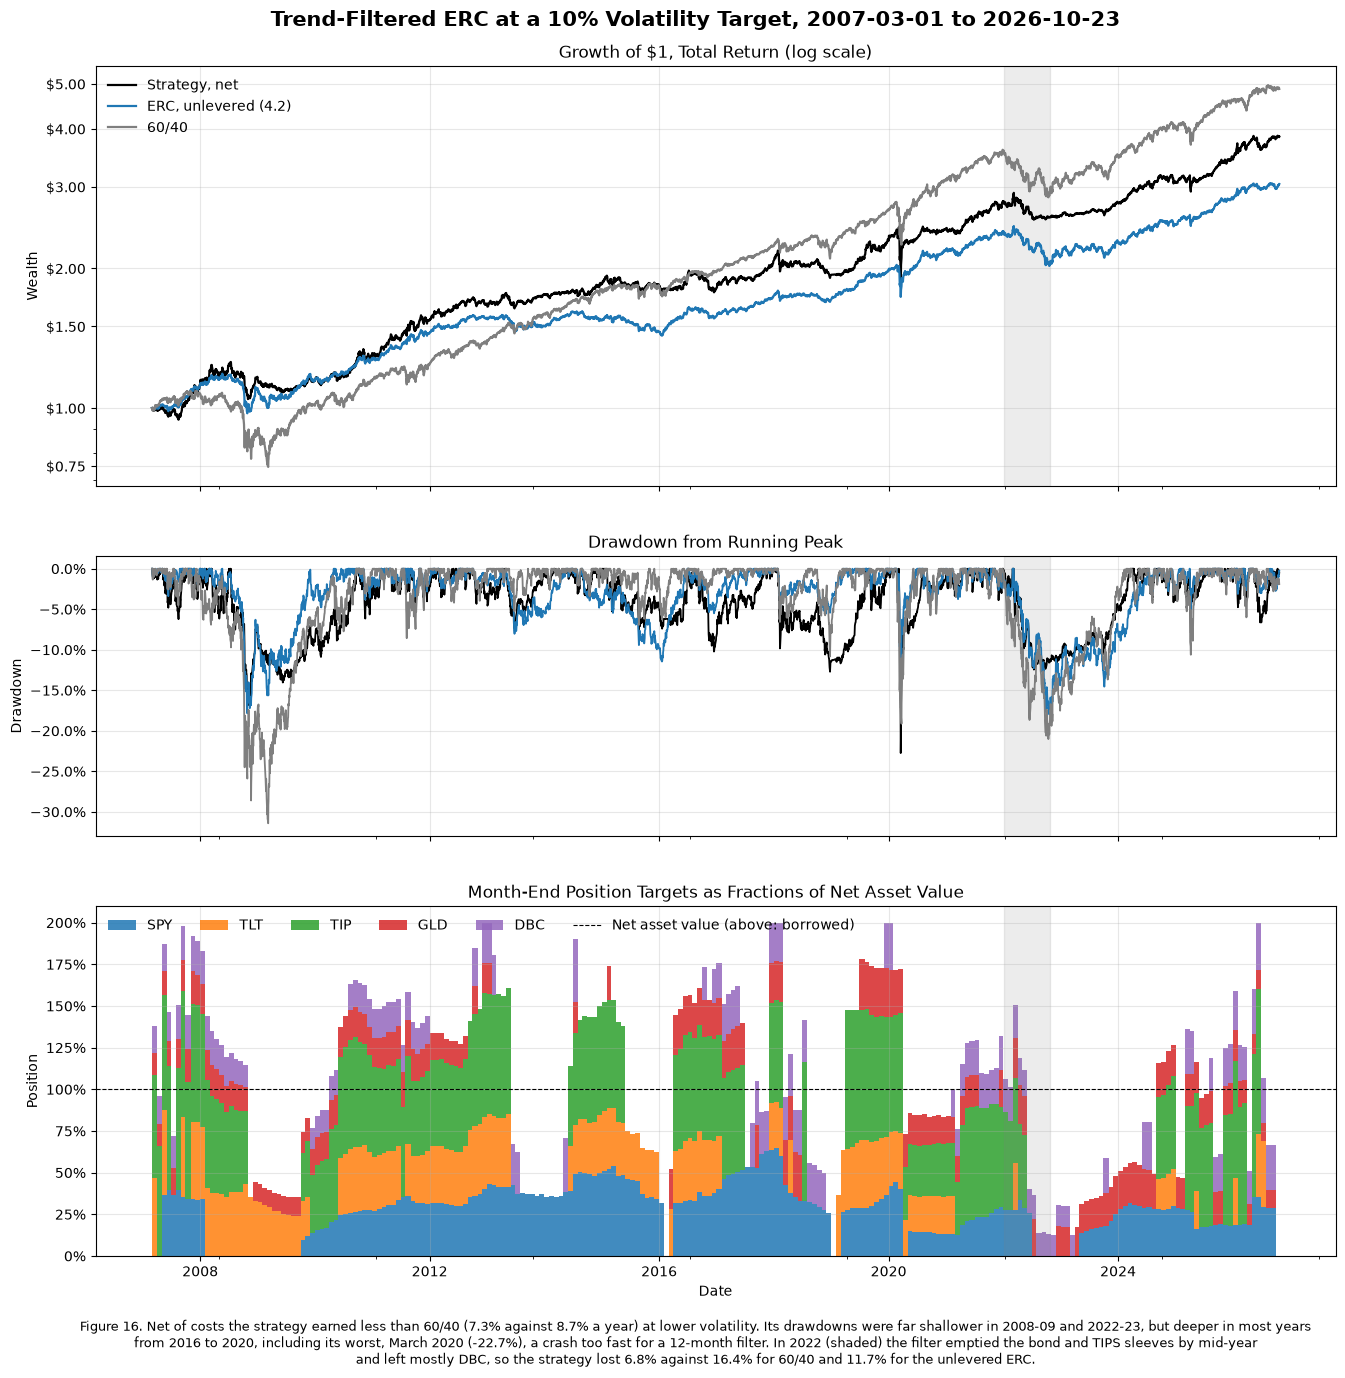

In [106]:
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(3, 1, figsize = (16, 14), sharex = True, gridspec_kw = {"height_ratios": [1.2, 0.8, 1]})

path_cols = {"Strategy, net": "black", "ERC, unlevered (4.2)": "tab:blue", "60/40": "tab:gray"}

#growth of $1 from the close before the first return, so a first-day loss counts
wealth = (1 + strategy_comparison[list(path_cols)]).cumprod()
wealth = pd.concat([pd.DataFrame(1.0, index = [early_erc_weights.index[0]], columns = wealth.columns), wealth])

ax = axes[0]
wealth.plot(ax = ax, color = list(path_cols.values()), linewidth = 1.6, logy = True)
ax.set(title = "Growth of $1, Total Return (log scale)", ylabel = "Wealth")
ax.set_yticks([0.75, 1, 1.5, 2, 3, 4, 5])
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:.2f}"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda y, _: ""))
ax.legend(frameon = False, loc = "upper left")

ax = axes[1]
(wealth / wealth.cummax() - 1).plot(ax = ax, color = list(path_cols.values()), linewidth = 1.3, legend = False)
ax.set(title = "Drawdown from Running Peak", ylabel = "Drawdown")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

#positions set at each month-end, held through the following month
ax = axes[2]
targets_plot = strategy_targets.copy()
targets_plot.index = targets_plot.index + pd.offsets.Day(1)
ax.stackplot(targets_plot.index, targets_plot.T.values, labels = RP_ASSETS, step = "post", alpha = 0.85,
             colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"])
ax.axhline(1, color = "black", linestyle = "--", linewidth = 0.8, label = "Net asset value (above: borrowed)")
ax.set(title = "Month-End Position Targets as Fractions of Net Asset Value", ylabel = "Position", xlabel = "Date")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(frameon = False, loc = "upper left", ncol = 6)

for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-24"), color = "gray", alpha = 0.15)
    ax.grid(alpha = 0.3)

fig.suptitle(f"Trend-Filtered ERC at a {TARGET_VOL:.0%} Volatility Target, {strategy_dates[0].date()} to {strategy_dates[-1].date()}", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, f"Figure 16. Net of costs the strategy earned less than 60/40 ({strategy_stats.loc['Strategy, net', 'Annualized Mean']:.1%} against {strategy_stats.loc['60/40', 'Annualized Mean']:.1%} a year) at lower volatility. Its drawdowns were far shallower in 2008-09 and 2022-23, but deeper in most years\n"
         f"from 2016 to 2020, including its worst, March 2020 ({strategy_stats.loc['Strategy, net', 'Max Drawdown']:.1%}), a crash too fast for a 12-month filter. "
         "In 2022 (shaded) the filter emptied the bond and TIPS sleeves by mid-year\nand left mostly DBC, so the strategy lost "
         f"{-strategy_stats.loc['Strategy, net', '2022 Return']:.1%} against {-strategy_stats.loc['60/40', '2022 Return']:.1%} for 60/40 and "
         f"{-strategy_stats.loc['ERC, unlevered (4.2)', '2022 Return']:.1%} for the unlevered ERC.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.09, hspace = 0.2, top = 0.94)
plt.show()

> **Results, 2007-03-01 to 2026-10-23**
>
> | | Strategy (net) | Strategy (gross) | 60/40 |
> |---|---:|---:|---:|
> | Annualized mean | 7.25% | 7.58% | 8.70% |
> | Annualized volatility | 8.77% | 8.77% | 11.25% |
> | Sharpe ratio | 0.65 | 0.69 | 0.63 |
> | Maximum drawdown | −22.7% | −22.7% | −31.4% |
> | 2022 total return | −6.8% | −6.6% | −16.4% |
>
> **Figure 16** shows growth, drawdowns and the positions the rule held. The bottom panel is the mechanism: through 2022 the bond and TIPS bands disappear one by one, leaving mostly `DBC`. That is why the strategy lost 6.8% that year while the unlevered ERC lost 11.7%.
>
> * **Criteria metrics:**
>   * The maximum drawdown ran from 2020-03-06 to 2020-03-18, recovered by 2020-08-06.
>   * Correlation with 60/40 is 0.39, so the Sharpe hurdle is 0.24.
> * **Turnover and costs:**
>   * Turnover is 1.33 a year, about four times the levered ERC's 0.35, mostly from filter switches.
>   * Costs are 0.33% a year (0.13% trading, 0.20% financing), which costs 0.04 of Sharpe ratio.
> * **Exposure:**
>   * Median target leverage was 1.59x, at the 2x cap in 19% of months.
>   * The filter cut average gross exposure to 1.06x. Assets were filtered out in these shares of months: `SPY` 16%, `GLD` 28%, `TIP` 37%, `TLT` 44%, `DBC` 48%.
>   * So realized volatility (8.8%) is below the target.
> * **Against the unlevered ERC:**
>   * Better on Sharpe ratio (0.65 against 0.60), 2022 (−6.8% against −11.7%) and correlation with 60/40 (0.39 against 0.60).
>   * Worse on drawdown (−22.7% against −18.0%). Exposure was near its peak entering 2020 (2x at the end of 2019, 1.72x at the end of February), and March fell too fast for a month-end filter.
> * **Sensitivity:**
>   * An 8% or 12% target, a 1.5x cap or a 6-month filter keeps the Sharpe ratio at 0.65–0.69 and 2022 at −5.2% to −8.3%.
>   * Without the filter: Sharpe ratio 0.52, drawdown −29.1%, 2022 −15.3%.
>   * The filter does the work. Leverage alone does not improve ERC after financing costs.
> * **Caveats:**
>   * The filter was chosen knowing 2022 hurt risk parity, so being robust across settings does not make it out of sample.
>   * It earns less than 60/40, and fast crashes remain its weak point.
>
> **The table.** *Sensitivity to the rule's settings* changes one setting at a time, to show the result is not tuned to the chosen parameters. Its no-filter row isolates what the trend filter contributes.

## 7.3

Place your strategy beside `RPAR`, `ALLW`, `NTSX`, `DBMF`, the levered ERC portfolio from 4.3 and 60/40 on one common window you choose. Report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, net of your declared costs where leverage or turnover applies; add any metric needed for your criteria
* the pairwise correlations of daily returns on the common window


In [107]:
#common window: RPAR's life, which contains both episodes; ALLW joins on its first return
COMMON_START, COMMON_END = "2019-12-16", "2026-10-23"
COMPARISON = ["7.2 Strategy", "RPAR", "ALLW", "NTSX", "DBMF", "Levered ERC", "60/40"]

#the levered ERC from 4.3, now charged the 7.1 costs on its turnover and borrowing
levered_erc_net = project_utils.net_of_costs(levered_erc_returns, levered_erc_positions, levered_erc_turnover, COST_PER_TURNOVER, BORROW_SPREAD)

comparison_returns = pd.concat([strategy_net.rename("7.2 Strategy"), returns[["RPAR", "ALLW", "NTSX", "DBMF", "60/40"]],
                                levered_erc_net.rename("Levered ERC")], axis = 1)[COMPARISON].loc[COMMON_START:COMMON_END]

def comparison_table(df, with_2022 = True):
    stats = project_utils.performance_stats(df, returns.loc[df.index, "SHV"])[stat_cols]
    if with_2022:
        stats["2022 Return"] = [(1 + df.loc["2022", col]).prod() - 1 if df.loc["2022", col].notna().all() else np.nan for col in df]
    stats["Correlation with 60/40"] = df.corr()["60/40"]

    #60/40 over each series' own dates, the comparison the 7.1 criteria make
    same_dates = {col: project_utils.performance_stats(df.loc[df[col].notna(), ["60/40"]], returns.loc[df.index[df[col].notna()], "SHV"]).iloc[0] for col in df}
    stats["60/40 Sharpe, Same Dates"] = [same_dates[col]["Sharpe Ratio"] for col in df]
    stats["60/40 Max Drawdown, Same Dates"] = [same_dates[col]["Max Drawdown"] for col in df]
    stats["Sharpe Hurdle"] = stats["Correlation with 60/40"] * stats["60/40 Sharpe, Same Dates"]
    stats.insert(0, "First Return", df.apply(pd.Series.first_valid_index))
    return stats

comparison_format = {**backtest_format, "First Return": format_date, "2022 Return": "{:.2%}", "Correlation with 60/40": "{:.2f}", "Sharpe Hurdle": "{:.2f}",
                     "60/40 Sharpe, Same Dates": "{:.2f}", "60/40 Max Drawdown, Same Dates": "{:.2%}"}

common_stats = comparison_table(comparison_returns)
display(common_stats.style.format(comparison_format, na_rep = "—")
                    .set_caption(f"Common window {COMMON_START} to {COMMON_END}. Net of the 7.1 costs for the 7.2 strategy and the levered ERC; fund returns are net of their fees. "
                                 "ALLW starts 2025-03-07, so its statistics, correlation and hurdle use its own shorter sample, against 60/40 on the same dates"))

#ALLW's own window, every series on the same dates
allw_window = comparison_returns.loc[comparison_returns["ALLW"].first_valid_index():]
allw_stats = comparison_table(allw_window, with_2022 = False).drop(columns = "First Return")
display(allw_stats.style.format(comparison_format, na_rep = "—")
                  .set_caption(f"ALLW's window, {allw_window.index[0].date()} to {allw_window.index[-1].date()} ({len(allw_window)} days)"))

#pairwise correlations of daily returns; ALLW's pairs cover its window only
comparison_corr = comparison_returns.corr()
display(comparison_corr.style.format("{:.2f}")
                       .background_gradient(cmap = "RdBu_r", vmin = -1, vmax = 1)
                       .set_caption(f"Correlations of daily returns, {COMMON_START} to {COMMON_END}; pairs with ALLW from 2025-03-07"))

print(f"Costs on the levered ERC over the common window: {(levered_erc_returns - levered_erc_net).loc[COMMON_START:COMMON_END].mean() * 252:.2%} a year; "
      f"on the 7.2 strategy: {(strategy_gross - strategy_net).loc[COMMON_START:COMMON_END].mean() * 252:.2%} a year")

/var/folders/pv/4rsqtxv97lsf231gjnc_ddg00000gn/T/ipykernel_28278/1449299620.py:8: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  comparison_returns = pd.concat([strategy_net.rename("7.2 Strategy"), returns[["RPAR", "ALLW", "NTSX", "DBMF", "60/40"]],


,First Return,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown,Peak Date,Trough Date,Recovery Date,2022 Return,Correlation with 60/40,"60/40 Sharpe, Same Dates","60/40 Max Drawdown, Same Dates",Sharpe Hurdle
7.2 Strategy,2019-12-16,8.16%,9.32%,0.58,-22.74%,2020-03-06,2020-03-18,2020-08-06,-6.79%,0.55,0.57,-21.02%,0.31
RPAR,2019-12-16,4.32%,12.56%,0.13,-30.14%,2021-11-09,2022-10-20,2026-01-26,-22.80%,0.70,0.57,-21.02%,0.40
ALLW,2025-03-07,12.80%,12.10%,0.74,-8.78%,2025-04-02,2025-04-08,2025-06-02,—,0.75,0.84,-8.15%,0.63
NTSX,2019-12-16,13.25%,19.08%,0.55,-31.34%,2021-12-27,2022-10-14,2024-06-12,-25.84%,0.97,0.57,-21.02%,0.55
DBMF,2019-12-16,9.47%,12.46%,0.54,-20.44%,2022-10-20,2023-03-24,2025-12-19,21.53%,0.10,0.57,-21.02%,0.06
Levered ERC,2019-12-16,8.60%,12.94%,0.46,-27.14%,2022-03-08,2022-10-20,2025-06-17,-18.86%,0.67,0.57,-21.02%,0.39
60/40,2019-12-16,9.69%,12.14%,0.57,-21.02%,2021-12-27,2022-10-14,2024-02-22,-16.38%,1.00,0.57,-21.02%,0.57


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown,Peak Date,Trough Date,Recovery Date,Correlation with 60/40,"60/40 Sharpe, Same Dates","60/40 Max Drawdown, Same Dates",Sharpe Hurdle
7.2 Strategy,13.97%,9.56%,1.06,-7.72%,2025-04-02,2025-04-08,2025-07-18,0.61,0.84,-8.15%,0.51
RPAR,9.64%,11.19%,0.52,-9.18%,2026-02-27,2026-10-07,—,0.73,0.84,-8.15%,0.61
ALLW,12.80%,12.10%,0.74,-8.78%,2025-04-02,2025-04-08,2025-06-02,0.75,0.84,-8.15%,0.63
NTSX,17.59%,16.65%,0.83,-12.29%,2025-03-25,2025-04-08,2025-05-12,0.96,0.84,-8.15%,0.80
DBMF,20.83%,11.31%,1.50,-6.10%,2026-02-27,2026-03-23,2026-06-02,0.28,0.84,-8.15%,0.23
Levered ERC,14.46%,10.31%,1.03,-8.34%,2025-04-02,2025-04-08,2025-06-13,0.63,0.84,-8.15%,0.52
60/40,12.65%,10.55%,0.84,-8.15%,2025-03-25,2025-04-08,2025-05-12,1.00,0.84,-8.15%,0.84


,7.2 Strategy,RPAR,ALLW,NTSX,DBMF,Levered ERC,60/40
7.2 Strategy,1.00,0.67,0.81,0.51,0.39,0.81,0.55
RPAR,0.67,1.00,0.90,0.65,0.01,0.88,0.70
ALLW,0.81,0.90,1.00,0.72,0.39,0.88,0.75
NTSX,0.51,0.65,0.72,1.00,0.11,0.62,0.97
DBMF,0.39,0.01,0.39,0.11,1.00,0.10,0.10
Levered ERC,0.81,0.88,0.88,0.62,0.10,1.00,0.67
60/40,0.55,0.70,0.75,0.97,0.10,0.67,1.00


Costs on the levered ERC over the common window: 0.45% a year; on the 7.2 strategy: 0.23% a year


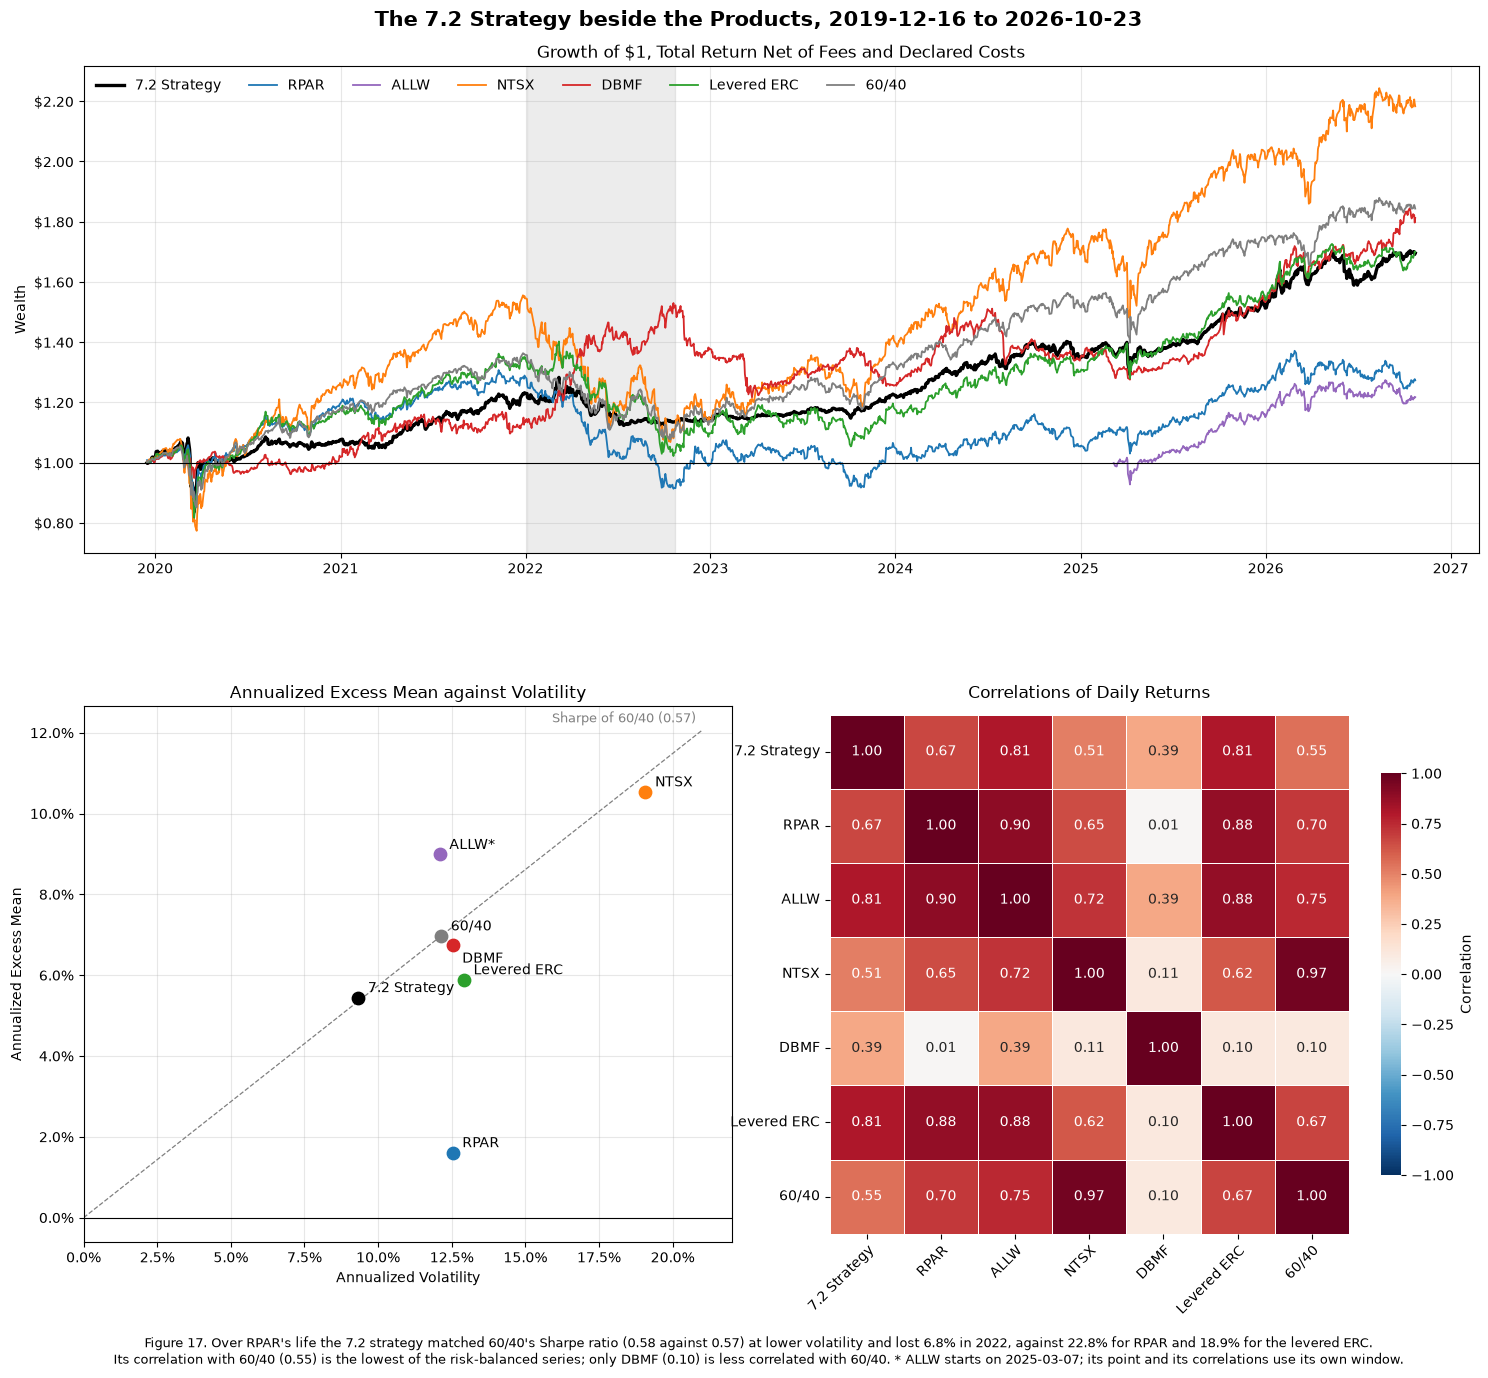

In [108]:
fig, axes = plt.subplot_mosaic([["growth", "growth"], ["scatter", "corr"]], figsize = (18, 14), gridspec_kw = {"height_ratios": [1, 1.1]})

series_colors = dict(zip(COMPARISON, ["black", "tab:blue", "tab:purple", "tab:orange", "tab:red", "tab:green", "tab:gray"]))

#growth of $1 from each series' first return; ALLW from 2025-03-07
ax = axes["growth"]
for series in COMPARISON:
    path = (1 + comparison_returns[series].dropna()).cumprod()
    ax.plot(path.index, path, color = series_colors[series], linewidth = 2.4 if series == "7.2 Strategy" else 1.3, label = series)
ax.axvspan(pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-24"), color = "gray", alpha = 0.15)
ax.axhline(1, color = "black", linewidth = 0.8)
ax.set(title = "Growth of $1, Total Return Net of Fees and Declared Costs", ylabel = "Wealth")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:.2f}"))
ax.legend(frameon = False, ncol = 7, loc = "upper left")
ax.grid(alpha = 0.3)

#annualized excess mean against volatility; the dashed ray is 60/40's Sharpe ratio on the common window
ax = axes["scatter"]
excess_common = comparison_returns.sub(returns.loc[comparison_returns.index, "SHV"], axis = 0)
points = pd.DataFrame({"Volatility": excess_common.std() * np.sqrt(252), "Excess Mean": excess_common.mean() * 252})
for series, row in points.iterrows():
    ax.scatter(row["Volatility"], row["Excess Mean"], s = 80, color = series_colors[series], zorder = 3)
    ax.annotate(series + ("*" if series == "ALLW" else ""), (row["Volatility"], row["Excess Mean"]), xytext = (7, -13) if series == "DBMF" else (7, 4), textcoords = "offset points")
vol_line = np.linspace(0, points["Volatility"].max() * 1.1, 2)
ax.plot(vol_line, vol_line * common_stats.loc["60/40", "Sharpe Ratio"], color = "gray", linestyle = "--", linewidth = 0.9)
ax.annotate(f"Sharpe of 60/40 ({common_stats.loc['60/40', 'Sharpe Ratio']:.2f})", (vol_line[1], vol_line[1] * common_stats.loc["60/40", "Sharpe Ratio"]),
            xytext = (-4, 6), textcoords = "offset points", ha = "right", fontsize = 9, color = "gray")
ax.set(title = "Annualized Excess Mean against Volatility", xlabel = "Annualized Volatility", ylabel = "Annualized Excess Mean", xlim = (0, None))
ax.axhline(0, color = "black", linewidth = 0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(alpha = 0.3)

ax = axes["corr"]
sns.heatmap(comparison_corr, annot = True, fmt = ".2f", cmap = "RdBu_r", vmin = -1, vmax = 1, center = 0, square = True, linewidths = 0.5,
            cbar_kws = {"label": "Correlation", "shrink": 0.75}, ax = ax)
ax.set_title("Correlations of Daily Returns", pad = 12)
ax.tick_params(axis = "x", labelrotation = 45)
plt.setp(ax.get_xticklabels(), ha = "right", rotation_mode = "anchor")
ax.tick_params(axis = "y", labelrotation = 0)

fig.suptitle(f"The 7.2 Strategy beside the Products, {COMMON_START} to {COMMON_END}", fontsize = 15, fontweight = "bold")

fig.text(0.5, 0.01, f"Figure 17. Over RPAR's life the 7.2 strategy matched 60/40's Sharpe ratio ({common_stats.loc['7.2 Strategy', 'Sharpe Ratio']:.2f} against {common_stats.loc['60/40', 'Sharpe Ratio']:.2f}) at lower volatility and lost {-common_stats.loc['7.2 Strategy', '2022 Return']:.1%} in 2022, "
         f"against {-common_stats.loc['RPAR', '2022 Return']:.1%} for RPAR and {-common_stats.loc['Levered ERC', '2022 Return']:.1%} for the levered ERC.\n"
         f"Its correlation with 60/40 ({common_stats.loc['7.2 Strategy', 'Correlation with 60/40']:.2f}) is the lowest of the risk-balanced series; only DBMF (0.10) is less correlated with 60/40. "
         "* ALLW starts on 2025-03-07; its point and its correlations use its own window.",
         ha = "center", va = "bottom", fontsize = 9, color = "black")

fig.subplots_adjust(bottom = 0.1, hspace = 0.3, wspace = 0.15, top = 0.94)
plt.show()

> **Window: `RPAR`'s life, 2019-12-16 to 2026-10-23.**
>
> * **Why:** it is the longest window shared by every series except `ALLW`, and it contains both 2020 and 2022.
> * **`ALLW`:** it starts 2025-03-07, so it is compared with 60/40 on its own dates.
> * **Costs:** the strategy and the levered ERC are net of the 7.1 costs, 0.23% and 0.45% a year here. The levered ERC's 1.55x is a hindsight choice.
>
> | | Mean | Volatility | Sharpe | Max drawdown | 2022 | Correlation with 60/40 |
> |---|---:|---:|---:|---:|---:|---:|
> | 7.2 strategy (net) | 8.2% | 9.3% | 0.58 | −22.7% | −6.8% | 0.55 |
> | `RPAR` | 4.3% | 12.6% | 0.13 | −30.1% | −22.8% | 0.70 |
> | `ALLW`* | 12.8% | 12.1% | 0.74 | −8.8% | — | 0.75 |
> | `NTSX` | 13.3% | 19.1% | 0.55 | −31.3% | −25.8% | 0.97 |
> | `DBMF` | 9.5% | 12.5% | 0.54 | −20.4% | +21.5% | 0.10 |
> | Levered ERC (net) | 8.6% | 12.9% | 0.46 | −27.1% | −18.9% | 0.67 |
> | 60/40 | 9.7% | 12.1% | 0.57 | −21.0% | −16.4% | 1.00 |
>
> \* From 2025-03-07. 60/40's Sharpe ratio over the same dates was 0.84.
>
> **Figure 17** puts every series on this window: growth paths, risk against return with 60/40's Sharpe ray, and daily correlations. The strategy sits on 60/40's ray at lower volatility, and `RPAR` sits far below it.
>
> * **The 7.2 strategy:**
>   * It matches 60/40's Sharpe ratio at lower volatility and has the best 2022 after `DBMF`.
>   * Its drawdown is 1.7 points deeper than 60/40's, because March 2020 is inside this window and 2008 is not.
> * **Levered ERC against `RPAR`:**
>   * A Sharpe ratio 0.33 higher, a correlation of 0.88, and a 2022 of −18.9% against −22.8%.
>   * `RPAR` trailed this simplified benchmark built in hindsight. The gap mixes implementation, design, financing, fees and unmodeled exposures (4.4).
> * **`NTSX`:** a levered 60/40, with the deepest 2022 loss.
> * **`DBMF`:** the only diversifier: 0.01 with `RPAR`, 0.10 with 60/40, and +21.5% in 2022.
> * **`ALLW`, on its own 411 days:** 0.74 against 60/40's 0.84, the strategy's 1.06 and `DBMF`'s 1.50. With a Sharpe standard error near 0.8, none of these differences is meaningful.
> * **Correlations:**
>   * `RPAR`, `ALLW` and the levered ERC form one cluster (0.88–0.90).
>   * The strategy sits partly outside it (0.67 with `RPAR`, 0.55 with 60/40) and shares a trend component with `DBMF` (0.39).
>
> **The tables.**
>
> * ***`ALLW`'s window:*** puts every series on `ALLW`'s 411 days, so its short record is compared like for like rather than against longer samples.
> * ***Correlations of daily returns:*** show which products are really the same exposure.

## 7.4

Judge three things separately: the allocation rule, `RPAR`'s implementation of it, and your own design. Apply the criteria from 7.1 and say which passed. Say how much weight `ALLW`'s record can carry given its length, and name one observable result over the next year that would reverse your recommendation. Half a page.


In [109]:
#the three subjects of 7.4, each on its longest window and on the 7.3 common window; the other products for reference
levered_erc_full_net = levered_erc_net.loc[backtest_returns.index[0]:]
criteria_cases = {("The rule: levered ERC, net", "Full backtest"): levered_erc_full_net,
                  ("The rule: levered ERC, net", "Common window"): levered_erc_net.loc[COMMON_START:COMMON_END],
                  ("RPAR", "Common window (its life)"): returns.loc[COMMON_START:COMMON_END, "RPAR"],
                  ("7.2 strategy, net", "Full backtest"): strategy_net,
                  ("7.2 strategy, net", "Common window"): strategy_net.loc[COMMON_START:COMMON_END],
                  ("ALLW", "Its life"): returns["ALLW"].dropna(),
                  ("NTSX", "Common window"): returns.loc[COMMON_START:COMMON_END, "NTSX"],
                  ("DBMF", "Common window"): returns.loc[COMMON_START:COMMON_END, "DBMF"]}

criteria_results = pd.DataFrame({case: project_utils.criteria_check(series, returns["60/40"], returns["SHV"], max_correlation = MAX_CORRELATION_WITH_6040)
                                 for case, series in criteria_cases.items()}).T
criteria_results.index.names = ["Subject", "Window"]

pass_cols = ["1. Sharpe", "2. Drawdown", "3. 2022", "4. Correlation"]
criteria_results["Passed"] = [f"{sum(bool(row[col]) for col in pass_cols if pd.notna(row[col]))} of {row[pass_cols].notna().sum()}"
                              for _, row in criteria_results.iterrows()]

def pass_mark(x):
    return "—" if not isinstance(x, (bool, np.bool_)) else ("Pass" if x else "Fail")

display(criteria_results.style.format({"Start": format_date, "End": format_date, "Sharpe": "{:.2f}", "Hurdle": "{:.2f}",
                                       "Max Drawdown": "{:.1%}", "60/40 Max Drawdown": "{:.1%}", "2022 Return": "{:.1%}", "60/40 2022 Return": "{:.1%}",
                                       "Correlation": "{:.2f}", **{col: pass_mark for col in pass_cols}}, na_rep = "—")
                              .map(lambda x: "color: tab:red; font-weight: bold" if isinstance(x, (bool, np.bool_)) and not x else "", subset = pass_cols)
                              .set_caption("The 7.1 criteria, each against 60/40 over the same dates. ALLW has no 2022, so it is tested on three"))

#how much ALLW's record can say: an annualized Sharpe ratio has a standard error of about 1 / sqrt(years), and the difference
#between two Sharpe ratios with correlation rho about sqrt(2 (1 - rho) / years)
allw_years = returns["ALLW"].count() / 252
allw_rho = criteria_results.loc[("ALLW", "Its life"), "Correlation"]
print(f"ALLW: {returns['ALLW'].count()} days ({allw_years:.2f} years). \n"
      f"Standard error of its Sharpe ratio about {1 / np.sqrt(allw_years):.2f}; \n" 
      f"Of its difference from 60/40's (correlation {allw_rho:.2f}) about {np.sqrt(2 * (1 - allw_rho) / allw_years):.2f}. \n"
      f"Years for a difference of 0.3 to reach two standard errors: about {2 * (1 - allw_rho) * (2 / 0.3) ** 2:.0f}")

#the 7.4 reversal test applied to the backtest: six-month stretches in which SPY and TLT each lost more than 10%
monthly_check = pd.concat([returns[["SPY", "TLT", "60/40"]], strategy_net.rename("7.2 Strategy")], axis = 1).dropna()
monthly_check = (1 + monthly_check).groupby(monthly_check.index.to_period("M")).prod()
six_month = monthly_check.rolling(6).apply(np.prod, raw = True) - 1
joint_selloffs = six_month[(six_month["SPY"] < -0.10) & (six_month["TLT"] < -0.10)]

display(joint_selloffs.style.format("{:.1%}")
                      .set_caption("Six-month stretches, by ending month, in which SPY and TLT each lost more than 10%"))

#if the common window governs, the lower-risk 7.2 variants against the same criteria (chosen after seeing results, so a revision, not a test)
lower_risk_variants = {"8% target": {"target_vol": 0.08}, "1.5x cap": {"max_leverage": 1.5}}
variant_checks = {}
for name, settings in lower_risk_variants.items():
    targets, _ = project_utils.trend_filtered_positions(returns[RP_ASSETS], excess_returns[RP_ASSETS], early_erc_weights, **settings)
    gross, positions, turnover = project_utils.levered_backtest(returns[RP_ASSETS], targets, returns["SHV"], leverage = 1.0)
    net = project_utils.net_of_costs(gross, positions, turnover, COST_PER_TURNOVER, BORROW_SPREAD)
    variant_checks[name] = project_utils.criteria_check(net.loc[COMMON_START:COMMON_END], returns["60/40"], returns["SHV"], max_correlation = MAX_CORRELATION_WITH_6040)

variant_checks = pd.DataFrame(variant_checks).T[["Sharpe", "Hurdle", "Max Drawdown", "60/40 Max Drawdown", "2022 Return", "Correlation"] + pass_cols]
display(variant_checks.style.format({"Sharpe": "{:.2f}", "Hurdle": "{:.2f}", "Max Drawdown": "{:.1%}", "60/40 Max Drawdown": "{:.1%}",
                                     "2022 Return": "{:.1%}", "Correlation": "{:.2f}", **{col: pass_mark for col in pass_cols}})
                          .set_caption("Lower-risk 7.2 variants on the common window, net of costs"))

ALLW: 411 days (1.63 years). 
Standard error of its Sharpe ratio about 0.78; 
Of its difference from 60/40's (correlation 0.75) about 0.55. 
Years for a difference of 0.3 to reach two standard errors: about 22


,SPY,TLT,60/40,7.2 Strategy
Date,,,,
2022-06,-20.0%,-21.9%,-16.0%,-6.6%
2022-09,-20.2%,-21.6%,-15.9%,-8.8%


,Sharpe,Hurdle,Max Drawdown,60/40 Max Drawdown,2022 Return,Correlation,1. Sharpe,2. Drawdown,3. 2022,4. Correlation
8% target,0.58,0.31,-18.8%,-21.0%,-5.2%,0.55,Pass,Pass,Pass,Pass
1.5x cap,0.65,0.32,-17.2%,-21.0%,-6.8%,0.55,Pass,Pass,Pass,Pass


> **Criterion 1 is the CAPM relation $\text{SR}_i = \rho\,\text{SR}_m$, with 60/40 as the benchmark:** clearing it means a positive alpha against 60/40.
>
> **The allocation rule (levered ERC, net): passes 3 of 4 on the full backtest, 2 of 4 on the common window.**
>
> * It clears the Sharpe hurdle (0.52 against 0.40) and is not a re-levered 60/40 (correlation 0.61).
> * It fails 2022 on both windows (−18.9% against −16.4%). Leverage on duration-heavy weights is exposed to stocks and bonds falling together.
> * We would not run it unconditioned.
>
> **`RPAR` as built: passes 1 of 4.**
>
> * Sharpe ratio 0.13 against a hurdle of 0.40, drawdown −30.1% against −21.0%, and 2022 −22.8% against −16.4%.
> * It trails the levered ERC by 4.7% a year and its own factor replica by 3.5%.
> * Both are gaps to simplified benchmarks. Separating implementation from design and unmodeled exposure needs the issuer's sleeve holdings and total-return index.
>
> **Our design: the verdict depends on which window governs.**
>
> * **Full backtest:** it passes all four (Sharpe ratio 0.65 against 0.24, drawdown −22.7% against −31.4%, 2022 −6.8% against −16.4%, correlation 0.39).
> * **Common window:** it fails the drawdown test by 1.7 points, on one month (March 2020) inside a 6.9-year sample.
> * **The trade-off:** the full backtest is the larger sample, but the design was chosen with all of it in view. The common window is closer to what an investor buys today.
> * **The recommendation:**
>   * If the full backtest governs, we run it at the 10% target.
>   * If the common window governs, we would not run it as declared. The 8% and 1.5x-cap variants pass all four there, but adopting one now would be a dated revision.
>   * Our reading favors the full backtest, a judgment the criteria left open.
>
> **`ALLW`'s record carries little weight.**
>
> * Over 411 days, its Sharpe gap to 60/40 has a standard error of about 0.55, so resolving a 0.3 gap would take about 22 years. It also has no 2022.
> * Its 0.88–0.90 correlation with `RPAR` and the levered ERC suggests the rule's 2022 failure applies to it too.
> * `DBMF` passes all four and is the natural sleeve for a revision.
>
> **What would reverse the recommendation:** within the next year, a six-month stretch in which `SPY` and `TLT` each lose more than 10% (the 2022 pattern) and the strategy, net of costs, still loses more than 60/40. In the data this happened only in 2022, when the strategy lost 6.6% and 8.8% against about 16%.
>
> **The tables.**
>
> * ***The criteria table:*** applies each criterion to each subject on each window, so every pass and fail above can be checked.
> * ***Six-month stretches in which `SPY` and `TLT` each lost more than 10%:*** the history behind the reversal test. It occurred only in 2022, and the strategy passed it then.
> * ***Lower-risk variants on the common window:*** the evidence behind the conditional recommendation, showing which versions pass if the common window governs.

***


## AI Usage Disclosure

**Tool.** Claude (Anthropic), through Claude Code.

**Where it was most helpful.**

* **Code:** it wrote most of the code in this notebook and `project_utils.py`, including the regressions, replications, backtests, VaR and CVaR forecasts, attributions, regime tests, the Section 7 strategy and the figures.
* **Writing:** it drafted most of the written answers.
* **Section 7 design:** it proposed the criteria, costs and strategy, which we reviewed and adopted.

**How we verified it.** We reviewed the code and text against the lecture notes and re-ran the notebook, checking the quoted numbers against the output. That review changed the analysis:

* 3.3 now uses the 2.2 betas.
* VaR and CVaR follow the lecture's lower-quantile and tail-mean definitions.
* ERC convergence is tested at every rebalance date.
* Section 7's conclusions about `RPAR`, and the window that governs the recommendation, are qualified.

The group is responsible for the final methodology, interpretations and recommendations.